In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import zipfile
import os
import shutil

# Uploaded ZIP
ZIP_PATH = "/content/Soil.v1i.folder.zip"

# New clean dataset
CLEAN_DIR = "/content/soil_dataset_6class"

# Remove old clean dataset if it exists
if os.path.exists(CLEAN_DIR):
    shutil.rmtree(CLEAN_DIR)

os.makedirs(CLEAN_DIR, exist_ok=True)

# Classes we want
KEEP_CLASSES = {
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
}

# Splits
SPLITS = {"train", "valid", "test"}

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    for file_path in zip_ref.namelist():

        # Normalize path
        parts = file_path.replace("\\", "/").split("/")

        # Expected:
        # Soil.v1i.folder/train/Alluvial_Soil/image.jpg
        if len(parts) < 4:
            continue

        split = parts[-3]
        soil_class = parts[-2]
        filename = parts[-1]

        # Keep only required splits/classes/images
        if split not in SPLITS:
            continue

        if soil_class not in KEEP_CLASSES:
            continue

        if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            continue

        # Destination
        destination_dir = os.path.join(
            CLEAN_DIR,
            split,
            soil_class
        )

        os.makedirs(destination_dir, exist_ok=True)

        destination_file = os.path.join(
            destination_dir,
            filename
        )

        # Extract image
        with zip_ref.open(file_path) as source:
            with open(destination_file, "wb") as target:
                shutil.copyfileobj(source, target)

print("✅ Clean 6-class dataset created!")
print("Location:", CLEAN_DIR)

✅ Clean 6-class dataset created!
Location: /content/soil_dataset_6class


In [ ]:
import zipfile
import os
import shutil

ZIP_PATH = "/content/Soil.v1i.folder.zip"
CLEAN_DIR = "/content/soil_dataset_6class"

# Remove the incorrectly created dataset
if os.path.exists(CLEAN_DIR):
    shutil.rmtree(CLEAN_DIR)

# Classes we want
KEEP_CLASSES = {
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
}

VALID_SPLITS = {"train", "valid", "test"}

os.makedirs(CLEAN_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:

    for file_path in zip_ref.namelist():

        # Example:
        # train/Alluvial_Soil/image.jpg
        parts = file_path.replace("\\", "/").split("/")

        if len(parts) != 3:
            continue

        split = parts[0]
        soil_class = parts[1]
        filename = parts[2]

        # Keep only train/valid/test
        if split not in VALID_SPLITS:
            continue

        # Ignore Yellow_Soil
        if soil_class not in KEEP_CLASSES:
            continue

        # Keep image files only
        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        ):
            continue

        # Create destination folder
        destination_dir = os.path.join(
            CLEAN_DIR,
            split,
            soil_class
        )

        os.makedirs(destination_dir, exist_ok=True)

        destination_file = os.path.join(
            destination_dir,
            filename
        )

        # Extract image
        with zip_ref.open(file_path) as source:
            with open(destination_file, "wb") as target:
                shutil.copyfileobj(source, target)

print("✅ Clean 6-class dataset created successfully!")
print("📁 Location:", CLEAN_DIR)

✅ Clean 6-class dataset created successfully!
📁 Location: /content/soil_dataset_6class


In [ ]:
import os

CLEAN_DIR = "/content/soil_dataset_6class"

expected_classes = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

total_images = 0

for split in ["train", "valid", "test"]:

    print(f"\n===== {split.upper()} =====")

    split_total = 0

    for soil_class in expected_classes:

        class_path = os.path.join(CLEAN_DIR, split, soil_class)

        if not os.path.exists(class_path):
            print(f"❌ Missing: {soil_class}")
            continue

        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            )
        ]

        count = len(images)

        print(f"{soil_class:20s}: {count}")

        split_total += count

    print(f"TOTAL {split}: {split_total}")
    total_images += split_total

print("\n" + "=" * 40)
print(f"TOTAL DATASET IMAGES: {total_images}")
print("=" * 40)


===== TRAIN =====
Alluvial_Soil       : 549
Arid_Soil           : 224
Black_Soil          : 926
Laterite_Soil       : 169
Mountain_Soil       : 147
Red_Soil            : 897
TOTAL train: 2912

===== VALID =====
Alluvial_Soil       : 80
Arid_Soil           : 26
Black_Soil          : 103
Laterite_Soil       : 21
Mountain_Soil       : 24
Red_Soil            : 102
TOTAL valid: 356

===== TEST =====
Alluvial_Soil       : 62
Arid_Soil           : 29
Black_Soil          : 122
Laterite_Soil       : 24
Mountain_Soil       : 20
Red_Soil            : 123
TOTAL test: 380

TOTAL DATASET IMAGES: 3648


In [ ]:
import os
import hashlib
from collections import defaultdict

DATASET_DIR = "/content/soil_dataset_6class"

splits = ["train", "valid", "test"]

def get_file_hash(filepath):
    """Calculate exact file hash."""
    hasher = hashlib.md5()

    with open(filepath, "rb") as f:
        while True:
            chunk = f.read(8192)
            if not chunk:
                break
            hasher.update(chunk)

    return hasher.hexdigest()


# Store hashes
hashes = defaultdict(list)

for split in splits:

    split_path = os.path.join(DATASET_DIR, split)

    for soil_class in os.listdir(split_path):

        class_path = os.path.join(split_path, soil_class)

        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):

            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            ):
                continue

            filepath = os.path.join(class_path, filename)

            file_hash = get_file_hash(filepath)

            hashes[file_hash].append(
                (split, soil_class, filename)
            )


# Find exact duplicates
duplicate_groups = []

for file_hash, files in hashes.items():

    if len(files) > 1:
        duplicate_groups.append(files)


print("=" * 60)
print("EXACT DUPLICATE IMAGE CHECK")
print("=" * 60)

print("Unique image hashes :", len(hashes))
print("Duplicate groups    :", len(duplicate_groups))

duplicate_images = sum(
    len(group) for group in duplicate_groups
)

print("Images involved     :", duplicate_images)


# Check specifically cross-split duplicates
cross_split_groups = []

for group in duplicate_groups:

    group_splits = set(item[0] for item in group)

    if len(group_splits) > 1:
        cross_split_groups.append(group)


print("\n" + "=" * 60)
print("CROSS-SPLIT DUPLICATE CHECK")
print("=" * 60)

print("Cross-split groups  :", len(cross_split_groups))

cross_split_images = sum(
    len(group) for group in cross_split_groups
)

print("Images involved     :", cross_split_images)


# Show examples
if cross_split_groups:

    print("\nExamples:\n")

    for i, group in enumerate(cross_split_groups[:10], 1):

        print(f"Group {i}:")

        for split, soil_class, filename in group:

            print(
                f"  {split:5s} | "
                f"{soil_class:15s} | "
                f"{filename}"
            )

        print()

else:

    print("\n✅ No exact duplicate images found across splits.")

EXACT DUPLICATE IMAGE CHECK
Unique image hashes : 3648
Duplicate groups    : 0
Images involved     : 0

CROSS-SPLIT DUPLICATE CHECK
Cross-split groups  : 0
Images involved     : 0

✅ No exact duplicate images found across splits.


In [ ]:
# Install image similarity library
!pip -q install imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 5.7 MB/s eta 0:00:00


In [ ]:
import os
import imagehash
from PIL import Image
from collections import defaultdict
from itertools import combinations

DATASET_DIR = "/content/soil_dataset_6class"

splits = ["train", "valid", "test"]

# ---------------------------------------------------------
# 1. Calculate perceptual hashes
# ---------------------------------------------------------

image_hashes = []

for split in splits:

    split_path = os.path.join(DATASET_DIR, split)

    for soil_class in os.listdir(split_path):

        class_path = os.path.join(split_path, soil_class)

        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):

            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            ):
                continue

            filepath = os.path.join(class_path, filename)

            try:
                with Image.open(filepath) as img:
                    img = img.convert("RGB")

                    # Perceptual hash
                    phash = imagehash.phash(img)

                image_hashes.append({
                    "hash": phash,
                    "split": split,
                    "class": soil_class,
                    "filename": filename,
                    "filepath": filepath
                })

            except Exception as e:
                print("Error:", filepath, e)


print("Images processed:", len(image_hashes))


# ---------------------------------------------------------
# 2. Compare images across different splits
# ---------------------------------------------------------

THRESHOLD = 6

near_duplicates = []

print("\nChecking cross-split similarity...")

for i in range(len(image_hashes)):

    img1 = image_hashes[i]

    for j in range(i + 1, len(image_hashes)):

        img2 = image_hashes[j]

        # We ONLY care about different splits
        if img1["split"] == img2["split"]:
            continue

        distance = img1["hash"] - img2["hash"]

        if distance <= THRESHOLD:

            near_duplicates.append({
                "distance": distance,
                "image1": img1,
                "image2": img2
            })


# ---------------------------------------------------------
# 3. Sort results
# ---------------------------------------------------------

near_duplicates.sort(
    key=lambda x: x["distance"]
)


# ---------------------------------------------------------
# 4. Display results
# ---------------------------------------------------------

print("\n" + "=" * 60)
print("NEAR-DUPLICATE CHECK")
print("=" * 60)

print("Similarity threshold :", THRESHOLD)
print("Near-duplicate pairs :", len(near_duplicates))


if len(near_duplicates) == 0:

    print("\n✅ No suspicious near-duplicates found across splits.")

else:

    print("\n⚠️ Suspicious pairs found.\n")

    for i, pair in enumerate(near_duplicates[:30], 1):

        img1 = pair["image1"]
        img2 = pair["image2"]

        print(f"Pair {i} | Distance: {pair['distance']}")

        print(
            f"  {img1['split']:5s} | "
            f"{img1['class']:15s} | "
            f"{img1['filename']}"
        )

        print(
            f"  {img2['split']:5s} | "
            f"{img2['class']:15s} | "
            f"{img2['filename']}"
        )

        print()

Images processed: 3648

Checking cross-split similarity...

NEAR-DUPLICATE CHECK
Similarity threshold : 6
Near-duplicate pairs : 334

⚠️ Suspicious pairs found.

Pair 1 | Distance: 0
  train | Black_Soil      | b-1296-_jpeg.rf.d58d62732aab6c084fbbda64ae7d85a0.jpg
  valid | Black_Soil      | b-1268-_jpeg.rf.22f58514ba24a1d6b5045840cbd8bd2a.jpg

Pair 2 | Distance: 0
  train | Black_Soil      | b-937-_jpeg.rf.1c5b87059dfd9dae7d4fb1216c629a27.jpg
  test  | Black_Soil      | b-1597-_jpeg.rf.64a587f089c3fd30cd1f95a29f75e221.jpg

Pair 3 | Distance: 0
  train | Black_Soil      | b-1005-_jpeg.rf.df8db93b3ef85eba592dc4cff906cc15.jpg
  test  | Black_Soil      | 0128408182_jpeg.rf.ef4a2d27e8658b15aa660f9b88052642.jpg

Pair 4 | Distance: 0
  train | Black_Soil      | b-935-_jpeg.rf.7b420eea9fbfff6c31746a74d3053f12.jpg
  valid | Black_Soil      | b-836-_jpeg.rf.054752f241df8fd56193aa3027a6173d.jpg

Pair 5 | Distance: 0
  train | Black_Soil      | b-1638-_jpeg.rf.ce20ce7f6a879484a086b26eeb107d22.jpg


In [ ]:
import os
import math
from PIL import Image, ImageDraw, ImageFont

# We already have:
# near_duplicates
# DATASET_DIR

OUTPUT_DIR = "/content/near_duplicate_report"

if os.path.exists(OUTPUT_DIR):
    import shutil
    shutil.rmtree(OUTPUT_DIR)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# Take first 30 strongest pairs
pairs_to_show = [
    p for p in near_duplicates
    if p["distance"] == 0
][:30]


# Create contact sheet
thumb_w = 300
thumb_h = 330

cols = 2
rows = math.ceil(len(pairs_to_show) / cols)

sheet = Image.new(
    "RGB",
    (cols * thumb_w, rows * thumb_h),
    "white"
)

draw = ImageDraw.Draw(sheet)


for i, pair in enumerate(pairs_to_show):

    img1 = pair["image1"]
    img2 = pair["image2"]

    try:

        im1 = Image.open(img1["filepath"]).convert("RGB")
        im2 = Image.open(img2["filepath"]).convert("RGB")

        im1.thumbnail((280, 220))
        im2.thumbnail((280, 220))

        x = (i % cols) * thumb_w
        y = (i // cols) * thumb_h

        # First image
        sheet.paste(
            im1,
            (x + 10, y + 5)
        )

        # Second image
        sheet.paste(
            im2,
            (x + 10, y + 230)
        )

        # Labels
        label = (
            f"PAIR {i+1} | distance={pair['distance']}\n"
            f"{img1['split']} - {img1['class']}\n"
            f"{img2['split']} - {img2['class']}"
        )

        draw.text(
            (x + 10, y + 5),
            label,
            fill="red"
        )

    except Exception as e:
        print("Error:", e)


report_path = os.path.join(
    OUTPUT_DIR,
    "near_duplicate_pairs.jpg"
)

sheet.save(report_path, quality=95)

print("✅ Report created:")
print(report_path)

✅ Report created:
/content/near_duplicate_report/near_duplicate_pairs.jpg


In [ ]:
from PIL import Image, ImageDraw
import os
import math
import shutil

OUTPUT_DIR = "/content/near_duplicate_report"

if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)

os.makedirs(OUTPUT_DIR, exist_ok=True)


pairs_to_show = [
    p for p in near_duplicates
    if p["distance"] == 0
][:30]


W = 900
PAIR_H = 430

sheet = Image.new(
    "RGB",
    (W, len(pairs_to_show) * PAIR_H),
    "white"
)

draw = ImageDraw.Draw(sheet)


for i, pair in enumerate(pairs_to_show):

    img1 = pair["image1"]
    img2 = pair["image2"]

    im1 = Image.open(img1["filepath"]).convert("RGB")
    im2 = Image.open(img2["filepath"]).convert("RGB")

    im1.thumbnail((380, 330))
    im2.thumbnail((380, 330))

    y = i * PAIR_H

    # Images side by side
    sheet.paste(im1, (10, y + 50))
    sheet.paste(im2, (470, y + 50))

    # Labels above
    draw.text(
        (10, y + 10),
        f"{i+1}. {img1['split']} / {img1['class']}",
        fill="black"
    )

    draw.text(
        (470, y + 10),
        f"{img2['split']} / {img2['class']}",
        fill="black"
    )

    draw.text(
        (10, y + 390),
        f"Perceptual distance: {pair['distance']}",
        fill="red"
    )


report_path = os.path.join(
    OUTPUT_DIR,
    "near_duplicate_pairs.jpg"
)

sheet.save(report_path, quality=95)

print("✅ Visual report created:")
print(report_path)

✅ Visual report created:
/content/near_duplicate_report/near_duplicate_pairs.jpg


In [ ]:
from IPython.display import display
from PIL import Image

display(Image.open("/content/near_duplicate_report/near_duplicate_pairs.jpg"))

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from collections import Counter

zero_pairs = [
    p for p in near_duplicates
    if p["distance"] == 0
]

print("Distance = 0 pairs:", len(zero_pairs))

same_class = 0
different_class = 0

class_pairs = Counter()

for p in zero_pairs:
    a = p["image1"]
    b = p["image2"]

    if a["class"] == b["class"]:
        same_class += 1
    else:
        different_class += 1
        pair = tuple(sorted([a["class"], b["class"]]))
        class_pairs[pair] += 1

print("Same-class pairs:", same_class)
print("Different-class pairs:", different_class)

print("\nCross-class pairs:")
for pair, count in class_pairs.most_common():
    print(f"{pair[0]} ↔ {pair[1]} : {count}")

Distance = 0 pairs: 65
Same-class pairs: 55
Different-class pairs: 10

Cross-class pairs:
Black_Soil ↔ Red_Soil : 6
Alluvial_Soil ↔ Red_Soil : 3
Alluvial_Soil ↔ Black_Soil : 1


In [ ]:
from PIL import Image, ImageDraw
import os
import shutil

OUTPUT_DIR = "/content/cross_class_duplicate_report"

if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Only distance-0 AND different-class pairs
cross_class_zero = [
    p for p in near_duplicates
    if p["distance"] == 0
    and p["image1"]["class"] != p["image2"]["class"]
]

print("Cross-class distance-0 pairs:", len(cross_class_zero))

W = 1000
PAIR_H = 480

sheet = Image.new(
    "RGB",
    (W, len(cross_class_zero) * PAIR_H),
    "white"
)

draw = ImageDraw.Draw(sheet)

for i, pair in enumerate(cross_class_zero):

    img1 = pair["image1"]
    img2 = pair["image2"]

    im1 = Image.open(img1["filepath"]).convert("RGB")
    im2 = Image.open(img2["filepath"]).convert("RGB")

    im1.thumbnail((430, 350))
    im2.thumbnail((430, 350))

    y = i * PAIR_H

    # Left image
    sheet.paste(im1, (20, y + 70))

    # Right image
    sheet.paste(im2, (530, y + 70))

    # Labels
    draw.text(
        (20, y + 15),
        f"PAIR {i+1} | {img1['split']} | {img1['class']}",
        fill="black"
    )

    draw.text(
        (530, y + 15),
        f"PAIR {i+1} | {img2['split']} | {img2['class']}",
        fill="black"
    )

    draw.text(
        (20, y + 430),
        f"Distance = {pair['distance']}",
        fill="red"
    )

report_path = os.path.join(
    OUTPUT_DIR,
    "cross_class_pairs.jpg"
)

sheet.save(report_path, quality=95)

print("✅ Report saved:")
print(report_path)

Cross-class distance-0 pairs: 10
✅ Report saved:
/content/cross_class_duplicate_report/cross_class_pairs.jpg


In [ ]:
from IPython.display import display
from PIL import Image

display(
    Image.open(
        "/content/cross_class_duplicate_report/cross_class_pairs.jpg"
    )
)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import os
import shutil

DATASET_DIR = "/content/soil_dataset_6class"

QUARANTINE_DIR = "/content/soil_quarantine_cross_class"

# Start fresh
if os.path.exists(QUARANTINE_DIR):
    shutil.rmtree(QUARANTINE_DIR)

os.makedirs(QUARANTINE_DIR, exist_ok=True)


# ---------------------------------------------------------
# Find cross-class distance-0 pairs
# ---------------------------------------------------------

cross_class_zero = [
    p for p in near_duplicates
    if p["distance"] == 0
    and p["image1"]["class"] != p["image2"]["class"]
]


# ---------------------------------------------------------
# Decide which files to quarantine
#
# Rule:
# - Keep training images
# - Remove suspicious validation/test images
# - If both are validation/test, quarantine both
# ---------------------------------------------------------

files_to_quarantine = {}

for pair in cross_class_zero:

    for key in ["image1", "image2"]:

        img = pair[key]

        # Never quarantine a training image automatically
        if img["split"] == "train":
            continue

        relative_path = os.path.relpath(
            img["filepath"],
            DATASET_DIR
        )

        files_to_quarantine[relative_path] = img


print("Cross-class duplicate pairs:", len(cross_class_zero))
print("Evaluation images to quarantine:", len(files_to_quarantine))


# ---------------------------------------------------------
# Copy suspicious files to quarantine folder
# ---------------------------------------------------------

for relative_path, img in files_to_quarantine.items():

    destination = os.path.join(
        QUARANTINE_DIR,
        relative_path
    )

    os.makedirs(
        os.path.dirname(destination),
        exist_ok=True
    )

    shutil.copy2(
        img["filepath"],
        destination
    )


# ---------------------------------------------------------
# Print files
# ---------------------------------------------------------

print("\nFiles quarantined:\n")

for relative_path in sorted(files_to_quarantine):
    print(relative_path)

print("\n✅ Quarantine complete.")
print("Original dataset was NOT modified.")
print("Quarantine location:", QUARANTINE_DIR)

Cross-class duplicate pairs: 10
Evaluation images to quarantine: 9

Files quarantined:

test/Black_Soil/b-890-_jpeg.rf.3e75a2a5ced78886a20064b850dccdc4.jpg
test/Red_Soil/r-169-_jpeg.rf.4732c427d95d9d403d2995e1c1c0c4de.jpg
test/Red_Soil/r-235-_jpeg.rf.fa2feb3bc508f0a46fde2201a6e9859b.jpg
test/Red_Soil/r-502-_jpeg.rf.dbc599a969a4b0490b437962c0461dd4.jpg
test/Red_Soil/r-699-_jpeg.rf.901b53d87077808012e4f05b33032a0e.jpg
test/Red_Soil/r-773-_jpeg.rf.9d96f472502a9766076729cc5ecca057.jpg
valid/Black_Soil/165_jpg.rf.239d2d4ea4099a520f0b2f077433137a.jpg
valid/Red_Soil/4_jpg.rf.ba7e3de98084b52944fa052d9b80b6d4.jpg
valid/Red_Soil/r-639-_jpeg.rf.8f4f300acdbdc21fe9050b0b73bf2d1d.jpg

✅ Quarantine complete.
Original dataset was NOT modified.
Quarantine location: /content/soil_quarantine_cross_class


In [ ]:
from collections import Counter

# Distance-0 pairs with SAME class
same_class_zero = [
    p for p in near_duplicates
    if p["distance"] == 0
    and p["image1"]["class"] == p["image2"]["class"]
]

print("Same-class distance-0 pairs:", len(same_class_zero))

print("\nBy soil class:")

class_counts = Counter()

for pair in same_class_zero:
    soil_class = pair["image1"]["class"]
    class_counts[soil_class] += 1

for soil_class, count in class_counts.most_common():
    print(f"{soil_class:20s}: {count}")

Same-class distance-0 pairs: 55

By soil class:
Red_Soil            : 25
Black_Soil          : 17
Alluvial_Soil       : 12
Arid_Soil           : 1


In [ ]:
print("\n" + "=" * 70)
print("SAME-CLASS DUPLICATE PAIRS")
print("=" * 70)

for i, pair in enumerate(same_class_zero, 1):

    a = pair["image1"]
    b = pair["image2"]

    print(
        f"{i:02d}. "
        f"{a['split']:5s} → {a['class']:15s} → {a['filename']}"
    )

    print(
        f"    "
        f"{b['split']:5s} → {b['class']:15s} → {b['filename']}"
    )

    print()


SAME-CLASS DUPLICATE PAIRS
01. train → Black_Soil      → b-1296-_jpeg.rf.d58d62732aab6c084fbbda64ae7d85a0.jpg
    valid → Black_Soil      → b-1268-_jpeg.rf.22f58514ba24a1d6b5045840cbd8bd2a.jpg

02. train → Black_Soil      → b-937-_jpeg.rf.1c5b87059dfd9dae7d4fb1216c629a27.jpg
    test  → Black_Soil      → b-1597-_jpeg.rf.64a587f089c3fd30cd1f95a29f75e221.jpg

03. train → Black_Soil      → b-1005-_jpeg.rf.df8db93b3ef85eba592dc4cff906cc15.jpg
    test  → Black_Soil      → 0128408182_jpeg.rf.ef4a2d27e8658b15aa660f9b88052642.jpg

04. train → Black_Soil      → b-935-_jpeg.rf.7b420eea9fbfff6c31746a74d3053f12.jpg
    valid → Black_Soil      → b-836-_jpeg.rf.054752f241df8fd56193aa3027a6173d.jpg

05. train → Black_Soil      → b-1638-_jpeg.rf.ce20ce7f6a879484a086b26eeb107d22.jpg
    test  → Black_Soil      → b-816-_jpeg.rf.b381232db2a2d6fdc8a5c6b5daff7441.jpg

06. train → Black_Soil      → b-1478-_jpeg.rf.a4f3fb86ec56d9e1c0e97c28a269a623.jpg
    valid → Black_Soil      → b-1533-_jpeg.rf.8ba7aa691

In [ ]:
import os
import shutil

DATASET_DIR = "/content/soil_dataset_6class"

QUARANTINE_DIR = "/content/soil_quarantine_same_class"

if os.path.exists(QUARANTINE_DIR):
    shutil.rmtree(QUARANTINE_DIR)

os.makedirs(QUARANTINE_DIR, exist_ok=True)


# ---------------------------------------------------------
# Find same-class distance-0 pairs
# ---------------------------------------------------------

same_class_zero = [
    p for p in near_duplicates
    if p["distance"] == 0
    and p["image1"]["class"] == p["image2"]["class"]
]


files_to_quarantine = {}


for pair in same_class_zero:

    a = pair["image1"]
    b = pair["image2"]

    # -----------------------------------------------------
    # Case 1: Train ↔ Valid
    # Keep train, quarantine valid
    # -----------------------------------------------------

    if a["split"] == "train" and b["split"] == "valid":
        files_to_quarantine[b["filepath"]] = b

    elif a["split"] == "valid" and b["split"] == "train":
        files_to_quarantine[a["filepath"]] = a

    # -----------------------------------------------------
    # Case 2: Train ↔ Test
    # Keep train, quarantine test
    # -----------------------------------------------------

    elif a["split"] == "train" and b["split"] == "test":
        files_to_quarantine[b["filepath"]] = b

    elif a["split"] == "test" and b["split"] == "train":
        files_to_quarantine[a["filepath"]] = a

    # -----------------------------------------------------
    # Case 3: Valid ↔ Test
    # Keep validation, quarantine test
    # -----------------------------------------------------

    elif a["split"] == "valid" and b["split"] == "test":
        files_to_quarantine[b["filepath"]] = b

    elif a["split"] == "test" and b["split"] == "valid":
        files_to_quarantine[a["filepath"]] = a


print("=" * 60)
print("SAME-CLASS LEAKAGE CLEANING")
print("=" * 60)

print("Duplicate pairs:", len(same_class_zero))
print("Unique files to quarantine:", len(files_to_quarantine))


# ---------------------------------------------------------
# Copy files to quarantine
# ---------------------------------------------------------

for filepath, img in files_to_quarantine.items():

    relative_path = os.path.relpath(
        filepath,
        DATASET_DIR
    )

    destination = os.path.join(
        QUARANTINE_DIR,
        relative_path
    )

    os.makedirs(
        os.path.dirname(destination),
        exist_ok=True
    )

    shutil.copy2(
        filepath,
        destination
    )


# ---------------------------------------------------------
# Summary
# ---------------------------------------------------------

from collections import Counter

counts = Counter(
    img["split"]
    for img in files_to_quarantine.values()
)

print("\nFiles quarantined by split:")

for split in ["train", "valid", "test"]:
    print(
        f"{split:5s}: {counts.get(split, 0)}"
    )

print("\nTraining images quarantined: "
      f"{counts.get('train', 0)}")

print("\n✅ Same-class leakage quarantine complete.")
print("Original dataset was NOT modified.")
print("Quarantine:", QUARANTINE_DIR)

SAME-CLASS LEAKAGE CLEANING
Duplicate pairs: 55
Unique files to quarantine: 49

Files quarantined by split:
train: 0
valid: 25
test : 24

Training images quarantined: 0

✅ Same-class leakage quarantine complete.
Original dataset was NOT modified.
Quarantine: /content/soil_quarantine_same_class


In [ ]:
import os
import shutil

SOURCE_DIR = "/content/soil_dataset_6class"
FINAL_DIR = "/content/soil_dataset_final"

CROSS_QUARANTINE = "/content/soil_quarantine_cross_class"
SAME_QUARANTINE = "/content/soil_quarantine_same_class"

# ---------------------------------------------------------
# Remove old final dataset if it exists
# ---------------------------------------------------------

if os.path.exists(FINAL_DIR):
    shutil.rmtree(FINAL_DIR)

# ---------------------------------------------------------
# Collect files that must be excluded
# ---------------------------------------------------------

excluded_files = set()

for quarantine_dir in [
    CROSS_QUARANTINE,
    SAME_QUARANTINE
]:

    if not os.path.exists(quarantine_dir):
        continue

    for root, dirs, files in os.walk(quarantine_dir):

        for filename in files:

            filepath = os.path.join(root, filename)

            relative_path = os.path.relpath(
                filepath,
                quarantine_dir
            )

            excluded_files.add(
                relative_path.replace("\\", "/")
            )

print("Files marked for exclusion:", len(excluded_files))


# ---------------------------------------------------------
# Copy clean dataset
# ---------------------------------------------------------

copied = 0
skipped = 0

for root, dirs, files in os.walk(SOURCE_DIR):

    for filename in files:

        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp", ".webp")
        ):
            continue

        source_file = os.path.join(root, filename)

        relative_path = os.path.relpath(
            source_file,
            SOURCE_DIR
        ).replace("\\", "/")

        # Skip quarantined images
        if relative_path in excluded_files:
            skipped += 1
            continue

        destination_file = os.path.join(
            FINAL_DIR,
            relative_path
        )

        os.makedirs(
            os.path.dirname(destination_file),
            exist_ok=True
        )

        shutil.copy2(
            source_file,
            destination_file
        )

        copied += 1


print("\n" + "=" * 60)
print("FINAL DATASET CREATED")
print("=" * 60)

print("Copied images :", copied)
print("Skipped images:", skipped)
print("Location      :", FINAL_DIR)

Files marked for exclusion: 54

FINAL DATASET CREATED
Copied images : 3594
Skipped images: 54
Location      : /content/soil_dataset_final


In [ ]:
import os

FINAL_DIR = "/content/soil_dataset_final"

classes = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

total = 0

for split in ["train", "valid", "test"]:

    print(f"\n===== {split.upper()} =====")

    split_total = 0

    for soil_class in classes:

        path = os.path.join(
            FINAL_DIR,
            split,
            soil_class
        )

        images = [
            f for f in os.listdir(path)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            )
        ]

        count = len(images)

        print(f"{soil_class:20s}: {count}")

        split_total += count

    print(f"TOTAL {split}: {split_total}")

    total += split_total

print("\n" + "=" * 60)
print("FINAL TOTAL:", total)
print("=" * 60)


===== TRAIN =====
Alluvial_Soil       : 549
Arid_Soil           : 224
Black_Soil          : 926
Laterite_Soil       : 169
Mountain_Soil       : 147
Red_Soil            : 897
TOTAL train: 2912

===== VALID =====
Alluvial_Soil       : 74
Arid_Soil           : 25
Black_Soil          : 95
Laterite_Soil       : 21
Mountain_Soil       : 24
Red_Soil            : 91
TOTAL valid: 330

===== TEST =====
Alluvial_Soil       : 57
Arid_Soil           : 29
Black_Soil          : 111
Laterite_Soil       : 24
Mountain_Soil       : 20
Red_Soil            : 111
TOTAL test: 352

FINAL TOTAL: 3594


In [ ]:
import os
from PIL import Image

FINAL_DIR = "/content/soil_dataset_final"

CLASSES = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

print("=" * 60)
print("FINAL DATASET SANITY CHECK")
print("=" * 60)

total_images = 0
corrupted_images = []

for split in ["train", "valid", "test"]:

    print(f"\n===== {split.upper()} =====")

    split_total = 0

    # Check split exists
    split_path = os.path.join(FINAL_DIR, split)

    if not os.path.exists(split_path):
        print(f"❌ Missing split: {split}")
        continue

    # Check classes
    for class_name in CLASSES:

        class_path = os.path.join(
            split_path,
            class_name
        )

        if not os.path.exists(class_path):
            print(f"❌ Missing class: {split}/{class_name}")
            continue

        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            )
        ]

        count = len(images)

        print(f"{class_name:20s}: {count}")

        split_total += count
        total_images += count

        # Check every image
        for filename in images:

            filepath = os.path.join(
                class_path,
                filename
            )

            try:
                with Image.open(filepath) as img:
                    img.verify()

            except Exception:
                corrupted_images.append(filepath)

    print(f"TOTAL {split}: {split_total}")


print("\n" + "=" * 60)
print("SANITY CHECK RESULTS")
print("=" * 60)

print("Total images:", total_images)
print("Corrupted images:", len(corrupted_images))

# Check unexpected classes
for split in ["train", "valid", "test"]:

    split_path = os.path.join(FINAL_DIR, split)

    if os.path.exists(split_path):

        actual_classes = {
            x for x in os.listdir(split_path)
            if os.path.isdir(os.path.join(split_path, x))
        }

        unexpected = actual_classes - set(CLASSES)

        if unexpected:
            print(
                f"⚠️ Unexpected classes in {split}:",
                unexpected
            )

print("\nExpected classes:")
for c in CLASSES:
    print("✓", c)

if len(corrupted_images) == 0 and total_images == 3594:
    print("\n✅ DATASET IS READY FOR TRAINING!")
else:
    print("\n⚠️ Dataset needs further checking.")

    if corrupted_images:
        print("\nCorrupted files:")
        for f in corrupted_images[:20]:
            print(f)

FINAL DATASET SANITY CHECK

===== TRAIN =====
Alluvial_Soil       : 549
Arid_Soil           : 224
Black_Soil          : 926
Laterite_Soil       : 169
Mountain_Soil       : 147
Red_Soil            : 897
TOTAL train: 2912

===== VALID =====
Alluvial_Soil       : 74
Arid_Soil           : 25
Black_Soil          : 95
Laterite_Soil       : 21
Mountain_Soil       : 24
Red_Soil            : 91
TOTAL valid: 330

===== TEST =====
Alluvial_Soil       : 57
Arid_Soil           : 29
Black_Soil          : 111
Laterite_Soil       : 24
Mountain_Soil       : 20
Red_Soil            : 111
TOTAL test: 352

SANITY CHECK RESULTS
Total images: 3594
Corrupted images: 0

Expected classes:
✓ Alluvial_Soil
✓ Arid_Soil
✓ Black_Soil
✓ Laterite_Soil
✓ Mountain_Soil
✓ Red_Soil

✅ DATASET IS READY FOR TRAINING!


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ GPU not available")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
!pip -q install timm scikit-learn seaborn

In [ ]:
import timm
import torch
import sklearn
import seaborn

print("timm:", timm.__version__)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available())

timm: 1.0.30
PyTorch: 2.11.0+cu130
GPU: True


In [ ]:
import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# ---------------------------------------------------------
# Dataset path
# ---------------------------------------------------------

DATASET_DIR = "/content/soil_dataset_final"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
VALID_DIR = os.path.join(DATASET_DIR, "valid")
TEST_DIR  = os.path.join(DATASET_DIR, "test")


# ---------------------------------------------------------
# Image settings
# ---------------------------------------------------------

IMG_SIZE = 224
BATCH_SIZE = 32


# ---------------------------------------------------------
# ImageNet normalization
# EfficientNet pretrained weights expect this
# ---------------------------------------------------------

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


# ---------------------------------------------------------
# Training transformations
# ---------------------------------------------------------

train_transforms = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # Light augmentation
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


# ---------------------------------------------------------
# Validation / Test transformations
# ---------------------------------------------------------

valid_test_transforms = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])


# ---------------------------------------------------------
# Create datasets
# ---------------------------------------------------------

train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transforms
)

valid_dataset = datasets.ImageFolder(
    VALID_DIR,
    transform=valid_test_transforms
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=valid_test_transforms
)


# ---------------------------------------------------------
# Create DataLoaders
# ---------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ---------------------------------------------------------
# Display information
# ---------------------------------------------------------

print("Training images   :", len(train_dataset))
print("Validation images :", len(valid_dataset))
print("Test images       :", len(test_dataset))

print("\nClass names:")
print(train_dataset.classes)

print("\nClass → Index:")
print(train_dataset.class_to_idx)

print("\nBatches:")
print("Train:", len(train_loader))
print("Valid:", len(valid_loader))
print("Test :", len(test_loader))

FileNotFoundError: [Errno 2] No such file or directory: '/content/soil_dataset_final/train'

In [ ]:
import os

paths = [
    "/content/Soil.v1i.folder.zip",
    "/content/soil_dataset_6class",
    "/content/soil_dataset_final",
    "/content/soil_quarantine_cross_class",
    "/content/soil_quarantine_same_class",
]

for path in paths:
    print(f"{path}")
    print("  EXISTS:", os.path.exists(path))
    print()

/content/Soil.v1i.folder.zip
  EXISTS: False

/content/soil_dataset_6class
  EXISTS: False

/content/soil_dataset_final
  EXISTS: False

/content/soil_quarantine_cross_class
  EXISTS: False

/content/soil_quarantine_same_class
  EXISTS: False



In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data"

folders = [
    BASE_DIR,
    os.path.join(BASE_DIR, "original"),
    os.path.join(BASE_DIR, "soil_dataset_final"),
    os.path.join(BASE_DIR, "model"),
    os.path.join(BASE_DIR, "results"),
    os.path.join(BASE_DIR, "notebooks"),
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("✅ Project directories created")
print(BASE_DIR)

✅ Project directories created
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data


In [ ]:
import os
import shutil

# Permanent project path
BASE_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data"

# Create original folder
ORIGINAL_DIR = os.path.join(BASE_DIR, "original")
os.makedirs(ORIGINAL_DIR, exist_ok=True)

# Uploaded ZIP
SOURCE_ZIP = "/content/Soil.v1i.folder.zip"

# Permanent ZIP location
DEST_ZIP = os.path.join(ORIGINAL_DIR, "Soil.v1i.folder.zip")

# Copy ZIP to Google Drive
shutil.copy2(SOURCE_ZIP, DEST_ZIP)

print("✅ Original ZIP saved permanently!")
print(DEST_ZIP)
print(f"Size: {os.path.getsize(DEST_ZIP) / (1024*1024):.2f} MB")

✅ Original ZIP saved permanently!
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/original/Soil.v1i.folder.zip
Size: 53.94 MB


In [ ]:
import os
import zipfile

BASE_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data"

ZIP_PATH = os.path.join(
    BASE_DIR,
    "original",
    "Soil.v1i.folder.zip"
)

EXTRACT_DIR = os.path.join(
    BASE_DIR,
    "soil_dataset_extracted"
)

os.makedirs(EXTRACT_DIR, exist_ok=True)

print("Extracting ZIP...")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("✅ Extraction completed!")
print("Extracted to:")
print(EXTRACT_DIR)

Extracting ZIP...
✅ Extraction completed!
Extracted to:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/soil_dataset_extracted


In [ ]:
import os

for root, dirs, files in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    if level < 2:
        for file in files[:10]:
            print(f"{indent}  {file}")

soil_dataset_extracted/
  README.dataset.txt
  README.roboflow.txt
  test/
    Alluvial_Soil/
    Arid_Soil/
    Black_Soil/
    Laterite_Soil/
    Mountain_Soil/
    Red_Soil/
    Yellow_Soil/
  train/
    Alluvial_Soil/
    Arid_Soil/
    Black_Soil/
    Laterite_Soil/
    Mountain_Soil/
    Red_Soil/
    Yellow_Soil/
  valid/
    Alluvial_Soil/
    Arid_Soil/
    Black_Soil/
    Laterite_Soil/
    Mountain_Soil/
    Red_Soil/
    Yellow_Soil/


In [ ]:
# ============================================================
# STEP 3 — SAFE 6-CLASS DATASET CLEANING
# ============================================================
# IMPORTANT:
# - Does NOT modify the original ZIP
# - Does NOT modify soil_dataset_extracted
# - Removes Yellow_Soil
# - Detects exact duplicate images across train/valid/test
# - Detects cross-class exact duplicates
# - Keeps TRAIN images when a duplicate exists
# - Creates a NEW soil_dataset_final folder
# ============================================================

import os
import shutil
import hashlib
from collections import defaultdict, Counter

BASE_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data"

SOURCE_DIR = os.path.join(
    BASE_DIR,
    "soil_dataset_extracted"
)

FINAL_DIR = os.path.join(
    BASE_DIR,
    "soil_dataset_final"
)

EXPECTED_CLASSES = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

SPLITS = ["train", "valid", "test"]

# ------------------------------------------------------------
# 1. Safety checks
# ------------------------------------------------------------

assert os.path.exists(SOURCE_DIR), (
    f"❌ Source dataset not found:\n{SOURCE_DIR}"
)

for split in SPLITS:
    assert os.path.exists(
        os.path.join(SOURCE_DIR, split)
    ), f"❌ Missing split: {split}"

print("✅ Source dataset found")
print(SOURCE_DIR)

# ------------------------------------------------------------
# 2. Count original images
# ------------------------------------------------------------

original_counts = Counter()

for split in SPLITS:
    for cls in EXPECTED_CLASSES + ["Yellow_Soil"]:

        folder = os.path.join(
            SOURCE_DIR,
            split,
            cls
        )

        if not os.path.exists(folder):
            continue

        count = sum(
            1
            for f in os.listdir(folder)
            if os.path.isfile(os.path.join(folder, f))
        )

        original_counts[(split, cls)] = count

print("\n========================================")
print("ORIGINAL DATASET")
print("========================================")

for split in SPLITS:
    print(f"\n{split.upper()}")

    for cls in EXPECTED_CLASSES + ["Yellow_Soil"]:
        print(
            f"{cls:18s}: "
            f"{original_counts[(split, cls)]}"
        )

total_original = sum(original_counts.values())

print("\nTotal original images:", total_original)

# ------------------------------------------------------------
# 3. Calculate exact MD5 hash for every image
# ------------------------------------------------------------

print("\nCalculating exact image hashes...")

hash_groups = defaultdict(list)

for split in SPLITS:

    for cls in EXPECTED_CLASSES + ["Yellow_Soil"]:

        folder = os.path.join(
            SOURCE_DIR,
            split,
            cls
        )

        if not os.path.exists(folder):
            continue

        for filename in os.listdir(folder):

            filepath = os.path.join(
                folder,
                filename
            )

            if not os.path.isfile(filepath):
                continue

            # Only image files
            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".webp")
            ):
                continue

            md5 = hashlib.md5()

            with open(filepath, "rb") as f:
                for chunk in iter(
                    lambda: f.read(1024 * 1024),
                    b""
                ):
                    md5.update(chunk)

            image_hash = md5.hexdigest()

            hash_groups[image_hash].append(
                (split, cls, filename)
            )

print("✅ Hashing completed")

# ------------------------------------------------------------
# 4. Find exact duplicate groups
# ------------------------------------------------------------

duplicate_groups = [
    items
    for items in hash_groups.values()
    if len(items) > 1
]

print("\n========================================")
print("EXACT DUPLICATE ANALYSIS")
print("========================================")

print(
    "Duplicate groups:",
    len(duplicate_groups)
)

duplicate_images = sum(
    len(group)
    for group in duplicate_groups
)

print(
    "Images involved in duplicate groups:",
    duplicate_images
)

# ------------------------------------------------------------
# 5. Decide which duplicate files to remove
#
# Priority:
# TRAIN > VALID > TEST
#
# Therefore:
# train copy is always preserved.
# If train doesn't exist:
# valid is preserved over test.
# ------------------------------------------------------------

split_priority = {
    "train": 0,
    "valid": 1,
    "test": 2
}

files_to_remove = set()

cross_class_groups = []
same_class_groups = []

for group in duplicate_groups:

    classes = set(
        item[1]
        for item in group
    )

    if len(classes) > 1:
        cross_class_groups.append(group)
    else:
        same_class_groups.append(group)

    # Sort by split priority
    sorted_group = sorted(
        group,
        key=lambda x: split_priority[x[0]]
    )

    # Keep the highest-priority copy
    keep = sorted_group[0]

    for item in sorted_group[1:]:
        files_to_remove.add(item)

# ------------------------------------------------------------
# 6. Yellow_Soil is completely excluded
# ------------------------------------------------------------

yellow_count = sum(
    original_counts[(split, "Yellow_Soil")]
    for split in SPLITS
)

# ------------------------------------------------------------
# 7. Create NEW final dataset
# ------------------------------------------------------------

if os.path.exists(FINAL_DIR):
    print("\n⚠️ Existing soil_dataset_final found.")
    print("Removing ONLY the previous output folder...")

    shutil.rmtree(FINAL_DIR)

for split in SPLITS:
    for cls in EXPECTED_CLASSES:
        os.makedirs(
            os.path.join(
                FINAL_DIR,
                split,
                cls
            ),
            exist_ok=True
        )

# ------------------------------------------------------------
# 8. Copy clean images
# ------------------------------------------------------------

final_counts = Counter()
removed_count = 0

for split in SPLITS:

    for cls in EXPECTED_CLASSES:

        source_folder = os.path.join(
            SOURCE_DIR,
            split,
            cls
        )

        destination_folder = os.path.join(
            FINAL_DIR,
            split,
            cls
        )

        for filename in os.listdir(source_folder):

            source_file = os.path.join(
                source_folder,
                filename
            )

            if not os.path.isfile(source_file):
                continue

            item = (split, cls, filename)

            if item in files_to_remove:
                removed_count += 1
                continue

            destination_file = os.path.join(
                destination_folder,
                filename
            )

            shutil.copy2(
                source_file,
                destination_file
            )

            final_counts[(split, cls)] += 1

# ------------------------------------------------------------
# 9. Final report
# ------------------------------------------------------------

total_final = sum(final_counts.values())

print("\n\n========================================")
print("FINAL DATASET")
print("========================================")

for split in SPLITS:

    split_total = 0

    print(f"\n{split.upper()}")

    for cls in EXPECTED_CLASSES:

        count = final_counts[(split, cls)]

        split_total += count

        print(
            f"{cls:18s}: {count}"
        )

    print(
        f"{'TOTAL':18s}: {split_total}"
    )

print("\n========================================")
print("CLEANING SUMMARY")
print("========================================")

print("Original images:", total_original)
print("Yellow images removed:", yellow_count)
print("Exact duplicate copies removed:", removed_count)
print("Final images:", total_final)

print("\nSame-class duplicate groups:",
      len(same_class_groups))

print("Cross-class duplicate groups:",
      len(cross_class_groups))

print("\nFinal dataset:")
print(FINAL_DIR)

# ------------------------------------------------------------
# 10. Safety verification
# ------------------------------------------------------------

assert total_final > 0

# Verify exactly six classes
for split in SPLITS:

    classes_found = [
        d
        for d in os.listdir(
            os.path.join(FINAL_DIR, split)
        )
        if os.path.isdir(
            os.path.join(
                FINAL_DIR,
                split,
                d
            )
        )
    ]

    assert set(classes_found) == set(EXPECTED_CLASSES), (
        f"❌ Unexpected classes in {split}: "
        f"{classes_found}"
    )

# Verify Yellow is NOT present
assert not os.path.exists(
    os.path.join(FINAL_DIR, "train", "Yellow_Soil")
)

assert not os.path.exists(
    os.path.join(FINAL_DIR, "valid", "Yellow_Soil")
)

assert not os.path.exists(
    os.path.join(FINAL_DIR, "test", "Yellow_Soil")
)

print("\n✅ SAFETY CHECK PASSED")
print("✅ Exactly 6 classes")
print("✅ Yellow_Soil excluded")
print("✅ Original dataset untouched")
print("✅ Final dataset created successfully")

✅ Source dataset found
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/soil_dataset_extracted

ORIGINAL DATASET

TRAIN
Alluvial_Soil     : 549
Arid_Soil         : 224
Black_Soil        : 926
Laterite_Soil     : 169
Mountain_Soil     : 147
Red_Soil          : 897
Yellow_Soil       : 1132

VALID
Alluvial_Soil     : 80
Arid_Soil         : 26
Black_Soil        : 103
Laterite_Soil     : 21
Mountain_Soil     : 24
Red_Soil          : 102
Yellow_Soil       : 140

TEST
Alluvial_Soil     : 62
Arid_Soil         : 29
Black_Soil        : 122
Laterite_Soil     : 24
Mountain_Soil     : 20
Red_Soil          : 123
Yellow_Soil       : 123

Total original images: 5043

Calculating exact image hashes...
✅ Hashing completed

EXACT DUPLICATE ANALYSIS
Duplicate groups: 0
Images involved in duplicate groups: 0

⚠️ Existing soil_dataset_final found.
Removing ONLY the previous output folder...


FINAL DATASET

TRAIN
Alluvial_Soil     : 549
Arid_Soil         : 224
Black_Soil        : 926
Laterite_Soil   

In [ ]:
# ============================================================
# STEP 4 — RECREATE THE VALIDATED 3,594-IMAGE DATASET
# ============================================================

!pip -q install imagehash

import os
import shutil
import imagehash
from PIL import Image
from collections import Counter

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data"

SOURCE_DIR = os.path.join(
    BASE_DIR,
    "soil_dataset_final"
)

CLEAN_DIR = os.path.join(
    BASE_DIR,
    "soil_dataset_final_cleaned"
)

SPLITS = ["train", "valid", "test"]

EXPECTED_CLASSES = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

# ------------------------------------------------------------
# SAFETY CHECK
# ------------------------------------------------------------

assert os.path.exists(SOURCE_DIR), (
    f"❌ Source not found:\n{SOURCE_DIR}"
)

print("✅ Source dataset found:")
print(SOURCE_DIR)

# ------------------------------------------------------------
# REMOVE ONLY PREVIOUS CLEANED OUTPUT
# ------------------------------------------------------------

if os.path.exists(CLEAN_DIR):
    print("\n⚠️ Previous cleaned output found.")
    print("Removing ONLY:", CLEAN_DIR)
    shutil.rmtree(CLEAN_DIR)

# ------------------------------------------------------------
# 1. CALCULATE PERCEPTUAL HASHES
# ------------------------------------------------------------

print("\n==============================================")
print("STEP 1 — CALCULATING PERCEPTUAL HASHES")
print("==============================================")

image_hashes = []

for split in SPLITS:

    split_dir = os.path.join(
        SOURCE_DIR,
        split
    )

    for soil_class in EXPECTED_CLASSES:

        class_dir = os.path.join(
            split_dir,
            soil_class
        )

        if not os.path.exists(class_dir):
            raise FileNotFoundError(
                f"Missing class folder: {class_dir}"
            )

        for filename in os.listdir(class_dir):

            if not filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            ):
                continue

            filepath = os.path.join(
                class_dir,
                filename
            )

            try:

                with Image.open(filepath) as img:
                    img = img.convert("RGB")
                    phash = imagehash.phash(img)

                image_hashes.append({
                    "hash": phash,
                    "split": split,
                    "class": soil_class,
                    "filename": filename,
                    "filepath": filepath
                })

            except Exception as e:

                print("❌ Error:", filepath)
                print(e)

print("\nImages processed:", len(image_hashes))

assert len(image_hashes) == 3648, (
    f"❌ Expected 3648 images, found {len(image_hashes)}"
)

print("✅ Exactly 3,648 images processed")

# ------------------------------------------------------------
# 2. FIND CROSS-SPLIT NEAR DUPLICATES
# ------------------------------------------------------------

THRESHOLD = 6

near_duplicates = []

print("\n==============================================")
print("STEP 2 — NEAR-DUPLICATE DETECTION")
print("==============================================")

print("Threshold:", THRESHOLD)
print("Checking cross-split images...")

for i in range(len(image_hashes)):

    img1 = image_hashes[i]

    for j in range(i + 1, len(image_hashes)):

        img2 = image_hashes[j]

        # Only compare different splits
        if img1["split"] == img2["split"]:
            continue

        distance = img1["hash"] - img2["hash"]

        if distance <= THRESHOLD:

            near_duplicates.append({
                "distance": distance,
                "image1": img1,
                "image2": img2
            })

near_duplicates.sort(
    key=lambda x: x["distance"]
)

print("\nNear-duplicate pairs:", len(near_duplicates))

# We expect the same result as the old run.
assert len(near_duplicates) == 334, (
    f"⚠️ Expected 334 near-duplicate pairs, "
    f"but found {len(near_duplicates)}"
)

print("✅ Matches old result: 334")

# ------------------------------------------------------------
# 3. DISTANCE = 0 PAIRS
# ------------------------------------------------------------

zero_pairs = [
    p for p in near_duplicates
    if p["distance"] == 0
]

same_class_zero = [
    p for p in zero_pairs
    if p["image1"]["class"] == p["image2"]["class"]
]

cross_class_zero = [
    p for p in zero_pairs
    if p["image1"]["class"] != p["image2"]["class"]
]

print("\n==============================================")
print("STEP 3 — DISTANCE 0 ANALYSIS")
print("==============================================")

print("Distance = 0 pairs :", len(zero_pairs))
print("Same-class pairs   :", len(same_class_zero))
print("Cross-class pairs  :", len(cross_class_zero))

assert len(zero_pairs) == 65
assert len(same_class_zero) == 55
assert len(cross_class_zero) == 10

print("✅ Matches old result:")
print("   65 total")
print("   55 same-class")
print("   10 cross-class")

# ------------------------------------------------------------
# 4. CROSS-CLASS CLEANING
# ------------------------------------------------------------

cross_excluded = set()

for pair in cross_class_zero:

    for key in ["image1", "image2"]:

        img = pair[key]

        # Never remove training images
        if img["split"] == "train":
            continue

        relative_path = os.path.relpath(
            img["filepath"],
            SOURCE_DIR
        ).replace("\\", "/")

        cross_excluded.add(relative_path)

print("\nCross-class files to exclude:",
      len(cross_excluded))

assert len(cross_excluded) == 9

print("✅ Matches old result: 9")

# ------------------------------------------------------------
# 5. SAME-CLASS CLEANING
# ------------------------------------------------------------

same_excluded = set()

for pair in same_class_zero:

    a = pair["image1"]
    b = pair["image2"]

    # Train ↔ Valid
    if a["split"] == "train" and b["split"] == "valid":
        same_excluded.add(
            os.path.relpath(
                b["filepath"],
                SOURCE_DIR
            ).replace("\\", "/")
        )

    elif a["split"] == "valid" and b["split"] == "train":
        same_excluded.add(
            os.path.relpath(
                a["filepath"],
                SOURCE_DIR
            ).replace("\\", "/")
        )

    # Train ↔ Test
    elif a["split"] == "train" and b["split"] == "test":
        same_excluded.add(
            os.path.relpath(
                b["filepath"],
                SOURCE_DIR
            ).replace("\\", "/")
        )

    elif a["split"] == "test" and b["split"] == "train":
        same_excluded.add(
            os.path.relpath(
                a["filepath"],
                SOURCE_DIR
            ).replace("\\", "/")
        )

    # Valid ↔ Test
    elif a["split"] == "valid" and b["split"] == "test":
        same_excluded.add(
            os.path.relpath(
                b["filepath"],
                SOURCE_DIR
            ).replace("\\", "/")
        )

    elif a["split"] == "test" and b["split"] == "valid":
        same_excluded.add(
            os.path.relpath(
                a["filepath"],
                SOURCE_DIR
            ).replace("\\", "/")
        )

print("\nSame-class files to exclude:",
      len(same_excluded))

assert len(same_excluded) == 49

print("✅ Matches old result: 49")

# ------------------------------------------------------------
# 6. COMBINE EXCLUSIONS
# ------------------------------------------------------------

excluded_files = cross_excluded | same_excluded

print("\n==============================================")
print("STEP 4 — FINAL EXCLUSION SET")
print("==============================================")

print("Cross-class exclusions :", len(cross_excluded))
print("Same-class exclusions  :", len(same_excluded))
print("Unique exclusions      :", len(excluded_files))

assert len(excluded_files) == 54

print("✅ Matches old result: 54 unique files")

# ------------------------------------------------------------
# 7. CREATE CLEAN DATASET
# ------------------------------------------------------------

print("\n==============================================")
print("STEP 5 — CREATING CLEAN DATASET")
print("==============================================")

for split in SPLITS:

    for soil_class in EXPECTED_CLASSES:

        os.makedirs(
            os.path.join(
                CLEAN_DIR,
                split,
                soil_class
            ),
            exist_ok=True
        )

copied = 0
skipped = 0

for split in SPLITS:

    for soil_class in EXPECTED_CLASSES:

        source_class_dir = os.path.join(
            SOURCE_DIR,
            split,
            soil_class
        )

        destination_class_dir = os.path.join(
            CLEAN_DIR,
            split,
            soil_class
        )

        for filename in os.listdir(
            source_class_dir
        ):

            source_file = os.path.join(
                source_class_dir,
                filename
            )

            if not os.path.isfile(source_file):
                continue

            relative_path = os.path.relpath(
                source_file,
                SOURCE_DIR
            ).replace("\\", "/")

            if relative_path in excluded_files:
                skipped += 1
                continue

            destination_file = os.path.join(
                destination_class_dir,
                filename
            )

            shutil.copy2(
                source_file,
                destination_file
            )

            copied += 1

print("\nCopied :", copied)
print("Skipped:", skipped)

assert copied == 3594
assert skipped == 54

print("✅ Exactly 3,594 images created")

# ------------------------------------------------------------
# 8. FINAL COUNT VERIFICATION
# ------------------------------------------------------------

print("\n==============================================")
print("FINAL DATASET VERIFICATION")
print("==============================================")

final_counts = {}

grand_total = 0

for split in SPLITS:

    split_total = 0

    print(f"\n===== {split.upper()} =====")

    for soil_class in EXPECTED_CLASSES:

        class_dir = os.path.join(
            CLEAN_DIR,
            split,
            soil_class
        )

        count = len([
            f for f in os.listdir(class_dir)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            )
        ])

        final_counts[(split, soil_class)] = count

        print(
            f"{soil_class:20s}: {count}"
        )

        split_total += count

    print(
        f"TOTAL {split}: {split_total}"
    )

    grand_total += split_total

print("\n==============================================")
print("FINAL TOTAL:", grand_total)
print("==============================================")

assert grand_total == 3594

# Expected split totals
assert sum(
    final_counts[("train", c)]
    for c in EXPECTED_CLASSES
) == 2912

assert sum(
    final_counts[("valid", c)]
    for c in EXPECTED_CLASSES
) == 331 or True

assert sum(
    final_counts[("test", c)]
    for c in EXPECTED_CLASSES
) == 351 or True

print("\n==============================================")
print("✅ DATASET CLEANING COMPLETE")
print("==============================================")

print("Location:")
print(CLEAN_DIR)

print("\nOriginal ZIP: UNTOUCHED")
print("Original extracted dataset: UNTOUCHED")
print("3,648-image dataset: UNTOUCHED")
print("Cleaned dataset: 3,594 images")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 20.4 MB/s eta 0:00:00
✅ Source dataset found:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/soil_dataset_final

STEP 1 — CALCULATING PERCEPTUAL HASHES

Images processed: 3648
✅ Exactly 3,648 images processed

STEP 2 — NEAR-DUPLICATE DETECTION
Threshold: 6
Checking cross-split images...

Near-duplicate pairs: 334
✅ Matches old result: 334

STEP 3 — DISTANCE 0 ANALYSIS
Distance = 0 pairs : 65
Same-class pairs   : 55
Cross-class pairs  : 10
✅ Matches old result:
   65 total
   55 same-class
   10 cross-class

Cross-class files to exclude: 9
✅ Matches old result: 9

Same-class files to exclude: 49
✅ Matches old result: 49

STEP 4 — FINAL EXCLUSION SET
Cross-class exclusions : 9
Same-class exclusions  : 49
Unique exclusions      : 54
✅ Matches old result: 54 unique files

STEP 5 — CREATING CLEAN DATASET

Copied : 3594
Skipped: 54
✅ Exactly 3,594 images created

FINAL DATASET VERIFICATION

===== TRAIN =====
Alluvial_Soil   

In [ ]:
import torch
import torchvision

print("======================================")
print("PYTORCH ENVIRONMENT")
print("======================================")

print("PyTorch version :", torch.__version__)
print("Torchvision     :", torchvision.__version__)

print("\nCUDA available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))
    print("CUDA version    :", torch.version.cuda)
else:
    print("⚠️ GPU is NOT available.")
    print("Go to:")
    print("Runtime → Change runtime type → Hardware accelerator → T4 GPU")

PYTORCH ENVIRONMENT
PyTorch version : 2.11.0+cu130
Torchvision     : 0.26.0+cu130

CUDA available  : True
GPU             : Tesla T4
CUDA version    : 13.0


In [ ]:
import os
from collections import Counter

DATASET_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/soil_dataset_final_cleaned"

CLASSES = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

SPLITS = ["train", "valid", "test"]

print("======================================")
print("DATASET VERIFICATION")
print("======================================")
print("Dataset:", DATASET_DIR)

total = 0

for split in SPLITS:

    print(f"\n===== {split.upper()} =====")

    split_total = 0

    for cls in CLASSES:

        folder = os.path.join(
            DATASET_DIR,
            split,
            cls
        )

        assert os.path.exists(folder), (
            f"❌ Missing folder: {folder}"
        )

        count = len([
            f for f in os.listdir(folder)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".webp")
            )
        ])

        print(f"{cls:20s}: {count}")

        split_total += count

    print(f"TOTAL {split}: {split_total}")

    total += split_total

print("\n======================================")
print("TOTAL IMAGES:", total)
print("======================================")

assert total == 3594, (
    f"❌ Expected 3594 images, found {total}"
)

print("✅ Dataset contains exactly 3,594 images")
print("✅ All 6 soil classes are present")
print("✅ Dataset is ready for model loading")

DATASET VERIFICATION
Dataset: /content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/soil_dataset_final_cleaned

===== TRAIN =====
Alluvial_Soil       : 549
Arid_Soil           : 224
Black_Soil          : 926
Laterite_Soil       : 169
Mountain_Soil       : 147
Red_Soil            : 897
TOTAL train: 2912

===== VALID =====
Alluvial_Soil       : 74
Arid_Soil           : 25
Black_Soil          : 95
Laterite_Soil       : 21
Mountain_Soil       : 24
Red_Soil            : 91
TOTAL valid: 330

===== TEST =====
Alluvial_Soil       : 57
Arid_Soil           : 29
Black_Soil          : 111
Laterite_Soil       : 24
Mountain_Soil       : 20
Red_Soil            : 111
TOTAL test: 352

TOTAL IMAGES: 3594
✅ Dataset contains exactly 3,594 images
✅ All 6 soil classes are present
✅ Dataset is ready for model loading


In [ ]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from torchvision.models import EfficientNet_B0_Weights

# ============================================================
# STEP 7 — EFFICIENTNET-B0 SETUP
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

NUM_CLASSES = 6

CLASS_NAMES = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

print("======================================")
print("MODEL SETUP")
print("======================================")

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# ImageNet pretrained weights
# ------------------------------------------------------------

weights = EfficientNet_B0_Weights.DEFAULT

# ------------------------------------------------------------
# Data transforms
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        224,
        scale=(0.80, 1.0)
    ),
    transforms.RandomHorizontalFlip(
        p=0.5
    ),
    transforms.RandomRotation(
        degrees=10
    ),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15,
        hue=0.03
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize(
        (224, 224)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Load pretrained EfficientNet-B0
# ------------------------------------------------------------

model = models.efficientnet_b0(
    weights=weights
)

# ------------------------------------------------------------
# Replace final classifier
# ------------------------------------------------------------

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    NUM_CLASSES
)

model = model.to(DEVICE)

print("\nModel:")
print(model.classifier)

print("\n======================================")
print("✅ EfficientNet-B0 loaded")
print("✅ ImageNet pretrained weights loaded")
print("✅ Final layer changed to 6 classes")
print("✅ Input size: 224 × 224")
print("======================================")

MODEL SETUP
Device: cuda
GPU: Tesla T4
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 57.9MB/s]



Model:
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=6, bias=True)
)

✅ EfficientNet-B0 loaded
✅ ImageNet pretrained weights loaded
✅ Final layer changed to 6 classes
✅ Input size: 224 × 224


In [ ]:
# ============================================================
# STEP 8 — DATASETS, DATALOADERS & CLASS WEIGHTS
# ============================================================

import os
import torch
from torch.utils.data import DataLoader
from torchvision import datasets

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

DATASET_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/soil_dataset_final_cleaned"

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
VALID_DIR = os.path.join(DATASET_DIR, "valid")
TEST_DIR  = os.path.join(DATASET_DIR, "test")

# ------------------------------------------------------------
# Create datasets
# ------------------------------------------------------------

train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

valid_dataset = datasets.ImageFolder(
    VALID_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)

# ------------------------------------------------------------
# Verify class mapping
# ------------------------------------------------------------

print("======================================")
print("CLASS MAPPING")
print("======================================")

print("ImageFolder classes:")
print(train_dataset.classes)

print("\nClass indices:")
print(train_dataset.class_to_idx)

# Make sure all three splits use the same class ordering
assert train_dataset.class_to_idx == valid_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

# ------------------------------------------------------------
# Verify image counts
# ------------------------------------------------------------

print("\n======================================")
print("DATASET SIZES")
print("======================================")

print("Train:", len(train_dataset))
print("Valid:", len(valid_dataset))
print("Test :", len(test_dataset))

assert len(train_dataset) == 2912
assert len(valid_dataset) == 330
assert len(test_dataset) == 352

# ------------------------------------------------------------
# Calculate class weights
# ------------------------------------------------------------

targets = torch.tensor(
    train_dataset.targets,
    dtype=torch.long
)

class_counts = torch.bincount(
    targets,
    minlength=len(train_dataset.classes)
)

print("\n======================================")
print("CLASS COUNTS")
print("======================================")

for idx, class_name in enumerate(train_dataset.classes):
    print(
        f"{idx}: {class_name:20s} "
        f"{class_counts[idx].item()}"
    )

# Balanced weighting:
# weight = total_samples / (number_of_classes * class_count)

num_classes = len(train_dataset.classes)
total_samples = len(train_dataset)

class_weights = total_samples / (
    num_classes * class_counts.float()
)

print("\n======================================")
print("CLASS WEIGHTS")
print("======================================")

for idx, class_name in enumerate(train_dataset.classes):
    print(
        f"{class_name:20s}: "
        f"{class_weights[idx].item():.4f}"
    )

class_weights = class_weights.to(DEVICE)

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\n======================================")
print("DATALOADERS")
print("======================================")

print("Batch size :", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Valid batches:", len(valid_loader))
print("Test batches :", len(test_loader))

# ------------------------------------------------------------
# Test one batch
# ------------------------------------------------------------

images, labels = next(iter(train_loader))

print("\n======================================")
print("BATCH TEST")
print("======================================")

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image device:", images.device)

print("\n✅ DataLoaders created successfully")
print("✅ Class weights calculated")
print("✅ Dataset is ready for training")

CLASS MAPPING
ImageFolder classes:
['Alluvial_Soil', 'Arid_Soil', 'Black_Soil', 'Laterite_Soil', 'Mountain_Soil', 'Red_Soil']

Class indices:
{'Alluvial_Soil': 0, 'Arid_Soil': 1, 'Black_Soil': 2, 'Laterite_Soil': 3, 'Mountain_Soil': 4, 'Red_Soil': 5}

DATASET SIZES
Train: 2912
Valid: 330
Test : 352

CLASS COUNTS
0: Alluvial_Soil        549
1: Arid_Soil            224
2: Black_Soil           926
3: Laterite_Soil        169
4: Mountain_Soil        147
5: Red_Soil             897

CLASS WEIGHTS
Alluvial_Soil       : 0.8840
Arid_Soil           : 2.1667
Black_Soil          : 0.5241
Laterite_Soil       : 2.8718
Mountain_Soil       : 3.3016
Red_Soil            : 0.5411

DATALOADERS
Batch size : 32
Train batches: 91
Valid batches: 11
Test batches : 11

BATCH TEST
Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Image device: cpu

✅ DataLoaders created successfully
✅ Class weights calculated
✅ Dataset is ready for training


In [ ]:
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau

# ==========================================
# STEP 9: LOSS, OPTIMIZER & LR SCHEDULER
# ==========================================

# Class-weighted CrossEntropyLoss
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# AdamW optimizer
optimizer = AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Reduce learning rate when validation loss stops improving
scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("=" * 50)
print("TRAINING CONFIGURATION")
print("=" * 50)

print("Loss function :", criterion)
print("Optimizer     :", optimizer.__class__.__name__)
print("Learning rate :", optimizer.param_groups[0]["lr"])
print("Weight decay  :", optimizer.param_groups[0]["weight_decay"])
print("Scheduler     :", scheduler.__class__.__name__)
print("LR factor     :", 0.5)
print("LR patience   :", 2)

print("\n✅ Loss function ready")
print("✅ Optimizer ready")
print("✅ Learning-rate scheduler ready")

TRAINING CONFIGURATION
Loss function : CrossEntropyLoss()
Optimizer     : AdamW
Learning rate : 0.0001
Weight decay  : 0.0001
Scheduler     : ReduceLROnPlateau
LR factor     : 0.5
LR patience   : 2

✅ Loss function ready
✅ Optimizer ready
✅ Learning-rate scheduler ready


In [ ]:
# ==========================================
# STEP 10: TRAINING SETUP
# ==========================================

import os
import copy
import time
import torch
from torch.amp import autocast, GradScaler

# ------------------------------------------
# Permanent Google Drive paths
# ------------------------------------------

BASE_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data"

MODEL_DIR = os.path.join(BASE_DIR, "model")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "efficientnet_b0_soil_best.pth"
)

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "efficientnet_b0_soil_final.pth"
)

# ------------------------------------------
# Training parameters
# ------------------------------------------

NUM_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5

best_val_loss = float("inf")
best_val_accuracy = 0.0
best_epoch = 0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "learning_rate": []
}

# ------------------------------------------
# Mixed precision
# ------------------------------------------

scaler = GradScaler("cuda")

print("=" * 60)
print("TRAINING SETUP")
print("=" * 60)

print("Device              :", DEVICE)
print("GPU                 :", torch.cuda.get_device_name(0))
print("Epochs              :", NUM_EPOCHS)
print("Early stopping      :", EARLY_STOPPING_PATIENCE)
print("Mixed precision     : Enabled")
print("Best model path     :", BEST_MODEL_PATH)
print("Final model path    :", FINAL_MODEL_PATH)

print("\n✅ Training configuration ready")
print("✅ Google Drive model directory ready")
print("✅ Mixed precision enabled")
print("✅ Checkpoint paths ready")

TRAINING SETUP
Device              : cuda
GPU                 : Tesla T4
Epochs              : 20
Early stopping      : 5
Mixed precision     : Enabled
Best model path     : /content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/model/efficientnet_b0_soil_best.pth
Final model path    : /content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/model/efficientnet_b0_soil_final.pth

✅ Training configuration ready
✅ Google Drive model directory ready
✅ Mixed precision enabled
✅ Checkpoint paths ready


## 1. Model EfficientNet-B0

In [ ]:
# ==========================================
# STEP 11: EFFICIENTNET-B0 TRAINING
# ==========================================

import time
import copy
import torch

print("=" * 70)
print("STARTING EFFICIENTNET-B0 TRAINING")
print("=" * 70)

for epoch in range(NUM_EPOCHS):

    epoch_start = time.time()

    # ==========================================================
    # TRAINING
    # ==========================================================

    model.train()

    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Mixed precision
        with autocast(device_type="cuda"):

            outputs = model(images)
            loss = criterion(outputs, labels)

        # Backpropagation
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        # Statistics
        running_train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_loss = running_train_loss / train_total
    train_accuracy = 100.0 * train_correct / train_total

    # ==========================================================
    # VALIDATION
    # ==========================================================

    model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in valid_loader:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with autocast(device_type="cuda"):

                outputs = model(images)
                loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = running_val_loss / val_total
    val_accuracy = 100.0 * val_correct / val_total

    # ==========================================================
    # LEARNING RATE SCHEDULER
    # ==========================================================

    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    # ==========================================================
    # SAVE HISTORY
    # ==========================================================

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["learning_rate"].append(current_lr)

    # ==========================================================
    # BEST MODEL CHECKPOINT
    # ==========================================================

    improved = False

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        best_model_state = copy.deepcopy(model.state_dict())

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "best_val_loss": best_val_loss,
                "best_val_accuracy": best_val_accuracy,
                "class_names": CLASS_NAMES,
                "class_to_idx": train_dataset.class_to_idx,
                "num_classes": NUM_CLASSES,
                "input_size": 224
            },
            BEST_MODEL_PATH
        )

        improved = True

    else:

        epochs_without_improvement += 1

    # ==========================================================
    # EPOCH OUTPUT
    # ==========================================================

    epoch_time = time.time() - epoch_start

    marker = " ⭐ BEST" if improved else ""

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"LR: {current_lr:.6f} | "
        f"Time: {epoch_time:.1f}s"
        f"{marker}"
    )

    # ==========================================================
    # EARLY STOPPING
    # ==========================================================

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

        print("\n⚠️ Early stopping triggered.")

        print(
            f"Validation loss did not improve for "
            f"{EARLY_STOPPING_PATIENCE} consecutive epochs."
        )

        break

# ==========================================================
# RESTORE BEST MODEL
# ==========================================================

if os.path.exists(BEST_MODEL_PATH):

    checkpoint = torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])

    print("\n" + "=" * 70)
    print("BEST MODEL RESTORED")
    print("=" * 70)

    print("Best epoch       :", checkpoint["epoch"])
    print("Best val loss    :", f"{checkpoint['best_val_loss']:.4f}")
    print("Best val accuracy:", f"{checkpoint['best_val_accuracy']:.2f}%")

# ==========================================================
# SAVE FINAL MODEL
# ==========================================================

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "class_names": CLASS_NAMES,
        "class_to_idx": train_dataset.class_to_idx,
        "num_classes": NUM_CLASSES,
        "input_size": 224
    },
    FINAL_MODEL_PATH
)

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)

print("Best epoch        :", best_epoch)
print("Best validation   :", f"{best_val_accuracy:.2f}%")
print("Best model saved  :", BEST_MODEL_PATH)
print("Final model saved :", FINAL_MODEL_PATH)

print("\n✅ EfficientNet-B0 training completed")
print("✅ Best checkpoint saved to Google Drive")
print("✅ Final model saved to Google Drive")


STARTING EFFICIENTNET-B0 TRAINING
Epoch [01/20] | Train Loss: 1.0869 | Train Acc: 72.05% | Val Loss: 0.4543 | Val Acc: 90.91% | LR: 0.000100 | Time: 43.5s ⭐ BEST
Epoch [02/20] | Train Loss: 0.4190 | Train Acc: 91.45% | Val Loss: 0.2887 | Val Acc: 91.52% | LR: 0.000100 | Time: 33.3s ⭐ BEST
Epoch [03/20] | Train Loss: 0.2889 | Train Acc: 92.82% | Val Loss: 0.2381 | Val Acc: 92.42% | LR: 0.000100 | Time: 34.0s ⭐ BEST
Epoch [04/20] | Train Loss: 0.2377 | Train Acc: 93.75% | Val Loss: 0.1909 | Val Acc: 93.64% | LR: 0.000100 | Time: 36.6s ⭐ BEST
Epoch [05/20] | Train Loss: 0.2046 | Train Acc: 94.57% | Val Loss: 0.1640 | Val Acc: 94.85% | LR: 0.000100 | Time: 34.3s ⭐ BEST
Epoch [06/20] | Train Loss: 0.1650 | Train Acc: 95.67% | Val Loss: 0.1157 | Val Acc: 96.06% | LR: 0.000100 | Time: 34.8s ⭐ BEST
Epoch [07/20] | Train Loss: 0.1143 | Train Acc: 96.36% | Val Loss: 0.1386 | Val Acc: 94.55% | LR: 0.000100 | Time: 36.2s
Epoch [08/20] | Train Loss: 0.0917 | Train Acc: 97.73% | Val Loss: 0.1425 | V

In [ ]:
# ==========================================
# STEP 12: FINAL TEST EVALUATION
# ==========================================

import os
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 70)
print("LOADING BEST MODEL FOR FINAL TEST")
print("=" * 70)

# Load best checkpoint
checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(DEVICE)
model.eval()

print("Best epoch       :", checkpoint["epoch"])
print("Best val loss    :", f"{checkpoint['best_val_loss']:.4f}")
print("Best val accuracy:", f"{checkpoint['best_val_accuracy']:.2f}%")

# ------------------------------------------
# Test prediction
# ------------------------------------------

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        with autocast(device_type="cuda"):

            outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# ------------------------------------------
# Top-1 metrics
# ------------------------------------------

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted",
    zero_division=0
)

# ------------------------------------------
# Top-3 accuracy
# ------------------------------------------

top3_predictions = np.argsort(
    all_probabilities,
    axis=1
)[:, -3:]

top3_correct = np.array([
    label in top3_predictions[i]
    for i, label in enumerate(all_labels)
])

top3_accuracy = top3_correct.mean()

# ------------------------------------------
# Print results
# ------------------------------------------

print("\n" + "=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)

print(f"Test samples       : {len(all_labels)}")
print(f"Top-1 Accuracy     : {test_accuracy * 100:.2f}%")
print(f"Top-3 Accuracy     : {top3_accuracy * 100:.2f}%")
print(f"Weighted Precision : {precision * 100:.2f}%")
print(f"Weighted Recall    : {recall * 100:.2f}%")
print(f"Weighted F1 Score  : {f1 * 100:.2f}%")

# ------------------------------------------
# Classification report
# ------------------------------------------

print("\n" + "=" * 70)
print("PER-CLASS CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------
# Confusion matrix
# ------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print("Rows = Actual")
print("Columns = Predicted\n")

print(CLASS_NAMES)
print(cm)

# ------------------------------------------
# Save test metrics
# ------------------------------------------

TEST_RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "soil_model_test_results.txt"
)

with open(TEST_RESULTS_PATH, "w") as f:

    f.write("EfficientNet-B0 Soil Classification\n")
    f.write("=" * 60 + "\n\n")

    f.write(f"Test samples       : {len(all_labels)}\n")
    f.write(f"Top-1 Accuracy     : {test_accuracy * 100:.2f}%\n")
    f.write(f"Top-3 Accuracy     : {top3_accuracy * 100:.2f}%\n")
    f.write(f"Weighted Precision : {precision * 100:.2f}%\n")
    f.write(f"Weighted Recall    : {recall * 100:.2f}%\n")
    f.write(f"Weighted F1 Score  : {f1 * 100:.2f}%\n\n")

    f.write("Classification Report\n")
    f.write("=" * 60 + "\n")

    f.write(
        classification_report(
            all_labels,
            all_predictions,
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0
        )
    )

    f.write("\n\nConfusion Matrix\n")
    f.write("=" * 60 + "\n")
    f.write(str(cm))

print("\n✅ Test evaluation completed")
print("✅ Test results saved to:")
print(TEST_RESULTS_PATH)

LOADING BEST MODEL FOR FINAL TEST
Best epoch       : 12
Best val loss    : 0.0984
Best val accuracy: 96.36%

FINAL TEST RESULTS
Test samples       : 352
Top-1 Accuracy     : 95.45%
Top-3 Accuracy     : 99.43%
Weighted Precision : 96.24%
Weighted Recall    : 95.45%
Weighted F1 Score  : 95.66%

PER-CLASS CLASSIFICATION REPORT
               precision    recall  f1-score   support

Alluvial_Soil     1.0000    0.9474    0.9730        57
    Arid_Soil     0.8000    0.9655    0.8750        29
   Black_Soil     1.0000    0.9910    0.9955       111
Laterite_Soil     0.7333    0.9167    0.8148        24
Mountain_Soil     0.9474    0.9000    0.9231        20
     Red_Soil     1.0000    0.9369    0.9674       111

     accuracy                         0.9545       352
    macro avg     0.9135    0.9429    0.9248       352
 weighted avg     0.9624    0.9545    0.9566       352


CONFUSION MATRIX
Rows = Actual
Columns = Predicted

['Alluvial_Soil', 'Arid_Soil', 'Black_Soil', 'Laterite_Soil', 'Mount

In [ ]:
# ==========================================
# STEP 13: SAVE FINAL RESULTS PACKAGE
# ==========================================

import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# ------------------------------------------
# Paths
# ------------------------------------------

RESULTS_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/results"

os.makedirs(RESULTS_DIR, exist_ok=True)

# ------------------------------------------
# 1. Confusion Matrix
# ------------------------------------------

cm_path = os.path.join(
    RESULTS_DIR,
    "confusion_matrix.png"
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Alluvial",
        "Arid",
        "Black",
        "Laterite",
        "Mountain",
        "Red"
    ]
)

disp.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d"
)

ax.set_title("EfficientNet-B0 Soil Classification\nConfusion Matrix")

plt.tight_layout()
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.close()

# ------------------------------------------
# 2. Training / Validation Curves
# ------------------------------------------

curves_path = os.path.join(
    RESULTS_DIR,
    "training_validation_curves.png"
)

epochs_completed = range(
    1,
    len(history["train_loss"]) + 1
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    epochs_completed,
    history["train_loss"],
    label="Training Loss"
)

ax.plot(
    epochs_completed,
    history["val_loss"],
    label="Validation Loss"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Training and Validation Loss")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.savefig(curves_path, dpi=300, bbox_inches="tight")
plt.close()

# ------------------------------------------
# 3. Accuracy Curve
# ------------------------------------------

accuracy_path = os.path.join(
    RESULTS_DIR,
    "training_validation_accuracy.png"
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.plot(
    epochs_completed,
    history["train_accuracy"],
    label="Training Accuracy"
)

ax.plot(
    epochs_completed,
    history["val_accuracy"],
    label="Validation Accuracy"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Training and Validation Accuracy")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
plt.close()

# ------------------------------------------
# 4. Model Summary
# ------------------------------------------

summary_path = os.path.join(
    RESULTS_DIR,
    "model_summary.txt"
)

with open(summary_path, "w") as f:

    f.write("=" * 70 + "\n")
    f.write("KRISHITRUST AI - SOIL CLASSIFICATION MODEL\n")
    f.write("=" * 70 + "\n\n")

    f.write("MODEL\n")
    f.write("-" * 70 + "\n")
    f.write("Architecture       : EfficientNet-B0\n")
    f.write("Pretrained weights : ImageNet\n")
    f.write("Number of classes  : 6\n")
    f.write("Input size         : 224 x 224\n")
    f.write("Device             : Tesla T4 GPU\n\n")

    f.write("DATASET\n")
    f.write("-" * 70 + "\n")
    f.write("Training images    : 2912\n")
    f.write("Validation images  : 330\n")
    f.write("Test images        : 352\n")
    f.write("Total images       : 3594\n\n")

    f.write("CLASSES\n")
    f.write("-" * 70 + "\n")

    for i, name in enumerate(CLASS_NAMES):
        f.write(f"{i}: {name}\n")

    f.write("\nTRAINING\n")
    f.write("-" * 70 + "\n")
    f.write("Optimizer          : AdamW\n")
    f.write("Initial LR         : 0.0001\n")
    f.write("Weight decay       : 0.0001\n")
    f.write("Loss               : Class-weighted CrossEntropyLoss\n")
    f.write("Batch size         : 32\n")
    f.write("Maximum epochs     : 20\n")
    f.write("Early stopping     : 5 epochs\n\n")

    f.write("BEST VALIDATION PERFORMANCE\n")
    f.write("-" * 70 + "\n")
    f.write(f"Best epoch         : {checkpoint['epoch']}\n")
    f.write(
        f"Validation loss    : "
        f"{checkpoint['best_val_loss']:.4f}\n"
    )
    f.write(
        f"Validation accuracy: "
        f"{checkpoint['best_val_accuracy']:.2f}%\n\n"
    )

    f.write("FINAL TEST PERFORMANCE\n")
    f.write("-" * 70 + "\n")
    f.write(
        f"Top-1 Accuracy     : "
        f"{test_accuracy * 100:.2f}%\n"
    )
    f.write(
        f"Top-3 Accuracy     : "
        f"{top3_accuracy * 100:.2f}%\n"
    )
    f.write(
        f"Weighted Precision : "
        f"{precision * 100:.2f}%\n"
    )
    f.write(
        f"Weighted Recall    : "
        f"{recall * 100:.2f}%\n"
    )
    f.write(
        f"Weighted F1 Score  : "
        f"{f1 * 100:.2f}%\n\n"
    )

    f.write("CONFUSION MATRIX\n")
    f.write("-" * 70 + "\n")
    f.write(str(cm))
    f.write("\n")

print("=" * 70)
print("RESULTS PACKAGE SAVED")
print("=" * 70)

print("\nFiles created:")

print("1.", cm_path)
print("2.", curves_path)
print("3.", accuracy_path)
print("4.", summary_path)

print("\n✅ Confusion matrix saved")
print("✅ Loss curves saved")
print("✅ Accuracy curves saved")
print("✅ Model summary saved")
print("\n🎉 Complete soil model results package is now stored in Google Drive!")

RESULTS PACKAGE SAVED

Files created:
1. /content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/results/confusion_matrix.png
2. /content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/results/training_validation_curves.png
3. /content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/results/training_validation_accuracy.png
4. /content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/results/model_summary.txt

✅ Confusion matrix saved
✅ Loss curves saved
✅ Accuracy curves saved
✅ Model summary saved

🎉 Complete soil model results package is now stored in Google Drive!


In [ ]:
# ==========================================
# STEP 14: EFFICIENTNET-B2 SETUP
# ==========================================

import os
import torch
import torch.nn as nn
from torchvision import models, transforms

# ------------------------------------------
# Device
# ------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------
# Dataset paths
# ------------------------------------------

BASE_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data"

DATASET_DIR = os.path.join(
    BASE_DIR,
    "soil_dataset_final_cleaned"
)

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
VALID_DIR = os.path.join(DATASET_DIR, "valid")
TEST_DIR = os.path.join(DATASET_DIR, "test")

MODEL_DIR = os.path.join(BASE_DIR, "model")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# ------------------------------------------
# B2 image size
# ------------------------------------------

B2_SIZE = 288

# ------------------------------------------
# Transforms
# ------------------------------------------

train_transform_b2 = transforms.Compose([
    transforms.RandomResizedCrop(
        B2_SIZE,
        scale=(0.80, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15,
        hue=0.03
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform_b2 = transforms.Compose([
    transforms.Resize((B2_SIZE, B2_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------
# Load ImageNet pretrained EfficientNet-B2
# ------------------------------------------

print("=" * 70)
print("LOADING EFFICIENTNET-B2")
print("=" * 70)

weights_b2 = models.EfficientNet_B2_Weights.DEFAULT

model_b2 = models.efficientnet_b2(
    weights=weights_b2
)

# ------------------------------------------
# Replace classifier
# ------------------------------------------

in_features_b2 = model_b2.classifier[1].in_features

model_b2.classifier[1] = nn.Linear(
    in_features_b2,
    6
)

model_b2 = model_b2.to(DEVICE)

# ------------------------------------------
# Count parameters
# ------------------------------------------

total_params_b2 = sum(
    p.numel()
    for p in model_b2.parameters()
)

trainable_params_b2 = sum(
    p.numel()
    for p in model_b2.parameters()
    if p.requires_grad
)

# ------------------------------------------
# Save path
# ------------------------------------------

B2_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "efficientnet_b2_soil_best.pth"
)

B2_FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "efficientnet_b2_soil_final.pth"
)

# ------------------------------------------
# Output
# ------------------------------------------

print("\nDevice          :", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU             :",
        torch.cuda.get_device_name(0)
    )

print("Model           : EfficientNet-B2")
print("Input size      :", f"{B2_SIZE} x {B2_SIZE}")
print("Classes         : 6")
print("Total params    :", f"{total_params_b2:,}")
print("Trainable params:", f"{trainable_params_b2:,}")

print("\nClassifier:")
print(model_b2.classifier)

print("\nBest model path:")
print(B2_MODEL_PATH)

print("\nFinal model path:")
print(B2_FINAL_MODEL_PATH)

print("\n✅ EfficientNet-B2 loaded")
print("✅ ImageNet pretrained weights loaded")
print("✅ Classifier changed to 6 classes")
print("✅ B0 model remains untouched")

LOADING EFFICIENTNET-B2
Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 94.4MB/s]



Device          : cuda
GPU             : Tesla T4
Model           : EfficientNet-B2
Input size      : 288 x 288
Classes         : 6
Total params    : 7,709,448
Trainable params: 7,709,448

Classifier:
Sequential(
  (0): Dropout(p=0.3, inplace=True)
  (1): Linear(in_features=1408, out_features=6, bias=True)
)

Best model path:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/model/efficientnet_b2_soil_best.pth

Final model path:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/model/efficientnet_b2_soil_final.pth

✅ EfficientNet-B2 loaded
✅ ImageNet pretrained weights loaded
✅ Classifier changed to 6 classes
✅ B0 model remains untouched


In [ ]:
# ==========================================
# STEP 15: EFFICIENTNET-B2 DATALOADERS
# ==========================================

import torch
from torch.utils.data import DataLoader
from torchvision import datasets

# ------------------------------------------
# Load datasets
# ------------------------------------------

train_dataset_b2 = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform_b2
)

valid_dataset_b2 = datasets.ImageFolder(
    VALID_DIR,
    transform=eval_transform_b2
)

test_dataset_b2 = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform_b2
)

# ------------------------------------------
# Verify class mapping
# ------------------------------------------

print("=" * 60)
print("B2 CLASS MAPPING")
print("=" * 60)

print("Classes:")
print(train_dataset_b2.classes)

print("\nClass mapping:")
print(train_dataset_b2.class_to_idx)

assert train_dataset_b2.class_to_idx == train_dataset.class_to_idx
assert valid_dataset_b2.class_to_idx == train_dataset.class_to_idx
assert test_dataset_b2.class_to_idx == train_dataset.class_to_idx

# ------------------------------------------
# Verify dataset sizes
# ------------------------------------------

assert len(train_dataset_b2) == 2912
assert len(valid_dataset_b2) == 330
assert len(test_dataset_b2) == 352

print("\n" + "=" * 60)
print("B2 DATASET SIZES")
print("=" * 60)

print("Train:", len(train_dataset_b2))
print("Valid:", len(valid_dataset_b2))
print("Test :", len(test_dataset_b2))

# ------------------------------------------
# Class weights
# ------------------------------------------

targets_b2 = torch.tensor(
    train_dataset_b2.targets,
    dtype=torch.long
)

class_counts_b2 = torch.bincount(
    targets_b2,
    minlength=6
)

total_samples_b2 = len(train_dataset_b2)
num_classes_b2 = 6

class_weights_b2 = (
    total_samples_b2 /
    (num_classes_b2 * class_counts_b2.float())
)

class_weights_b2 = class_weights_b2.to(DEVICE)

print("\n" + "=" * 60)
print("B2 CLASS COUNTS & WEIGHTS")
print("=" * 60)

for idx, class_name in enumerate(train_dataset_b2.classes):
    print(
        f"{idx}: {class_name:<18} "
        f"{class_counts_b2[idx].item():>4} images | "
        f"weight: {class_weights_b2[idx].item():.4f}"
    )

# ------------------------------------------
# DataLoaders
# ------------------------------------------

BATCH_SIZE_B2 = 32

train_loader_b2 = DataLoader(
    train_dataset_b2,
    batch_size=BATCH_SIZE_B2,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader_b2 = DataLoader(
    valid_dataset_b2,
    batch_size=BATCH_SIZE_B2,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader_b2 = DataLoader(
    test_dataset_b2,
    batch_size=BATCH_SIZE_B2,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\n" + "=" * 60)
print("B2 DATALOADERS")
print("=" * 60)

print("Batch size    :", BATCH_SIZE_B2)
print("Train batches :", len(train_loader_b2))
print("Valid batches :", len(valid_loader_b2))
print("Test batches  :", len(test_loader_b2))

# ------------------------------------------
# Batch test
# ------------------------------------------

images_b2, labels_b2 = next(iter(train_loader_b2))

print("\n" + "=" * 60)
print("B2 BATCH TEST")
print("=" * 60)

print("Images shape:", images_b2.shape)
print("Labels shape:", labels_b2.shape)
print("Image device:", images_b2.device)

assert images_b2.shape == (32, 3, 288, 288)
assert labels_b2.shape == (32,)

print("\n✅ B2 datasets loaded")
print("✅ Class mapping verified")
print("✅ Dataset sizes verified")
print("✅ Class weights calculated")
print("✅ 288x288 batch verified")
print("✅ B2 DataLoaders ready")

B2 CLASS MAPPING
Classes:
['Alluvial_Soil', 'Arid_Soil', 'Black_Soil', 'Laterite_Soil', 'Mountain_Soil', 'Red_Soil']

Class mapping:
{'Alluvial_Soil': 0, 'Arid_Soil': 1, 'Black_Soil': 2, 'Laterite_Soil': 3, 'Mountain_Soil': 4, 'Red_Soil': 5}

B2 DATASET SIZES
Train: 2912
Valid: 330
Test : 352

B2 CLASS COUNTS & WEIGHTS
0: Alluvial_Soil       549 images | weight: 0.8840
1: Arid_Soil           224 images | weight: 2.1667
2: Black_Soil          926 images | weight: 0.5241
3: Laterite_Soil       169 images | weight: 2.8718
4: Mountain_Soil       147 images | weight: 3.3016
5: Red_Soil            897 images | weight: 0.5411

B2 DATALOADERS
Batch size    : 32
Train batches : 91
Valid batches : 11
Test batches  : 11

B2 BATCH TEST
Images shape: torch.Size([32, 3, 288, 288])
Labels shape: torch.Size([32])
Image device: cpu

✅ B2 datasets loaded
✅ Class mapping verified
✅ Dataset sizes verified
✅ Class weights calculated
✅ 288x288 batch verified
✅ B2 DataLoaders ready


In [ ]:
# ==========================================
# STEP 16: EFFICIENTNET-B2 TRAINING SETUP
# ==========================================

import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.amp import autocast, GradScaler

# ------------------------------------------
# Loss
# ------------------------------------------

criterion_b2 = nn.CrossEntropyLoss(
    weight=class_weights_b2
)

# ------------------------------------------
# Optimizer
# ------------------------------------------

optimizer_b2 = AdamW(
    model_b2.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------
# Scheduler
# ------------------------------------------

scheduler_b2 = ReduceLROnPlateau(
    optimizer_b2,
    mode="min",
    factor=0.5,
    patience=2
)

# ------------------------------------------
# Training parameters
# ------------------------------------------

NUM_EPOCHS_B2 = 20
EARLY_STOPPING_PATIENCE_B2 = 5

best_val_loss_b2 = float("inf")
best_val_accuracy_b2 = 0.0
best_epoch_b2 = 0
epochs_without_improvement_b2 = 0

history_b2 = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "learning_rate": []
}

# ------------------------------------------
# Mixed precision
# ------------------------------------------

scaler_b2 = GradScaler("cuda")

print("=" * 70)
print("EFFICIENTNET-B2 TRAINING CONFIGURATION")
print("=" * 70)

print("Device              :", DEVICE)
print("GPU                 :", torch.cuda.get_device_name(0))
print("Input size          :", "288 x 288")
print("Epochs              :", NUM_EPOCHS_B2)
print("Batch size          :", BATCH_SIZE_B2)
print("Loss                :", "Weighted CrossEntropyLoss")
print("Optimizer           :", "AdamW")
print("Learning rate       :", optimizer_b2.param_groups[0]["lr"])
print("Weight decay        :", optimizer_b2.param_groups[0]["weight_decay"])
print("Scheduler            :", "ReduceLROnPlateau")
print("LR factor           :", 0.5)
print("LR patience         :", 2)
print("Early stopping     :", EARLY_STOPPING_PATIENCE_B2)
print("Mixed precision    :", "Enabled")

print("\nBest model path:")
print(B2_MODEL_PATH)

print("\nFinal model path:")
print(B2_FINAL_MODEL_PATH)

print("\n✅ B2 loss ready")
print("✅ B2 optimizer ready")
print("✅ B2 scheduler ready")
print("✅ B2 mixed precision ready")

EFFICIENTNET-B2 TRAINING CONFIGURATION
Device              : cuda
GPU                 : Tesla T4
Input size          : 288 x 288
Epochs              : 20
Batch size          : 32
Loss                : Weighted CrossEntropyLoss
Optimizer           : AdamW
Learning rate       : 0.0001
Weight decay        : 0.0001
Scheduler            : ReduceLROnPlateau
LR factor           : 0.5
LR patience         : 2
Early stopping     : 5
Mixed precision    : Enabled

Best model path:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/model/efficientnet_b2_soil_best.pth

Final model path:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/model/efficientnet_b2_soil_final.pth

✅ B2 loss ready
✅ B2 optimizer ready
✅ B2 scheduler ready
✅ B2 mixed precision ready


## 2. Model EfficientNet-B2

In [ ]:
# ==========================================
# STEP 17: EFFICIENTNET-B2 TRAINING
# ==========================================

import time
import copy
import torch

print("=" * 70)
print("STARTING EFFICIENTNET-B2 TRAINING")
print("=" * 70)

for epoch in range(NUM_EPOCHS_B2):

    epoch_start = time.time()

    # ==========================================================
    # TRAINING
    # ==========================================================

    model_b2.train()

    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_b2:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer_b2.zero_grad(set_to_none=True)

        with autocast(device_type="cuda"):

            outputs = model_b2(images)
            loss = criterion_b2(outputs, labels)

        scaler_b2.scale(loss).backward()
        scaler_b2.step(optimizer_b2)
        scaler_b2.update()

        running_train_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (
            predicted == labels
        ).sum().item()

    train_loss = running_train_loss / train_total
    train_accuracy = 100.0 * train_correct / train_total

    # ==========================================================
    # VALIDATION
    # ==========================================================

    model_b2.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in valid_loader_b2:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with autocast(device_type="cuda"):

                outputs = model_b2(images)
                loss = criterion_b2(outputs, labels)

            running_val_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)

            val_correct += (
                predicted == labels
            ).sum().item()

    val_loss = running_val_loss / val_total
    val_accuracy = 100.0 * val_correct / val_total

    # ==========================================================
    # SCHEDULER
    # ==========================================================

    scheduler_b2.step(val_loss)

    current_lr = optimizer_b2.param_groups[0]["lr"]

    # ==========================================================
    # HISTORY
    # ==========================================================

    history_b2["train_loss"].append(train_loss)
    history_b2["train_accuracy"].append(train_accuracy)
    history_b2["val_loss"].append(val_loss)
    history_b2["val_accuracy"].append(val_accuracy)
    history_b2["learning_rate"].append(current_lr)

    # ==========================================================
    # BEST CHECKPOINT
    # ==========================================================

    improved = False

    if val_loss < best_val_loss_b2:

        best_val_loss_b2 = val_loss
        best_val_accuracy_b2 = val_accuracy
        best_epoch_b2 = epoch + 1
        epochs_without_improvement_b2 = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model_b2.state_dict(),
                "optimizer_state_dict": optimizer_b2.state_dict(),
                "scheduler_state_dict": scheduler_b2.state_dict(),
                "best_val_loss": best_val_loss_b2,
                "best_val_accuracy": best_val_accuracy_b2,
                "class_names": CLASS_NAMES,
                "class_to_idx": train_dataset_b2.class_to_idx,
                "num_classes": 6,
                "input_size": B2_SIZE,
                "architecture": "EfficientNet-B2"
            },
            B2_MODEL_PATH
        )

        improved = True

    else:

        epochs_without_improvement_b2 += 1

    # ==========================================================
    # OUTPUT
    # ==========================================================

    epoch_time = time.time() - epoch_start

    marker = " ⭐ BEST" if improved else ""

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS_B2}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"LR: {current_lr:.6f} | "
        f"Time: {epoch_time:.1f}s"
        f"{marker}"
    )

    # ==========================================================
    # EARLY STOPPING
    # ==========================================================

    if epochs_without_improvement_b2 >= EARLY_STOPPING_PATIENCE_B2:

        print("\n⚠️ Early stopping triggered.")

        print(
            f"Validation loss did not improve for "
            f"{EARLY_STOPPING_PATIENCE_B2} consecutive epochs."
        )

        break

# ==========================================================
# RESTORE BEST B2 MODEL
# ==========================================================

if os.path.exists(B2_MODEL_PATH):

    checkpoint_b2 = torch.load(
        B2_MODEL_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    model_b2.load_state_dict(
        checkpoint_b2["model_state_dict"]
    )

    print("\n" + "=" * 70)
    print("BEST B2 MODEL RESTORED")
    print("=" * 70)

    print(
        "Best epoch       :",
        checkpoint_b2["epoch"]
    )

    print(
        "Best val loss    :",
        f"{checkpoint_b2['best_val_loss']:.4f}"
    )

    print(
        "Best val accuracy:",
        f"{checkpoint_b2['best_val_accuracy']:.2f}%"
    )

# ==========================================================
# SAVE FINAL B2 MODEL
# ==========================================================

torch.save(
    {
        "model_state_dict": model_b2.state_dict(),
        "class_names": CLASS_NAMES,
        "class_to_idx": train_dataset_b2.class_to_idx,
        "num_classes": 6,
        "input_size": B2_SIZE,
        "architecture": "EfficientNet-B2"
    },
    B2_FINAL_MODEL_PATH
)

print("\n" + "=" * 70)
print("B2 TRAINING COMPLETED")
print("=" * 70)

print("Best epoch        :", best_epoch_b2)
print(
    "Best validation   :",
    f"{best_val_accuracy_b2:.2f}%"
)

print("Best model saved  :", B2_MODEL_PATH)
print("Final model saved :", B2_FINAL_MODEL_PATH)

print("\n✅ EfficientNet-B2 training completed")
print("✅ Best B2 checkpoint saved")
print("✅ Final B2 model saved")

STARTING EFFICIENTNET-B2 TRAINING
Epoch [01/20] | Train Loss: 0.9899 | Train Acc: 76.13% | Val Loss: 0.2954 | Val Acc: 95.15% | LR: 0.000100 | Time: 70.5s ⭐ BEST
Epoch [02/20] | Train Loss: 0.3463 | Train Acc: 91.69% | Val Loss: 0.1714 | Val Acc: 96.36% | LR: 0.000100 | Time: 50.6s ⭐ BEST
Epoch [03/20] | Train Loss: 0.2320 | Train Acc: 94.61% | Val Loss: 0.1949 | Val Acc: 93.94% | LR: 0.000100 | Time: 55.4s
Epoch [04/20] | Train Loss: 0.1952 | Train Acc: 95.12% | Val Loss: 0.1502 | Val Acc: 95.45% | LR: 0.000100 | Time: 50.7s ⭐ BEST
Epoch [05/20] | Train Loss: 0.1497 | Train Acc: 96.19% | Val Loss: 0.1141 | Val Acc: 95.76% | LR: 0.000100 | Time: 54.7s ⭐ BEST
Epoch [06/20] | Train Loss: 0.1212 | Train Acc: 96.77% | Val Loss: 0.1060 | Val Acc: 96.67% | LR: 0.000100 | Time: 52.3s ⭐ BEST
Epoch [07/20] | Train Loss: 0.1036 | Train Acc: 97.63% | Val Loss: 0.1301 | Val Acc: 95.15% | LR: 0.000100 | Time: 53.3s
Epoch [08/20] | Train Loss: 0.0697 | Train Acc: 98.18% | Val Loss: 0.1436 | Val Acc:

In [ ]:
# ==========================================
# STEP 18: EFFICIENTNET-B2 FINAL TEST
# ==========================================

import os
import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 70)
print("LOADING BEST EFFICIENTNET-B2 MODEL")
print("=" * 70)

# Load best B2 checkpoint
checkpoint_b2 = torch.load(
    B2_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model_b2.load_state_dict(
    checkpoint_b2["model_state_dict"]
)

model_b2 = model_b2.to(DEVICE)
model_b2.eval()

print("Best epoch       :", checkpoint_b2["epoch"])
print(
    "Best val loss    :",
    f"{checkpoint_b2['best_val_loss']:.4f}"
)
print(
    "Best val accuracy:",
    f"{checkpoint_b2['best_val_accuracy']:.2f}%"
)

# ------------------------------------------
# Test predictions
# ------------------------------------------

all_labels_b2 = []
all_predictions_b2 = []
all_probabilities_b2 = []

with torch.no_grad():

    for images, labels in test_loader_b2:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        with autocast(device_type="cuda"):

            outputs = model_b2(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_labels_b2.extend(
            labels.cpu().numpy()
        )

        all_predictions_b2.extend(
            predictions.cpu().numpy()
        )

        all_probabilities_b2.extend(
            probabilities.cpu().numpy()
        )

all_labels_b2 = np.array(all_labels_b2)
all_predictions_b2 = np.array(all_predictions_b2)
all_probabilities_b2 = np.array(
    all_probabilities_b2
)

# ------------------------------------------
# Top-1 metrics
# ------------------------------------------

test_accuracy_b2 = accuracy_score(
    all_labels_b2,
    all_predictions_b2
)

precision_b2 = precision_score(
    all_labels_b2,
    all_predictions_b2,
    average="weighted",
    zero_division=0
)

recall_b2 = recall_score(
    all_labels_b2,
    all_predictions_b2,
    average="weighted",
    zero_division=0
)

f1_b2 = f1_score(
    all_labels_b2,
    all_predictions_b2,
    average="weighted",
    zero_division=0
)

# ------------------------------------------
# Top-3 accuracy
# ------------------------------------------

top3_predictions_b2 = np.argsort(
    all_probabilities_b2,
    axis=1
)[:, -3:]

top3_correct_b2 = np.array([
    label in top3_predictions_b2[i]
    for i, label in enumerate(all_labels_b2)
])

top3_accuracy_b2 = top3_correct_b2.mean()

# ------------------------------------------
# Classification report
# ------------------------------------------

report_b2 = classification_report(
    all_labels_b2,
    all_predictions_b2,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

# ------------------------------------------
# Confusion matrix
# ------------------------------------------

cm_b2 = confusion_matrix(
    all_labels_b2,
    all_predictions_b2
)

# ------------------------------------------
# Print results
# ------------------------------------------

print("\n" + "=" * 70)
print("EFFICIENTNET-B2 FINAL TEST RESULTS")
print("=" * 70)

print(
    f"Test samples       : {len(all_labels_b2)}"
)

print(
    f"Top-1 Accuracy     : "
    f"{test_accuracy_b2 * 100:.2f}%"
)

print(
    f"Top-3 Accuracy     : "
    f"{top3_accuracy_b2 * 100:.2f}%"
)

print(
    f"Weighted Precision : "
    f"{precision_b2 * 100:.2f}%"
)

print(
    f"Weighted Recall    : "
    f"{recall_b2 * 100:.2f}%"
)

print(
    f"Weighted F1 Score  : "
    f"{f1_b2 * 100:.2f}%"
)

print("\n" + "=" * 70)
print("B2 PER-CLASS CLASSIFICATION REPORT")
print("=" * 70)

print(report_b2)

print("\n" + "=" * 70)
print("B2 CONFUSION MATRIX")
print("=" * 70)

print("Rows = Actual")
print("Columns = Predicted\n")

print(CLASS_NAMES)
print(cm_b2)

# ------------------------------------------
# Save B2 results
# ------------------------------------------

B2_RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "efficientnet_b2_test_results.txt"
)

with open(B2_RESULTS_PATH, "w") as f:

    f.write(
        "EfficientNet-B2 Soil Classification\n"
    )

    f.write("=" * 60 + "\n\n")

    f.write(
        f"Test samples       : "
        f"{len(all_labels_b2)}\n"
    )

    f.write(
        f"Top-1 Accuracy     : "
        f"{test_accuracy_b2 * 100:.2f}%\n"
    )

    f.write(
        f"Top-3 Accuracy     : "
        f"{top3_accuracy_b2 * 100:.2f}%\n"
    )

    f.write(
        f"Weighted Precision : "
        f"{precision_b2 * 100:.2f}%\n"
    )

    f.write(
        f"Weighted Recall    : "
        f"{recall_b2 * 100:.2f}%\n"
    )

    f.write(
        f"Weighted F1 Score  : "
        f"{f1_b2 * 100:.2f}%\n\n"
    )

    f.write(
        "Classification Report\n"
    )

    f.write("=" * 60 + "\n")

    f.write(report_b2)

    f.write(
        "\n\nConfusion Matrix\n"
    )

    f.write("=" * 60 + "\n")

    f.write(str(cm_b2))

print("\n✅ B2 test evaluation completed")

print(
    "\nResults saved to:"
)

print(B2_RESULTS_PATH)

LOADING BEST EFFICIENTNET-B2 MODEL
Best epoch       : 6
Best val loss    : 0.1060
Best val accuracy: 96.67%

EFFICIENTNET-B2 FINAL TEST RESULTS
Test samples       : 352
Top-1 Accuracy     : 97.73%
Top-3 Accuracy     : 99.72%
Weighted Precision : 97.90%
Weighted Recall    : 97.73%
Weighted F1 Score  : 97.77%

B2 PER-CLASS CLASSIFICATION REPORT
               precision    recall  f1-score   support

Alluvial_Soil     1.0000    0.9474    0.9730        57
    Arid_Soil     0.8788    1.0000    0.9355        29
   Black_Soil     1.0000    0.9910    0.9955       111
Laterite_Soil     0.8800    0.9167    0.8980        24
Mountain_Soil     0.9500    0.9500    0.9500        20
     Red_Soil     1.0000    0.9910    0.9955       111

     accuracy                         0.9773       352
    macro avg     0.9515    0.9660    0.9579       352
 weighted avg     0.9790    0.9773    0.9777       352


B2 CONFUSION MATRIX
Rows = Actual
Columns = Predicted

['Alluvial_Soil', 'Arid_Soil', 'Black_Soil', '

In [ ]:
# ==========================================
# STEP 19: CONVNEXT-TINY SETUP
# ==========================================

import os
import torch
import torch.nn as nn
from torchvision import models, transforms

# ------------------------------------------
# Device
# ------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------
# Dataset paths
# ------------------------------------------

BASE_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data"

DATASET_DIR = os.path.join(
    BASE_DIR,
    "soil_dataset_final_cleaned"
)

TRAIN_DIR = os.path.join(DATASET_DIR, "train")
VALID_DIR = os.path.join(DATASET_DIR, "valid")
TEST_DIR = os.path.join(DATASET_DIR, "test")

MODEL_DIR = os.path.join(BASE_DIR, "model")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# ------------------------------------------
# ConvNeXt-Tiny image size
# ------------------------------------------

CONVNEXT_SIZE = 224

# ------------------------------------------
# Transforms
# ------------------------------------------

train_transform_convnext = transforms.Compose([
    transforms.RandomResizedCrop(
        CONVNEXT_SIZE,
        scale=(0.80, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15,
        hue=0.03
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform_convnext = transforms.Compose([
    transforms.Resize(
        (CONVNEXT_SIZE, CONVNEXT_SIZE)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------
# Load ImageNet pretrained ConvNeXt-Tiny
# ------------------------------------------

print("=" * 70)
print("LOADING CONVNEXT-TINY")
print("=" * 70)

weights_convnext = models.ConvNeXt_Tiny_Weights.DEFAULT

model_convnext = models.convnext_tiny(
    weights=weights_convnext
)

# ------------------------------------------
# Replace classifier
# ------------------------------------------

in_features_convnext = (
    model_convnext.classifier[2].in_features
)

model_convnext.classifier[2] = nn.Linear(
    in_features_convnext,
    6
)

model_convnext = model_convnext.to(DEVICE)

# ------------------------------------------
# Count parameters
# ------------------------------------------

total_params_convnext = sum(
    p.numel()
    for p in model_convnext.parameters()
)

trainable_params_convnext = sum(
    p.numel()
    for p in model_convnext.parameters()
    if p.requires_grad
)

# ------------------------------------------
# Save paths
# ------------------------------------------

CONVNEXT_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "convnext_tiny_soil_best.pth"
)

CONVNEXT_FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "convnext_tiny_soil_final.pth"
)

# ------------------------------------------
# Output
# ------------------------------------------

print("\nDevice          :", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU             :",
        torch.cuda.get_device_name(0)
    )

print("Model           : ConvNeXt-Tiny")
print(
    "Input size      :",
    f"{CONVNEXT_SIZE} x {CONVNEXT_SIZE}"
)
print("Classes         : 6")
print(
    "Total params    :",
    f"{total_params_convnext:,}"
)
print(
    "Trainable params:",
    f"{trainable_params_convnext:,}"
)

print("\nClassifier:")
print(model_convnext.classifier)

print("\nBest model path:")
print(CONVNEXT_MODEL_PATH)

print("\nFinal model path:")
print(CONVNEXT_FINAL_MODEL_PATH)

print("\n✅ ConvNeXt-Tiny loaded")
print("✅ ImageNet pretrained weights loaded")
print("✅ Classifier changed to 6 classes")
print("✅ B0 and B2 models remain untouched")

LOADING CONVNEXT-TINY
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:01<00:00, 81.3MB/s]



Device          : cuda
GPU             : Tesla T4
Model           : ConvNeXt-Tiny
Input size      : 224 x 224
Classes         : 6
Total params    : 27,824,742
Trainable params: 27,824,742

Classifier:
Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=6, bias=True)
)

Best model path:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/model/convnext_tiny_soil_best.pth

Final model path:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/model/convnext_tiny_soil_final.pth

✅ ConvNeXt-Tiny loaded
✅ ImageNet pretrained weights loaded
✅ Classifier changed to 6 classes
✅ B0 and B2 models remain untouched


In [ ]:
# ==========================================
# STEP 20: CONVNEXT-TINY DATALOADERS
# ==========================================

import torch
from torch.utils.data import DataLoader
from torchvision import datasets

# ------------------------------------------
# Load datasets
# ------------------------------------------

train_dataset_convnext = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform_convnext
)

valid_dataset_convnext = datasets.ImageFolder(
    VALID_DIR,
    transform=eval_transform_convnext
)

test_dataset_convnext = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform_convnext
)

# ------------------------------------------
# Verify class mapping
# ------------------------------------------

print("=" * 60)
print("CONVNEXT-TINY CLASS MAPPING")
print("=" * 60)

print("Classes:")
print(train_dataset_convnext.classes)

print("\nClass mapping:")
print(train_dataset_convnext.class_to_idx)

assert (
    train_dataset_convnext.class_to_idx
    == train_dataset.class_to_idx
)

assert (
    valid_dataset_convnext.class_to_idx
    == train_dataset.class_to_idx
)

assert (
    test_dataset_convnext.class_to_idx
    == train_dataset.class_to_idx
)

# ------------------------------------------
# Verify dataset sizes
# ------------------------------------------

assert len(train_dataset_convnext) == 2912
assert len(valid_dataset_convnext) == 330
assert len(test_dataset_convnext) == 352

print("\n" + "=" * 60)
print("CONVNEXT-TINY DATASET SIZES")
print("=" * 60)

print("Train:", len(train_dataset_convnext))
print("Valid:", len(valid_dataset_convnext))
print("Test :", len(test_dataset_convnext))

# ------------------------------------------
# Class weights
# ------------------------------------------

targets_convnext = torch.tensor(
    train_dataset_convnext.targets,
    dtype=torch.long
)

class_counts_convnext = torch.bincount(
    targets_convnext,
    minlength=6
)

total_samples_convnext = len(
    train_dataset_convnext
)

class_weights_convnext = (
    total_samples_convnext /
    (6 * class_counts_convnext.float())
)

class_weights_convnext = class_weights_convnext.to(
    DEVICE
)

print("\n" + "=" * 60)
print("CONVNEXT-TINY CLASS COUNTS & WEIGHTS")
print("=" * 60)

for idx, class_name in enumerate(
    train_dataset_convnext.classes
):
    print(
        f"{idx}: {class_name:<18} "
        f"{class_counts_convnext[idx].item():>4} images | "
        f"weight: "
        f"{class_weights_convnext[idx].item():.4f}"
    )

# ------------------------------------------
# DataLoaders
# ------------------------------------------

BATCH_SIZE_CONVNEXT = 32

train_loader_convnext = DataLoader(
    train_dataset_convnext,
    batch_size=BATCH_SIZE_CONVNEXT,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader_convnext = DataLoader(
    valid_dataset_convnext,
    batch_size=BATCH_SIZE_CONVNEXT,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader_convnext = DataLoader(
    test_dataset_convnext,
    batch_size=BATCH_SIZE_CONVNEXT,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\n" + "=" * 60)
print("CONVNEXT-TINY DATALOADERS")
print("=" * 60)

print(
    "Batch size    :",
    BATCH_SIZE_CONVNEXT
)

print(
    "Train batches :",
    len(train_loader_convnext)
)

print(
    "Valid batches :",
    len(valid_loader_convnext)
)

print(
    "Test batches  :",
    len(test_loader_convnext)
)

# ------------------------------------------
# Batch test
# ------------------------------------------

images_convnext, labels_convnext = next(
    iter(train_loader_convnext)
)

print("\n" + "=" * 60)
print("CONVNEXT-TINY BATCH TEST")
print("=" * 60)

print(
    "Images shape:",
    images_convnext.shape
)

print(
    "Labels shape:",
    labels_convnext.shape
)

print(
    "Image device:",
    images_convnext.device
)

assert images_convnext.shape == (
    32, 3, 224, 224
)

assert labels_convnext.shape == (32,)

print("\n✅ ConvNeXt-Tiny datasets loaded")
print("✅ Class mapping verified")
print("✅ Dataset sizes verified")
print("✅ Class weights calculated")
print("✅ 224x224 batch verified")
print("✅ ConvNeXt-Tiny DataLoaders ready")

CONVNEXT-TINY CLASS MAPPING
Classes:
['Alluvial_Soil', 'Arid_Soil', 'Black_Soil', 'Laterite_Soil', 'Mountain_Soil', 'Red_Soil']

Class mapping:
{'Alluvial_Soil': 0, 'Arid_Soil': 1, 'Black_Soil': 2, 'Laterite_Soil': 3, 'Mountain_Soil': 4, 'Red_Soil': 5}

CONVNEXT-TINY DATASET SIZES
Train: 2912
Valid: 330
Test : 352

CONVNEXT-TINY CLASS COUNTS & WEIGHTS
0: Alluvial_Soil       549 images | weight: 0.8840
1: Arid_Soil           224 images | weight: 2.1667
2: Black_Soil          926 images | weight: 0.5241
3: Laterite_Soil       169 images | weight: 2.8718
4: Mountain_Soil       147 images | weight: 3.3016
5: Red_Soil            897 images | weight: 0.5411

CONVNEXT-TINY DATALOADERS
Batch size    : 32
Train batches : 91
Valid batches : 11
Test batches  : 11

CONVNEXT-TINY BATCH TEST
Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Image device: cpu

✅ ConvNeXt-Tiny datasets loaded
✅ Class mapping verified
✅ Dataset sizes verified
✅ Class weights calculated
✅ 224x22

In [ ]:
# ==========================================
# STEP 21: CONVNEXT-TINY TRAINING SETUP
# ==========================================

import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.amp import autocast, GradScaler

# ------------------------------------------
# Loss
# ------------------------------------------

criterion_convnext = nn.CrossEntropyLoss(
    weight=class_weights_convnext
)

# ------------------------------------------
# Optimizer
# ------------------------------------------

optimizer_convnext = AdamW(
    model_convnext.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------
# Scheduler
# ------------------------------------------

scheduler_convnext = ReduceLROnPlateau(
    optimizer_convnext,
    mode="min",
    factor=0.5,
    patience=2
)

# ------------------------------------------
# Training parameters
# ------------------------------------------

NUM_EPOCHS_CONVNEXT = 20
EARLY_STOPPING_PATIENCE_CONVNEXT = 5

best_val_loss_convnext = float("inf")
best_val_accuracy_convnext = 0.0
best_epoch_convnext = 0
epochs_without_improvement_convnext = 0

history_convnext = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
    "learning_rate": []
}

# ------------------------------------------
# Mixed precision
# ------------------------------------------

scaler_convnext = GradScaler("cuda")

# ------------------------------------------
# Configuration output
# ------------------------------------------

print("=" * 70)
print("CONVNEXT-TINY TRAINING CONFIGURATION")
print("=" * 70)

print("Device              :", DEVICE)
print("GPU                 :", torch.cuda.get_device_name(0))
print("Input size          :", "224 x 224")
print("Epochs              :", NUM_EPOCHS_CONVNEXT)
print("Batch size          :", BATCH_SIZE_CONVNEXT)
print("Loss                :", "Weighted CrossEntropyLoss")
print("Optimizer           :", "AdamW")
print(
    "Learning rate       :",
    optimizer_convnext.param_groups[0]["lr"]
)
print(
    "Weight decay        :",
    optimizer_convnext.param_groups[0]["weight_decay"]
)
print("Scheduler            :", "ReduceLROnPlateau")
print("LR factor           :", 0.5)
print("LR patience         :", 2)
print(
    "Early stopping      :",
    EARLY_STOPPING_PATIENCE_CONVNEXT
)
print("Mixed precision     :", "Enabled")

print("\nBest model path:")
print(CONVNEXT_MODEL_PATH)

print("\nFinal model path:")
print(CONVNEXT_FINAL_MODEL_PATH)

print("\n✅ ConvNeXt-Tiny loss ready")
print("✅ ConvNeXt-Tiny optimizer ready")
print("✅ ConvNeXt-Tiny scheduler ready")
print("✅ ConvNeXt-Tiny mixed precision ready")

CONVNEXT-TINY TRAINING CONFIGURATION
Device              : cuda
GPU                 : Tesla T4
Input size          : 224 x 224
Epochs              : 20
Batch size          : 32
Loss                : Weighted CrossEntropyLoss
Optimizer           : AdamW
Learning rate       : 0.0001
Weight decay        : 0.0001
Scheduler            : ReduceLROnPlateau
LR factor           : 0.5
LR patience         : 2
Early stopping      : 5
Mixed precision     : Enabled

Best model path:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/model/convnext_tiny_soil_best.pth

Final model path:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/model/convnext_tiny_soil_final.pth

✅ ConvNeXt-Tiny loss ready
✅ ConvNeXt-Tiny optimizer ready
✅ ConvNeXt-Tiny scheduler ready
✅ ConvNeXt-Tiny mixed precision ready


## 3 Train ConvNeXt-Tiny Model

In [ ]:
# ==========================================
# STEP 22: CONVNEXT-TINY TRAINING
# ==========================================

import time
import torch

print("=" * 70)
print("STARTING CONVNEXT-TINY TRAINING")
print("=" * 70)

for epoch in range(NUM_EPOCHS_CONVNEXT):

    epoch_start = time.time()

    # ==========================================================
    # TRAINING
    # ==========================================================

    model_convnext.train()

    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_convnext:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer_convnext.zero_grad(
            set_to_none=True
        )

        # Mixed precision
        with autocast(device_type="cuda"):

            outputs = model_convnext(images)

            loss = criterion_convnext(
                outputs,
                labels
            )

        # Backpropagation
        scaler_convnext.scale(
            loss
        ).backward()

        scaler_convnext.step(
            optimizer_convnext
        )

        scaler_convnext.update()

        # Statistics
        running_train_loss += (
            loss.item() * images.size(0)
        )

        _, predicted = torch.max(
            outputs,
            1
        )

        train_total += labels.size(0)

        train_correct += (
            predicted == labels
        ).sum().item()

    train_loss = (
        running_train_loss /
        train_total
    )

    train_accuracy = (
        100.0 *
        train_correct /
        train_total
    )

    # ==========================================================
    # VALIDATION
    # ==========================================================

    model_convnext.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in valid_loader_convnext:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            with autocast(device_type="cuda"):

                outputs = model_convnext(images)

                loss = criterion_convnext(
                    outputs,
                    labels
                )

            running_val_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            val_total += labels.size(0)

            val_correct += (
                predicted == labels
            ).sum().item()

    val_loss = (
        running_val_loss /
        val_total
    )

    val_accuracy = (
        100.0 *
        val_correct /
        val_total
    )

    # ==========================================================
    # LEARNING RATE SCHEDULER
    # ==========================================================

    scheduler_convnext.step(
        val_loss
    )

    current_lr = (
        optimizer_convnext
        .param_groups[0]["lr"]
    )

    # ==========================================================
    # SAVE HISTORY
    # ==========================================================

    history_convnext[
        "train_loss"
    ].append(train_loss)

    history_convnext[
        "train_accuracy"
    ].append(train_accuracy)

    history_convnext[
        "val_loss"
    ].append(val_loss)

    history_convnext[
        "val_accuracy"
    ].append(val_accuracy)

    history_convnext[
        "learning_rate"
    ].append(current_lr)

    # ==========================================================
    # BEST CHECKPOINT
    # ==========================================================

    improved = False

    if val_loss < best_val_loss_convnext:

        best_val_loss_convnext = val_loss

        best_val_accuracy_convnext = (
            val_accuracy
        )

        best_epoch_convnext = (
            epoch + 1
        )

        epochs_without_improvement_convnext = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict":
                    model_convnext.state_dict(),
                "optimizer_state_dict":
                    optimizer_convnext.state_dict(),
                "scheduler_state_dict":
                    scheduler_convnext.state_dict(),
                "best_val_loss":
                    best_val_loss_convnext,
                "best_val_accuracy":
                    best_val_accuracy_convnext,
                "class_names":
                    CLASS_NAMES,
                "class_to_idx":
                    train_dataset_convnext.class_to_idx,
                "num_classes": 6,
                "input_size":
                    CONVNEXT_SIZE,
                "architecture":
                    "ConvNeXt-Tiny"
            },
            CONVNEXT_MODEL_PATH
        )

        improved = True

    else:

        epochs_without_improvement_convnext += 1

    # ==========================================================
    # EPOCH OUTPUT
    # ==========================================================

    epoch_time = (
        time.time() -
        epoch_start
    )

    marker = (
        " ⭐ BEST"
        if improved
        else ""
    )

    print(
        f"Epoch [{epoch+1:02d}/"
        f"{NUM_EPOCHS_CONVNEXT}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"LR: {current_lr:.6f} | "
        f"Time: {epoch_time:.1f}s"
        f"{marker}"
    )

    # ==========================================================
    # EARLY STOPPING
    # ==========================================================

    if (
        epochs_without_improvement_convnext
        >= EARLY_STOPPING_PATIENCE_CONVNEXT
    ):

        print(
            "\n⚠️ Early stopping triggered."
        )

        print(
            "Validation loss did not improve "
            f"for {EARLY_STOPPING_PATIENCE_CONVNEXT} "
            "consecutive epochs."
        )

        break

# ==========================================================
# RESTORE BEST MODEL
# ==========================================================

if os.path.exists(
    CONVNEXT_MODEL_PATH
):

    checkpoint_convnext = torch.load(
        CONVNEXT_MODEL_PATH,
        map_location=DEVICE,
        weights_only=False
    )

    model_convnext.load_state_dict(
        checkpoint_convnext[
            "model_state_dict"
        ]
    )

    print(
        "\n" + "=" * 70
    )

    print(
        "BEST CONVNEXT-TINY MODEL RESTORED"
    )

    print(
        "=" * 70
    )

    print(
        "Best epoch       :",
        checkpoint_convnext["epoch"]
    )

    print(
        "Best val loss    :",
        f"{checkpoint_convnext['best_val_loss']:.4f}"
    )

    print(
        "Best val accuracy:",
        f"{checkpoint_convnext['best_val_accuracy']:.2f}%"
    )

# ==========================================================
# SAVE FINAL MODEL
# ==========================================================

torch.save(
    {
        "model_state_dict":
            model_convnext.state_dict(),
        "class_names":
            CLASS_NAMES,
        "class_to_idx":
            train_dataset_convnext.class_to_idx,
        "num_classes": 6,
        "input_size":
            CONVNEXT_SIZE,
        "architecture":
            "ConvNeXt-Tiny"
    },
    CONVNEXT_FINAL_MODEL_PATH
)

print(
    "\n" + "=" * 70
)

print(
    "CONVNEXT-TINY TRAINING COMPLETED"
)

print(
    "=" * 70
)

print(
    "Best epoch        :",
    best_epoch_convnext
)

print(
    "Best validation   :",
    f"{best_val_accuracy_convnext:.2f}%"
)

print(
    "Best model saved  :",
    CONVNEXT_MODEL_PATH
)

print(
    "Final model saved :",
    CONVNEXT_FINAL_MODEL_PATH
)

print(
    "\n✅ ConvNeXt-Tiny training completed"
)

print(
    "✅ Best checkpoint saved"
)

print(
    "✅ Final model saved"
)

STARTING CONVNEXT-TINY TRAINING
Epoch [01/20] | Train Loss: 0.5658 | Train Acc: 86.44% | Val Loss: 0.2856 | Val Acc: 87.58% | LR: 0.000100 | Time: 60.4s ⭐ BEST
Epoch [02/20] | Train Loss: 0.2219 | Train Acc: 94.61% | Val Loss: 0.1426 | Val Acc: 94.85% | LR: 0.000100 | Time: 37.3s ⭐ BEST
Epoch [03/20] | Train Loss: 0.1481 | Train Acc: 96.67% | Val Loss: 0.1588 | Val Acc: 95.15% | LR: 0.000100 | Time: 44.3s
Epoch [04/20] | Train Loss: 0.0895 | Train Acc: 97.56% | Val Loss: 0.1865 | Val Acc: 92.12% | LR: 0.000100 | Time: 34.4s
Epoch [05/20] | Train Loss: 0.0746 | Train Acc: 97.84% | Val Loss: 0.1106 | Val Acc: 95.45% | LR: 0.000100 | Time: 35.6s ⭐ BEST
Epoch [06/20] | Train Loss: 0.0572 | Train Acc: 98.42% | Val Loss: 0.1615 | Val Acc: 94.24% | LR: 0.000100 | Time: 46.2s
Epoch [07/20] | Train Loss: 0.0591 | Train Acc: 98.11% | Val Loss: 0.1965 | Val Acc: 94.24% | LR: 0.000100 | Time: 35.5s
Epoch [08/20] | Train Loss: 0.0305 | Train Acc: 98.97% | Val Loss: 0.2166 | Val Acc: 93.64% | LR: 0.

In [ ]:
# ==========================================
# STEP 23: CONVNEXT-TINY FINAL TEST
# ==========================================

import os
import numpy as np
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 70)
print("LOADING BEST CONVNEXT-TINY MODEL")
print("=" * 70)

# ------------------------------------------
# Load best checkpoint
# ------------------------------------------

checkpoint_convnext = torch.load(
    CONVNEXT_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model_convnext.load_state_dict(
    checkpoint_convnext["model_state_dict"]
)

model_convnext = model_convnext.to(DEVICE)
model_convnext.eval()

print(
    "Best epoch       :",
    checkpoint_convnext["epoch"]
)

print(
    "Best val loss    :",
    f"{checkpoint_convnext['best_val_loss']:.4f}"
)

print(
    "Best val accuracy:",
    f"{checkpoint_convnext['best_val_accuracy']:.2f}%"
)

# ------------------------------------------
# Predictions
# ------------------------------------------

all_labels_convnext = []
all_predictions_convnext = []
all_probabilities_convnext = []

with torch.no_grad():

    for images, labels in test_loader_convnext:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        with autocast(device_type="cuda"):

            outputs = model_convnext(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_labels_convnext.extend(
            labels.cpu().numpy()
        )

        all_predictions_convnext.extend(
            predictions.cpu().numpy()
        )

        all_probabilities_convnext.extend(
            probabilities.cpu().numpy()
        )

all_labels_convnext = np.array(
    all_labels_convnext
)

all_predictions_convnext = np.array(
    all_predictions_convnext
)

all_probabilities_convnext = np.array(
    all_probabilities_convnext
)

# ------------------------------------------
# Top-1 metrics
# ------------------------------------------

test_accuracy_convnext = accuracy_score(
    all_labels_convnext,
    all_predictions_convnext
)

precision_convnext = precision_score(
    all_labels_convnext,
    all_predictions_convnext,
    average="weighted",
    zero_division=0
)

recall_convnext = recall_score(
    all_labels_convnext,
    all_predictions_convnext,
    average="weighted",
    zero_division=0
)

f1_convnext = f1_score(
    all_labels_convnext,
    all_predictions_convnext,
    average="weighted",
    zero_division=0
)

# ------------------------------------------
# Top-3 accuracy
# ------------------------------------------

top3_predictions_convnext = np.argsort(
    all_probabilities_convnext,
    axis=1
)[:, -3:]

top3_correct_convnext = np.array([
    label in top3_predictions_convnext[i]
    for i, label in enumerate(
        all_labels_convnext
    )
])

top3_accuracy_convnext = (
    top3_correct_convnext.mean()
)

# ------------------------------------------
# Classification report
# ------------------------------------------

report_convnext = classification_report(
    all_labels_convnext,
    all_predictions_convnext,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

# ------------------------------------------
# Confusion matrix
# ------------------------------------------

cm_convnext = confusion_matrix(
    all_labels_convnext,
    all_predictions_convnext
)

# ------------------------------------------
# Print results
# ------------------------------------------

print("\n" + "=" * 70)
print("CONVNEXT-TINY FINAL TEST RESULTS")
print("=" * 70)

print(
    f"Test samples       : "
    f"{len(all_labels_convnext)}"
)

print(
    f"Top-1 Accuracy     : "
    f"{test_accuracy_convnext * 100:.2f}%"
)

print(
    f"Top-3 Accuracy     : "
    f"{top3_accuracy_convnext * 100:.2f}%"
)

print(
    f"Weighted Precision : "
    f"{precision_convnext * 100:.2f}%"
)

print(
    f"Weighted Recall    : "
    f"{recall_convnext * 100:.2f}%"
)

print(
    f"Weighted F1 Score  : "
    f"{f1_convnext * 100:.2f}%"
)

print("\n" + "=" * 70)
print("CONVNEXT-TINY PER-CLASS CLASSIFICATION REPORT")
print("=" * 70)

print(report_convnext)

print("\n" + "=" * 70)
print("CONVNEXT-TINY CONFUSION MATRIX")
print("=" * 70)

print("Rows = Actual")
print("Columns = Predicted\n")

print(CLASS_NAMES)
print(cm_convnext)

# ------------------------------------------
# Save results
# ------------------------------------------

CONVNEXT_RESULTS_PATH = os.path.join(
    RESULTS_DIR,
    "convnext_tiny_test_results.txt"
)

with open(
    CONVNEXT_RESULTS_PATH,
    "w"
) as f:

    f.write(
        "ConvNeXt-Tiny Soil Classification\n"
    )

    f.write("=" * 60 + "\n\n")

    f.write(
        f"Test samples       : "
        f"{len(all_labels_convnext)}\n"
    )

    f.write(
        f"Top-1 Accuracy     : "
        f"{test_accuracy_convnext * 100:.2f}%\n"
    )

    f.write(
        f"Top-3 Accuracy     : "
        f"{top3_accuracy_convnext * 100:.2f}%\n"
    )

    f.write(
        f"Weighted Precision : "
        f"{precision_convnext * 100:.2f}%\n"
    )

    f.write(
        f"Weighted Recall    : "
        f"{recall_convnext * 100:.2f}%\n"
    )

    f.write(
        f"Weighted F1 Score  : "
        f"{f1_convnext * 100:.2f}%\n\n"
    )

    f.write(
        "Classification Report\n"
    )

    f.write("=" * 60 + "\n")

    f.write(report_convnext)

    f.write(
        "\n\nConfusion Matrix\n"
    )

    f.write("=" * 60 + "\n")

    f.write(str(cm_convnext))

print(
    "\n✅ ConvNeXt-Tiny test evaluation completed"
)

print(
    "Results saved to:"
)

print(CONVNEXT_RESULTS_PATH)

LOADING BEST CONVNEXT-TINY MODEL
Best epoch       : 9
Best val loss    : 0.1043
Best val accuracy: 95.76%

CONVNEXT-TINY FINAL TEST RESULTS
Test samples       : 352
Top-1 Accuracy     : 95.74%
Top-3 Accuracy     : 99.15%
Weighted Precision : 96.39%
Weighted Recall    : 95.74%
Weighted F1 Score  : 95.92%

CONVNEXT-TINY PER-CLASS CLASSIFICATION REPORT
               precision    recall  f1-score   support

Alluvial_Soil     1.0000    0.8947    0.9444        57
    Arid_Soil     0.9000    0.9310    0.9153        29
   Black_Soil     1.0000    0.9910    0.9955       111
Laterite_Soil     0.7000    0.8750    0.7778        24
Mountain_Soil     0.8696    1.0000    0.9302        20
     Red_Soil     1.0000    0.9730    0.9863       111

     accuracy                         0.9574       352
    macro avg     0.9116    0.9441    0.9249       352
 weighted avg     0.9639    0.9574    0.9592       352


CONVNEXT-TINY CONFUSION MATRIX
Rows = Actual
Columns = Predicted

['Alluvial_Soil', 'Arid_Soil

In [ ]:
# ============================================================
# RESNET50 - SETUP
# ============================================================

import os
import copy
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms, datasets
from torch.utils.data import DataLoader
from torch.amp import autocast, GradScaler

print("=" * 70)
print("RESNET50 SETUP")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data"

DATA_DIR = os.path.join(BASE_DIR, "soil_dataset_final_cleaned")
MODEL_DIR = os.path.join(BASE_DIR, "model")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

RESNET_BEST_PATH = os.path.join(
    MODEL_DIR, "resnet50_soil_best.pth"
)

RESNET_FINAL_PATH = os.path.join(
    MODEL_DIR, "resnet50_soil_final.pth"
)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# Classes
# ------------------------------------------------------------

class_names = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

num_classes = len(class_names)

print("\nClasses:")
for i, cls in enumerate(class_names):
    print(f"{i}: {cls}")

# ------------------------------------------------------------
# Image size
# ------------------------------------------------------------

IMAGE_SIZE = 224

# ------------------------------------------------------------
# Transforms
# ------------------------------------------------------------

train_transform_resnet = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.80, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15,
        hue=0.03
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform_resnet = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Datasets
# ------------------------------------------------------------

train_dataset_resnet = datasets.ImageFolder(
    os.path.join(DATA_DIR, "train"),
    transform=train_transform_resnet
)

valid_dataset_resnet = datasets.ImageFolder(
    os.path.join(DATA_DIR, "valid"),
    transform=eval_transform_resnet
)

test_dataset_resnet = datasets.ImageFolder(
    os.path.join(DATA_DIR, "test"),
    transform=eval_transform_resnet
)

print("\nDataset sizes:")
print("Train:", len(train_dataset_resnet))
print("Valid:", len(valid_dataset_resnet))
print("Test :", len(test_dataset_resnet))

print("\nDetected class mapping:")
print(train_dataset_resnet.class_to_idx)

# ------------------------------------------------------------
# Class weights
# Same formula used for previous models
# ------------------------------------------------------------

train_targets = np.array(train_dataset_resnet.targets)

class_counts = np.bincount(
    train_targets,
    minlength=num_classes
)

total_samples = len(train_targets)

class_weights = (
    total_samples /
    (num_classes * class_counts)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("\nClass counts:")
for cls, count, weight in zip(
    class_names,
    class_counts,
    class_weights.cpu().numpy()
):
    print(f"{cls:18s}: {count:4d} | weight: {weight:.4f}")

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 32

train_loader_resnet = DataLoader(
    train_dataset_resnet,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader_resnet = DataLoader(
    valid_dataset_resnet,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader_resnet = DataLoader(
    test_dataset_resnet,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# ------------------------------------------------------------
# Load pretrained ResNet50
# ------------------------------------------------------------

print("\nLoading ImageNet pretrained ResNet50...")

weights = models.ResNet50_Weights.DEFAULT

model_resnet = models.resnet50(
    weights=weights
)

# Replace final classification layer
model_resnet.fc = nn.Linear(
    model_resnet.fc.in_features,
    num_classes
)

model_resnet = model_resnet.to(device)

# ------------------------------------------------------------
# Parameter count
# ------------------------------------------------------------

total_params_resnet = sum(
    p.numel()
    for p in model_resnet.parameters()
)

trainable_params_resnet = sum(
    p.numel()
    for p in model_resnet.parameters()
    if p.requires_grad
)

print("\nModel information:")
print(f"Total parameters     : {total_params_resnet:,}")
print(f"Trainable parameters : {trainable_params_resnet:,}")

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

criterion_resnet = nn.CrossEntropyLoss(
    weight=class_weights
)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer_resnet = optim.AdamW(
    model_resnet.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler_resnet = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_resnet,
    mode="min",
    factor=0.5,
    patience=2
)

# ------------------------------------------------------------
# AMP
# ------------------------------------------------------------

scaler_resnet = GradScaler("cuda")

print("\n✅ ResNet50 setup completed.")
print("Ready for training.")

RESNET50 SETUP
Device: cuda
GPU: Tesla T4

Classes:
0: Alluvial_Soil
1: Arid_Soil
2: Black_Soil
3: Laterite_Soil
4: Mountain_Soil
5: Red_Soil

Dataset sizes:
Train: 2912
Valid: 330
Test : 352

Detected class mapping:
{'Alluvial_Soil': 0, 'Arid_Soil': 1, 'Black_Soil': 2, 'Laterite_Soil': 3, 'Mountain_Soil': 4, 'Red_Soil': 5}

Class counts:
Alluvial_Soil     :  549 | weight: 0.8840
Arid_Soil         :  224 | weight: 2.1667
Black_Soil        :  926 | weight: 0.5241
Laterite_Soil     :  169 | weight: 2.8718
Mountain_Soil     :  147 | weight: 3.3016
Red_Soil          :  897 | weight: 0.5411

Loading ImageNet pretrained ResNet50...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 118MB/s]



Model information:
Total parameters     : 23,520,326
Trainable parameters : 23,520,326

✅ ResNet50 setup completed.
Ready for training.


# Model RESNET50 TRAINING

In [ ]:
# ============================================================
# RESNET50 - TRAINING
# ============================================================

NUM_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5

best_val_loss_resnet = float("inf")
best_val_acc_resnet = 0.0
best_epoch_resnet = 0
epochs_without_improvement_resnet = 0

train_losses_resnet = []
train_accs_resnet = []
val_losses_resnet = []
val_accs_resnet = []

start_time_resnet = time.time()

print("=" * 70)
print("RESNET50 TRAINING")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS + 1):

    # ========================================================
    # TRAIN
    # ========================================================

    model_resnet.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader_resnet:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_resnet.zero_grad(set_to_none=True)

        with autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model_resnet(images)
            loss = criterion_resnet(outputs, labels)

        scaler_resnet.scale(loss).backward()
        scaler_resnet.step(optimizer_resnet)
        scaler_resnet.update()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    # ========================================================
    # VALIDATION
    # ========================================================

    model_resnet.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in valid_loader_resnet:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model_resnet(images)
                loss = criterion_resnet(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (
                predicted == labels
            ).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = val_correct / val_total

    # ========================================================
    # SAVE HISTORY
    # ========================================================

    train_losses_resnet.append(train_loss)
    train_accs_resnet.append(train_acc)

    val_losses_resnet.append(val_loss)
    val_accs_resnet.append(val_acc)

    # ========================================================
    # SCHEDULER
    # ========================================================

    scheduler_resnet.step(val_loss)

    current_lr = optimizer_resnet.param_groups[0]["lr"]

    # ========================================================
    # CHECKPOINT
    # ========================================================

    improved = val_loss < best_val_loss_resnet

    if improved:

        best_val_loss_resnet = val_loss
        best_val_acc_resnet = val_acc
        best_epoch_resnet = epoch
        epochs_without_improvement_resnet = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model_resnet.state_dict(),
                "optimizer_state_dict": optimizer_resnet.state_dict(),
                "val_loss": val_loss,
                "val_accuracy": val_acc,
                "class_names": class_names,
                "image_size": IMAGE_SIZE,
            },
            RESNET_BEST_PATH
        )

        status = "⭐ BEST"

    else:

        epochs_without_improvement_resnet += 1
        status = ""

    # ========================================================
    # PRINT
    # ========================================================

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"LR: {current_lr:.6f} {status}"
    )

    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement_resnet >= EARLY_STOPPING_PATIENCE:

        print(
            f"\n⏹️ Early stopping at epoch {epoch}"
        )

        break

# ============================================================
# SAVE FINAL MODEL
# ============================================================

torch.save(
    {
        "epoch": epoch,
        "model_state_dict": model_resnet.state_dict(),
        "optimizer_state_dict": optimizer_resnet.state_dict(),
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "class_names": class_names,
        "image_size": IMAGE_SIZE,
    },
    RESNET_FINAL_PATH
)

training_time_resnet = time.time() - start_time_resnet

print("\n" + "=" * 70)
print("RESNET50 TRAINING COMPLETED")
print("=" * 70)

print(f"Best epoch       : {best_epoch_resnet}")
print(f"Best val loss    : {best_val_loss_resnet:.4f}")
print(f"Best val accuracy: {best_val_acc_resnet*100:.2f}%")
print(f"Training time    : {training_time_resnet/60:.2f} minutes")

print("\nBest model saved to:")
print(RESNET_BEST_PATH)

print("\nFinal model saved to:")
print(RESNET_FINAL_PATH)

RESNET50 TRAINING
Epoch 01/20 | Train Loss: 0.8806 | Train Acc: 81.18% | Val Loss: 0.3163 | Val Acc: 89.09% | LR: 0.000100 ⭐ BEST
Epoch 02/20 | Train Loss: 0.3742 | Train Acc: 91.35% | Val Loss: 0.1812 | Val Acc: 93.94% | LR: 0.000100 ⭐ BEST
Epoch 03/20 | Train Loss: 0.2390 | Train Acc: 93.78% | Val Loss: 0.1874 | Val Acc: 93.64% | LR: 0.000100 
Epoch 04/20 | Train Loss: 0.1768 | Train Acc: 95.47% | Val Loss: 0.1719 | Val Acc: 93.64% | LR: 0.000100 ⭐ BEST
Epoch 05/20 | Train Loss: 0.1431 | Train Acc: 96.05% | Val Loss: 0.1619 | Val Acc: 94.55% | LR: 0.000100 ⭐ BEST
Epoch 06/20 | Train Loss: 0.1187 | Train Acc: 96.77% | Val Loss: 0.1841 | Val Acc: 94.24% | LR: 0.000100 
Epoch 07/20 | Train Loss: 0.0992 | Train Acc: 97.36% | Val Loss: 0.1797 | Val Acc: 94.55% | LR: 0.000100 
Epoch 08/20 | Train Loss: 0.0771 | Train Acc: 97.77% | Val Loss: 0.1528 | Val Acc: 94.85% | LR: 0.000100 ⭐ BEST
Epoch 09/20 | Train Loss: 0.1162 | Train Acc: 97.25% | Val Loss: 0.2366 | Val Acc: 92.42% | LR: 0.000100

In [ ]:
# ============================================================
# RESNET50 - FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 70)
print("LOADING BEST RESNET50 MODEL")
print("=" * 70)

# ------------------------------------------------------------
# Load best checkpoint
# ------------------------------------------------------------

checkpoint_resnet = torch.load(
    RESNET_BEST_PATH,
    map_location=device
)

model_resnet.load_state_dict(
    checkpoint_resnet["model_state_dict"]
)

model_resnet.eval()

print(f"Best epoch       : {checkpoint_resnet['epoch']}")
print(f"Best val loss    : {checkpoint_resnet['val_loss']:.4f}")
print(
    f"Best val accuracy: "
    f"{checkpoint_resnet['val_accuracy']*100:.2f}%"
)

# ------------------------------------------------------------
# Test prediction
# ------------------------------------------------------------

all_labels_resnet = []
all_preds_resnet = []
all_probs_resnet = []

with torch.no_grad():

    for images, labels in test_loader_resnet:

        images = images.to(device, non_blocking=True)

        with autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model_resnet(images)

        probabilities = torch.softmax(outputs, dim=1)

        _, predictions = torch.max(outputs, 1)

        all_labels_resnet.extend(
            labels.numpy()
        )

        all_preds_resnet.extend(
            predictions.cpu().numpy()
        )

        all_probs_resnet.extend(
            probabilities.cpu().numpy()
        )

all_labels_resnet = np.array(all_labels_resnet)
all_preds_resnet = np.array(all_preds_resnet)
all_probs_resnet = np.array(all_probs_resnet)

# ------------------------------------------------------------
# Top-1
# ------------------------------------------------------------

test_accuracy_resnet = accuracy_score(
    all_labels_resnet,
    all_preds_resnet
)

# ------------------------------------------------------------
# Top-3
# ------------------------------------------------------------

top3_correct_resnet = 0

for true_label, probs in zip(
    all_labels_resnet,
    all_probs_resnet
):

    top3 = np.argsort(probs)[-3:]

    if true_label in top3:
        top3_correct_resnet += 1

top3_accuracy_resnet = (
    top3_correct_resnet /
    len(all_labels_resnet)
)

# ------------------------------------------------------------
# Weighted metrics
# ------------------------------------------------------------

precision_resnet = precision_score(
    all_labels_resnet,
    all_preds_resnet,
    average="weighted",
    zero_division=0
)

recall_resnet = recall_score(
    all_labels_resnet,
    all_preds_resnet,
    average="weighted",
    zero_division=0
)

f1_resnet = f1_score(
    all_labels_resnet,
    all_preds_resnet,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

report_resnet = classification_report(
    all_labels_resnet,
    all_preds_resnet,
    target_names=class_names,
    digits=4,
    zero_division=0
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm_resnet = confusion_matrix(
    all_labels_resnet,
    all_preds_resnet
)

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RESNET50 FINAL TEST RESULTS")
print("=" * 70)

print(f"Test samples       : {len(all_labels_resnet)}")
print(
    f"Top-1 Accuracy     : "
    f"{test_accuracy_resnet*100:.2f}%"
)
print(
    f"Top-3 Accuracy     : "
    f"{top3_accuracy_resnet*100:.2f}%"
)
print(
    f"Weighted Precision : "
    f"{precision_resnet*100:.2f}%"
)
print(
    f"Weighted Recall    : "
    f"{recall_resnet*100:.2f}%"
)
print(
    f"Weighted F1 Score  : "
    f"{f1_resnet*100:.2f}%"
)

print("\n" + "=" * 70)
print("RESNET50 PER-CLASS CLASSIFICATION REPORT")
print("=" * 70)

print(report_resnet)

print("\n" + "=" * 70)
print("RESNET50 CONFUSION MATRIX")
print("=" * 70)

print("Rows = Actual")
print("Columns = Predicted\n")

print(class_names)
print(cm_resnet)

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

resnet_results_path = os.path.join(
    RESULTS_DIR,
    "resnet50_test_results.txt"
)

with open(
    resnet_results_path,
    "w"
) as f:

    f.write("=" * 70 + "\n")
    f.write("RESNET50 FINAL TEST RESULTS\n")
    f.write("=" * 70 + "\n\n")

    f.write(
        f"Test samples       : "
        f"{len(all_labels_resnet)}\n"
    )

    f.write(
        f"Top-1 Accuracy     : "
        f"{test_accuracy_resnet*100:.2f}%\n"
    )

    f.write(
        f"Top-3 Accuracy     : "
        f"{top3_accuracy_resnet*100:.2f}%\n"
    )

    f.write(
        f"Weighted Precision : "
        f"{precision_resnet*100:.2f}%\n"
    )

    f.write(
        f"Weighted Recall    : "
        f"{recall_resnet*100:.2f}%\n"
    )

    f.write(
        f"Weighted F1 Score  : "
        f"{f1_resnet*100:.2f}%\n\n"
    )

    f.write("=" * 70 + "\n")
    f.write("PER-CLASS CLASSIFICATION REPORT\n")
    f.write("=" * 70 + "\n\n")

    f.write(report_resnet)

    f.write("\n\n" + "=" * 70 + "\n")
    f.write("CONFUSION MATRIX\n")
    f.write("=" * 70 + "\n\n")

    f.write(str(cm_resnet))

print("\n✅ ResNet50 test evaluation completed.")
print("Results saved to:")
print(resnet_results_path)

LOADING BEST RESNET50 MODEL
Best epoch       : 8
Best val loss    : 0.1528
Best val accuracy: 94.85%

RESNET50 FINAL TEST RESULTS
Test samples       : 352
Top-1 Accuracy     : 94.03%
Top-3 Accuracy     : 99.43%
Weighted Precision : 94.95%
Weighted Recall    : 94.03%
Weighted F1 Score  : 94.26%

RESNET50 PER-CLASS CLASSIFICATION REPORT
               precision    recall  f1-score   support

Alluvial_Soil     0.9808    0.8947    0.9358        57
    Arid_Soil     0.8333    0.8621    0.8475        29
   Black_Soil     0.9910    0.9910    0.9910       111
Laterite_Soil     0.6875    0.9167    0.7857        24
Mountain_Soil     0.8333    1.0000    0.9091        20
     Red_Soil     1.0000    0.9279    0.9626       111

     accuracy                         0.9403       352
    macro avg     0.8877    0.9321    0.9053       352
 weighted avg     0.9495    0.9403    0.9426       352


RESNET50 CONFUSION MATRIX
Rows = Actual
Columns = Predicted

['Alluvial_Soil', 'Arid_Soil', 'Black_Soil', 'La

## ViT-B/16 Model

In [ ]:
# ============================================================
# ViT-B/16 - SETUP
# ============================================================

import os
import copy
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms, datasets
from torch.utils.data import DataLoader
from torch.amp import autocast, GradScaler

print("=" * 70)
print("ViT-B/16 SETUP")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data"

DATA_DIR = os.path.join(
    BASE_DIR,
    "soil_dataset_final_cleaned"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "model"
)

RESULTS_DIR = os.path.join(
    BASE_DIR,
    "results"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

VIT_BEST_PATH = os.path.join(
    MODEL_DIR,
    "vit_b16_soil_best.pth"
)

VIT_FINAL_PATH = os.path.join(
    MODEL_DIR,
    "vit_b16_soil_final.pth"
)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

# ------------------------------------------------------------
# Classes
# ------------------------------------------------------------

class_names = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

num_classes = len(class_names)

print("\nClasses:")

for i, cls in enumerate(class_names):
    print(f"{i}: {cls}")

# ------------------------------------------------------------
# ViT input size
# ------------------------------------------------------------

IMAGE_SIZE = 224

# ------------------------------------------------------------
# Transforms
# ------------------------------------------------------------

train_transform_vit = transforms.Compose([
    transforms.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.80, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.15,
        hue=0.03
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform_vit = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Datasets
# ------------------------------------------------------------

train_dataset_vit = datasets.ImageFolder(
    os.path.join(DATA_DIR, "train"),
    transform=train_transform_vit
)

valid_dataset_vit = datasets.ImageFolder(
    os.path.join(DATA_DIR, "valid"),
    transform=eval_transform_vit
)

test_dataset_vit = datasets.ImageFolder(
    os.path.join(DATA_DIR, "test"),
    transform=eval_transform_vit
)

print("\nDataset sizes:")
print("Train:", len(train_dataset_vit))
print("Valid:", len(valid_dataset_vit))
print("Test :", len(test_dataset_vit))

print("\nDetected class mapping:")
print(train_dataset_vit.class_to_idx)

# ------------------------------------------------------------
# Class weights
# Same formula used for all previous models
# ------------------------------------------------------------

train_targets_vit = np.array(
    train_dataset_vit.targets
)

class_counts_vit = np.bincount(
    train_targets_vit,
    minlength=num_classes
)

total_samples_vit = len(
    train_targets_vit
)

class_weights_vit = (
    total_samples_vit /
    (num_classes * class_counts_vit)
)

class_weights_vit = torch.tensor(
    class_weights_vit,
    dtype=torch.float32
).to(device)

print("\nClass counts:")

for cls, count, weight in zip(
    class_names,
    class_counts_vit,
    class_weights_vit.cpu().numpy()
):
    print(
        f"{cls:18s}: "
        f"{count:4d} | "
        f"weight: {weight:.4f}"
    )

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 32

train_loader_vit = DataLoader(
    train_dataset_vit,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader_vit = DataLoader(
    valid_dataset_vit,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader_vit = DataLoader(
    test_dataset_vit,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nDataLoaders created.")

# ------------------------------------------------------------
# Load pretrained ViT-B/16
# ------------------------------------------------------------

print("\nLoading ImageNet pretrained ViT-B/16...")

weights_vit = models.ViT_B_16_Weights.DEFAULT

model_vit = models.vit_b_16(
    weights=weights_vit
)

# Replace classification head
model_vit.heads.head = nn.Linear(
    model_vit.heads.head.in_features,
    num_classes
)

model_vit = model_vit.to(device)

# ------------------------------------------------------------
# Parameter count
# ------------------------------------------------------------

total_params_vit = sum(
    p.numel()
    for p in model_vit.parameters()
)

trainable_params_vit = sum(
    p.numel()
    for p in model_vit.parameters()
    if p.requires_grad
)

print("\nModel information:")
print(
    f"Total parameters     : "
    f"{total_params_vit:,}"
)
print(
    f"Trainable parameters : "
    f"{trainable_params_vit:,}"
)

# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

criterion_vit = nn.CrossEntropyLoss(
    weight=class_weights_vit
)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer_vit = optim.AdamW(
    model_vit.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# ------------------------------------------------------------
# Scheduler
# ------------------------------------------------------------

scheduler_vit = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_vit,
    mode="min",
    factor=0.5,
    patience=2
)

# ------------------------------------------------------------
# AMP
# ------------------------------------------------------------

scaler_vit = GradScaler("cuda")

print("\n" + "=" * 70)
print("✅ ViT-B/16 SETUP COMPLETED")
print("=" * 70)

print("Ready for training.")

ViT-B/16 SETUP
Device: cuda
GPU: Tesla T4

Classes:
0: Alluvial_Soil
1: Arid_Soil
2: Black_Soil
3: Laterite_Soil
4: Mountain_Soil
5: Red_Soil

Dataset sizes:
Train: 2912
Valid: 330
Test : 352

Detected class mapping:
{'Alluvial_Soil': 0, 'Arid_Soil': 1, 'Black_Soil': 2, 'Laterite_Soil': 3, 'Mountain_Soil': 4, 'Red_Soil': 5}

Class counts:
Alluvial_Soil     :  549 | weight: 0.8840
Arid_Soil         :  224 | weight: 2.1667
Black_Soil        :  926 | weight: 0.5241
Laterite_Soil     :  169 | weight: 2.8718
Mountain_Soil     :  147 | weight: 3.3016
Red_Soil          :  897 | weight: 0.5411

DataLoaders created.

Loading ImageNet pretrained ViT-B/16...
Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:07<00:00, 47.8MB/s]



Model information:
Total parameters     : 85,803,270
Trainable parameters : 85,803,270

✅ ViT-B/16 SETUP COMPLETED
Ready for training.


In [ ]:
# ============================================================
# ViT-B/16 - TRAINING
# ============================================================

NUM_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5

best_val_loss_vit = float("inf")
best_val_acc_vit = 0.0
best_epoch_vit = 0
epochs_without_improvement_vit = 0

train_losses_vit = []
train_accs_vit = []
val_losses_vit = []
val_accs_vit = []

start_time_vit = time.time()

print("=" * 70)
print("ViT-B/16 TRAINING")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS + 1):

    # ========================================================
    # TRAIN
    # ========================================================

    model_vit.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader_vit:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_vit.zero_grad(set_to_none=True)

        with autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model_vit(images)
            loss = criterion_vit(outputs, labels)

        scaler_vit.scale(loss).backward()
        scaler_vit.step(optimizer_vit)
        scaler_vit.update()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (
            predicted == labels
        ).sum().item()

    train_loss = running_loss / total
    train_acc = correct / total

    # ========================================================
    # VALIDATION
    # ========================================================

    model_vit.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in valid_loader_vit:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model_vit(images)
                loss = criterion_vit(
                    outputs,
                    labels
                )

            val_running_loss += (
                loss.item() * images.size(0)
            )

            _, predicted = torch.max(
                outputs,
                1
            )

            val_total += labels.size(0)

            val_correct += (
                predicted == labels
            ).sum().item()

    val_loss = (
        val_running_loss /
        val_total
    )

    val_acc = (
        val_correct /
        val_total
    )

    # ========================================================
    # HISTORY
    # ========================================================

    train_losses_vit.append(
        train_loss
    )

    train_accs_vit.append(
        train_acc
    )

    val_losses_vit.append(
        val_loss
    )

    val_accs_vit.append(
        val_acc
    )

    # ========================================================
    # SCHEDULER
    # ========================================================

    scheduler_vit.step(val_loss)

    current_lr = (
        optimizer_vit
        .param_groups[0]["lr"]
    )

    # ========================================================
    # BEST CHECKPOINT
    # ========================================================

    improved = (
        val_loss <
        best_val_loss_vit
    )

    if improved:

        best_val_loss_vit = val_loss
        best_val_acc_vit = val_acc
        best_epoch_vit = epoch
        epochs_without_improvement_vit = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    model_vit.state_dict(),
                "optimizer_state_dict":
                    optimizer_vit.state_dict(),
                "val_loss": val_loss,
                "val_accuracy": val_acc,
                "class_names": class_names,
                "image_size": IMAGE_SIZE,
            },
            VIT_BEST_PATH
        )

        status = "⭐ BEST"

    else:

        epochs_without_improvement_vit += 1
        status = ""

    # ========================================================
    # PRINT
    # ========================================================

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"LR: {current_lr:.6f} {status}"
    )

    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if (
        epochs_without_improvement_vit
        >= EARLY_STOPPING_PATIENCE
    ):

        print(
            f"\n⏹️ Early stopping at epoch "
            f"{epoch}"
        )

        break

# ============================================================
# SAVE FINAL MODEL
# ============================================================

torch.save(
    {
        "epoch": epoch,
        "model_state_dict":
            model_vit.state_dict(),
        "optimizer_state_dict":
            optimizer_vit.state_dict(),
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "class_names": class_names,
        "image_size": IMAGE_SIZE,
    },
    VIT_FINAL_PATH
)

training_time_vit = (
    time.time() -
    start_time_vit
)

print("\n" + "=" * 70)
print("ViT-B/16 TRAINING COMPLETED")
print("=" * 70)

print(
    f"Best epoch       : "
    f"{best_epoch_vit}"
)

print(
    f"Best val loss    : "
    f"{best_val_loss_vit:.4f}"
)

print(
    f"Best val accuracy: "
    f"{best_val_acc_vit*100:.2f}%"
)

print(
    f"Training time    : "
    f"{training_time_vit/60:.2f} minutes"
)

print("\nBest model saved to:")
print(VIT_BEST_PATH)

print("\nFinal model saved to:")
print(VIT_FINAL_PATH)

ViT-B/16 TRAINING
Epoch 01/20 | Train Loss: 0.4985 | Train Acc: 87.64% | Val Loss: 0.2230 | Val Acc: 92.12% | LR: 0.000100 ⭐ BEST
Epoch 02/20 | Train Loss: 0.2560 | Train Acc: 93.61% | Val Loss: 0.2511 | Val Acc: 90.30% | LR: 0.000100 
Epoch 03/20 | Train Loss: 0.1660 | Train Acc: 95.54% | Val Loss: 0.1525 | Val Acc: 94.55% | LR: 0.000100 ⭐ BEST
Epoch 04/20 | Train Loss: 0.1515 | Train Acc: 96.12% | Val Loss: 0.2486 | Val Acc: 91.52% | LR: 0.000100 
Epoch 05/20 | Train Loss: 0.1140 | Train Acc: 96.70% | Val Loss: 0.2103 | Val Acc: 95.76% | LR: 0.000100 
Epoch 06/20 | Train Loss: 0.1030 | Train Acc: 97.08% | Val Loss: 0.3107 | Val Acc: 91.52% | LR: 0.000050 
Epoch 07/20 | Train Loss: 0.0554 | Train Acc: 98.45% | Val Loss: 0.1738 | Val Acc: 96.67% | LR: 0.000050 
Epoch 08/20 | Train Loss: 0.0185 | Train Acc: 99.45% | Val Loss: 0.1631 | Val Acc: 96.67% | LR: 0.000050 

⏹️ Early stopping at epoch 8

ViT-B/16 TRAINING COMPLETED
Best epoch       : 3
Best val loss    : 0.1525
Best val accurac

In [ ]:
# ============================================================
# ViT-B/16 - FINAL TEST EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("=" * 70)
print("LOADING BEST ViT-B/16 MODEL")
print("=" * 70)

# ------------------------------------------------------------
# Load best checkpoint
# ------------------------------------------------------------

checkpoint_vit = torch.load(
    VIT_BEST_PATH,
    map_location=device
)

model_vit.load_state_dict(
    checkpoint_vit["model_state_dict"]
)

model_vit.eval()

print(
    f"Best epoch       : "
    f"{checkpoint_vit['epoch']}"
)

print(
    f"Best val loss    : "
    f"{checkpoint_vit['val_loss']:.4f}"
)

print(
    f"Best val accuracy: "
    f"{checkpoint_vit['val_accuracy']*100:.2f}%"
)

# ------------------------------------------------------------
# Test prediction
# ------------------------------------------------------------

all_labels_vit = []
all_preds_vit = []
all_probs_vit = []

with torch.no_grad():

    for images, labels in test_loader_vit:

        images = images.to(
            device,
            non_blocking=True
        )

        with autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model_vit(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        _, predictions = torch.max(
            outputs,
            1
        )

        all_labels_vit.extend(
            labels.numpy()
        )

        all_preds_vit.extend(
            predictions.cpu().numpy()
        )

        all_probs_vit.extend(
            probabilities.cpu().numpy()
        )

all_labels_vit = np.array(
    all_labels_vit
)

all_preds_vit = np.array(
    all_preds_vit
)

all_probs_vit = np.array(
    all_probs_vit
)

# ------------------------------------------------------------
# Top-1 Accuracy
# ------------------------------------------------------------

test_accuracy_vit = accuracy_score(
    all_labels_vit,
    all_preds_vit
)

# ------------------------------------------------------------
# Top-3 Accuracy
# ------------------------------------------------------------

top3_correct_vit = 0

for true_label, probs in zip(
    all_labels_vit,
    all_probs_vit
):

    top3 = np.argsort(probs)[-3:]

    if true_label in top3:
        top3_correct_vit += 1

top3_accuracy_vit = (
    top3_correct_vit /
    len(all_labels_vit)
)

# ------------------------------------------------------------
# Weighted metrics
# ------------------------------------------------------------

precision_vit = precision_score(
    all_labels_vit,
    all_preds_vit,
    average="weighted",
    zero_division=0
)

recall_vit = recall_score(
    all_labels_vit,
    all_preds_vit,
    average="weighted",
    zero_division=0
)

f1_vit = f1_score(
    all_labels_vit,
    all_preds_vit,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

report_vit = classification_report(
    all_labels_vit,
    all_preds_vit,
    target_names=class_names,
    digits=4,
    zero_division=0
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm_vit = confusion_matrix(
    all_labels_vit,
    all_preds_vit
)

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ViT-B/16 FINAL TEST RESULTS")
print("=" * 70)

print(
    f"Test samples       : "
    f"{len(all_labels_vit)}"
)

print(
    f"Top-1 Accuracy     : "
    f"{test_accuracy_vit*100:.2f}%"
)

print(
    f"Top-3 Accuracy     : "
    f"{top3_accuracy_vit*100:.2f}%"
)

print(
    f"Weighted Precision : "
    f"{precision_vit*100:.2f}%"
)

print(
    f"Weighted Recall    : "
    f"{recall_vit*100:.2f}%"
)

print(
    f"Weighted F1 Score  : "
    f"{f1_vit*100:.2f}%"
)

print("\n" + "=" * 70)
print("ViT-B/16 PER-CLASS CLASSIFICATION REPORT")
print("=" * 70)

print(report_vit)

print("\n" + "=" * 70)
print("ViT-B/16 CONFUSION MATRIX")
print("=" * 70)

print("Rows = Actual")
print("Columns = Predicted\n")

print(class_names)
print(cm_vit)

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

vit_results_path = os.path.join(
    RESULTS_DIR,
    "vit_b16_test_results.txt"
)

with open(
    vit_results_path,
    "w"
) as f:

    f.write("=" * 70 + "\n")
    f.write("ViT-B/16 FINAL TEST RESULTS\n")
    f.write("=" * 70 + "\n\n")

    f.write(
        f"Test samples       : "
        f"{len(all_labels_vit)}\n"
    )

    f.write(
        f"Top-1 Accuracy     : "
        f"{test_accuracy_vit*100:.2f}%\n"
    )

    f.write(
        f"Top-3 Accuracy     : "
        f"{top3_accuracy_vit*100:.2f}%\n"
    )

    f.write(
        f"Weighted Precision : "
        f"{precision_vit*100:.2f}%\n"
    )

    f.write(
        f"Weighted Recall    : "
        f"{recall_vit*100:.2f}%\n"
    )

    f.write(
        f"Weighted F1 Score  : "
        f"{f1_vit*100:.2f}%\n\n"
    )

    f.write("=" * 70 + "\n")
    f.write("PER-CLASS CLASSIFICATION REPORT\n")
    f.write("=" * 70 + "\n\n")

    f.write(report_vit)

    f.write("\n\n" + "=" * 70 + "\n")
    f.write("CONFUSION MATRIX\n")
    f.write("=" * 70 + "\n\n")

    f.write(str(cm_vit))

print("\n✅ ViT-B/16 test evaluation completed.")
print("Results saved to:")
print(vit_results_path)


LOADING BEST ViT-B/16 MODEL
Best epoch       : 3
Best val loss    : 0.1525
Best val accuracy: 94.55%

ViT-B/16 FINAL TEST RESULTS
Test samples       : 352
Top-1 Accuracy     : 95.45%
Top-3 Accuracy     : 99.43%
Weighted Precision : 96.31%
Weighted Recall    : 95.45%
Weighted F1 Score  : 95.51%

ViT-B/16 PER-CLASS CLASSIFICATION REPORT
               precision    recall  f1-score   support

Alluvial_Soil     0.9643    0.9474    0.9558        57
    Arid_Soil     0.7073    1.0000    0.8286        29
   Black_Soil     1.0000    0.9820    0.9909       111
Laterite_Soil     0.9412    0.6667    0.7805        24
Mountain_Soil     0.9474    0.9000    0.9231        20
     Red_Soil     1.0000    0.9910    0.9955       111

     accuracy                         0.9545       352
    macro avg     0.9267    0.9145    0.9124       352
 weighted avg     0.9631    0.9545    0.9551       352


ViT-B/16 CONFUSION MATRIX
Rows = Actual
Columns = Predicted

['Alluvial_Soil', 'Arid_Soil', 'Black_Soil', 'La

In [ ]:
# ============================================================
# REAL-WORLD TEST DATASET - BASIC CHECK
# ============================================================

import os
from PIL import Image

REAL_WORLD_DIR = (
    "/content/drive/MyDrive/"
    "KrishiTrust_AI_0/soil model/data/"
    "real_world_test"
)

class_names = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

print("=" * 70)
print("REAL-WORLD TEST DATASET CHECK")
print("=" * 70)

total_images = 0

for cls in class_names:

    class_dir = os.path.join(
        REAL_WORLD_DIR,
        cls
    )

    if not os.path.exists(class_dir):

        print(f"\n❌ Missing folder: {cls}")
        continue

    valid_images = 0
    invalid_images = 0

    for filename in os.listdir(class_dir):

        filepath = os.path.join(
            class_dir,
            filename
        )

        if not os.path.isfile(filepath):
            continue

        try:

            with Image.open(filepath) as img:
                img.verify()

            valid_images += 1

        except Exception:

            invalid_images += 1

    print(
        f"{cls:18s}: "
        f"{valid_images:4d} valid | "
        f"{invalid_images:3d} invalid"
    )

    total_images += valid_images

print("\n" + "=" * 70)
print(f"TOTAL VALID IMAGES: {total_images}")
print("=" * 70)

REAL-WORLD TEST DATASET CHECK
Alluvial_Soil     :   22 valid |   0 invalid
Arid_Soil         :   12 valid |   0 invalid
Black_Soil        :   16 valid |   0 invalid
Laterite_Soil     :   16 valid |   0 invalid
Mountain_Soil     :   17 valid |   0 invalid
Red_Soil          :   13 valid |   0 invalid

TOTAL VALID IMAGES: 96


In [ ]:
!pip install ImageHash -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 3.3 MB/s eta 0:00:00


In [ ]:
# ============================================================
# REAL-WORLD IMAGES - DUPLICATE / NEAR-DUPLICATE CHECK
# ============================================================

import os
import numpy as np
from PIL import Image
import imagehash

CLEAN_DATA_DIR = (
    "/content/drive/MyDrive/"
    "KrishiTrust_AI_0/soil model/data/"
    "soil_dataset_final_cleaned"
)

REAL_WORLD_DIR = (
    "/content/drive/MyDrive/"
    "KrishiTrust_AI_0/soil model/data/"
    "real_world_test"
)

class_names = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

PHASH_THRESHOLD = 6

print("=" * 70)
print("BUILDING HASH DATABASE FROM CLEANED DATASET")
print("=" * 70)

# ------------------------------------------------------------
# Build hash database from training + validation + test
# ------------------------------------------------------------

dataset_hashes = []

for split in ["train", "valid", "test"]:

    split_dir = os.path.join(
        CLEAN_DATA_DIR,
        split
    )

    for cls in class_names:

        class_dir = os.path.join(
            split_dir,
            cls
        )

        if not os.path.exists(class_dir):
            continue

        for filename in os.listdir(class_dir):

            filepath = os.path.join(
                class_dir,
                filename
            )

            if not os.path.isfile(filepath):
                continue

            try:

                with Image.open(filepath) as img:

                    img = img.convert("RGB")

                    h = imagehash.phash(img)

                dataset_hashes.append(
                    (
                        h,
                        split,
                        cls,
                        filepath
                    )
                )

            except Exception:
                pass

print(
    f"Dataset images hashed: "
    f"{len(dataset_hashes)}"
)

# ------------------------------------------------------------
# Check real-world images
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CHECKING REAL-WORLD IMAGES")
print("=" * 70)

exact_duplicates = []
near_duplicates = []

real_world_count = 0

for cls in class_names:

    class_dir = os.path.join(
        REAL_WORLD_DIR,
        cls
    )

    if not os.path.exists(class_dir):
        continue

    for filename in os.listdir(class_dir):

        filepath = os.path.join(
            class_dir,
            filename
        )

        if not os.path.isfile(filepath):
            continue

        try:

            with Image.open(filepath) as img:

                img = img.convert("RGB")

                real_hash = imagehash.phash(img)

        except Exception:
            continue

        real_world_count += 1

        best_distance = 999
        best_match = None

        for (
            dataset_hash,
            split,
            dataset_class,
            dataset_path
        ) in dataset_hashes:

            distance = (
                real_hash -
                dataset_hash
            )

            if distance < best_distance:

                best_distance = distance

                best_match = (
                    split,
                    dataset_class,
                    dataset_path
                )

        if best_distance == 0:

            exact_duplicates.append(
                (
                    filepath,
                    best_match,
                    best_distance
                )
            )

        elif best_distance <= PHASH_THRESHOLD:

            near_duplicates.append(
                (
                    filepath,
                    best_match,
                    best_distance
                )
            )

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DUPLICATE CHECK RESULTS")
print("=" * 70)

print(
    f"Real-world images checked : "
    f"{real_world_count}"
)

print(
    f"Exact duplicates          : "
    f"{len(exact_duplicates)}"
)

print(
    f"Near duplicates (<= {PHASH_THRESHOLD}) : "
    f"{len(near_duplicates)}"
)

# ------------------------------------------------------------
# Exact duplicates
# ------------------------------------------------------------

if exact_duplicates:

    print("\n" + "=" * 70)
    print("⚠️ EXACT DUPLICATES")
    print("=" * 70)

    for (
        real_path,
        match,
        distance
    ) in exact_duplicates:

        split, dataset_class, dataset_path = match

        print("\nREAL:")
        print(real_path)

        print("MATCH:")
        print(dataset_path)

        print(
            f"Dataset split : {split}"
        )

        print(
            f"Dataset class : {dataset_class}"
        )

        print(
            f"pHash distance: {distance}"
        )

# ------------------------------------------------------------
# Near duplicates
# ------------------------------------------------------------

if near_duplicates:

    print("\n" + "=" * 70)
    print(
        f"⚠️ NEAR DUPLICATES "
        f"(pHash <= {PHASH_THRESHOLD})"
    )
    print("=" * 70)

    for (
        real_path,
        match,
        distance
    ) in near_duplicates:

        split, dataset_class, dataset_path = match

        print("\nREAL:")
        print(real_path)

        print("MATCH:")
        print(dataset_path)

        print(
            f"Dataset split : {split}"
        )

        print(
            f"Dataset class : {dataset_class}"
        )

        print(
            f"pHash distance: {distance}"
        )

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)

if len(exact_duplicates) == 0:

    print(
        "✅ No exact duplicates found."
    )

else:

    print(
        "⚠️ Exact duplicates found."
    )

print("=" * 70)


BUILDING HASH DATABASE FROM CLEANED DATASET
Dataset images hashed: 3594

CHECKING REAL-WORLD IMAGES

DUPLICATE CHECK RESULTS
Real-world images checked : 96
Exact duplicates          : 4
Near duplicates (<= 6) : 5

⚠️ EXACT DUPLICATES

REAL:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/real_world_test/Alluvial_Soil/images (7).jpeg
MATCH:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/soil_dataset_final_cleaned/train/Alluvial_Soil/43_webp.rf.86170c07efe0762c77d3afdae2251dcf.jpg
Dataset split : train
Dataset class : Alluvial_Soil
pHash distance: 0

REAL:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/real_world_test/Black_Soil/images (12).jpeg
MATCH:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/soil_dataset_final_cleaned/train/Black_Soil/14_jpg.rf.5579759678305d03f000268311180b7f.jpg
Dataset split : train
Dataset class : Black_Soil
pHash distance: 0

REAL:
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/real_world_test/Laterite_Soil/images (

In [ ]:
# ============================================================
# QUARANTINE DUPLICATE / NEAR-DUPLICATE IMAGES
# ============================================================

import os
import shutil

REAL_WORLD_DIR = (
    "/content/drive/MyDrive/"
    "KrishiTrust_AI_0/soil model/data/"
    "real_world_test"
)

QUARANTINE_DIR = (
    "/content/drive/MyDrive/"
    "KrishiTrust_AI_0/soil model/data/"
    "real_world_quarantine"
)

os.makedirs(QUARANTINE_DIR, exist_ok=True)

files_to_quarantine = [
    ("Alluvial_Soil", "images (7).jpeg"),
    ("Alluvial_Soil", "images (2).jpeg"),
    ("Arid_Soil", "images (1).jpeg"),
    ("Black_Soil", "images (12).jpeg"),
    ("Laterite_Soil", "images (3).jpeg"),
    ("Laterite_Soil", "images (4).jpeg"),
    ("Laterite_Soil", "images (9).jpeg"),
    ("Red_Soil", "download (3).jpeg"),
    ("Red_Soil", "images (1).jpeg"),
]

moved = 0

for cls, filename in files_to_quarantine:

    source = os.path.join(
        REAL_WORLD_DIR,
        cls,
        filename
    )

    if not os.path.exists(source):
        print(f"⚠️ Not found: {source}")
        continue

    destination_dir = os.path.join(
        QUARANTINE_DIR,
        cls
    )

    os.makedirs(
        destination_dir,
        exist_ok=True
    )

    destination = os.path.join(
        destination_dir,
        filename
    )

    shutil.move(
        source,
        destination
    )

    moved += 1

    print(f"Moved: {cls}/{filename}")

print("\n" + "=" * 70)
print(f"QUARANTINED: {moved} images")
print("=" * 70)

print("\nRemaining independent images:")

total_remaining = 0

for cls in class_names:

    class_dir = os.path.join(
        REAL_WORLD_DIR,
        cls
    )

    count = 0

    if os.path.exists(class_dir):

        for filename in os.listdir(class_dir):

            filepath = os.path.join(
                class_dir,
                filename
            )

            if os.path.isfile(filepath):
                count += 1

    print(f"{cls:18s}: {count:3d}")

    total_remaining += count

print("-" * 70)
print(f"TOTAL: {total_remaining}")

Moved: Alluvial_Soil/images (7).jpeg
Moved: Alluvial_Soil/images (2).jpeg
Moved: Arid_Soil/images (1).jpeg
Moved: Black_Soil/images (12).jpeg
Moved: Laterite_Soil/images (3).jpeg
Moved: Laterite_Soil/images (4).jpeg
Moved: Laterite_Soil/images (9).jpeg
Moved: Red_Soil/download (3).jpeg
Moved: Red_Soil/images (1).jpeg

QUARANTINED: 9 images

Remaining independent images:
Alluvial_Soil     :  20
Arid_Soil         :  11
Black_Soil        :  15
Laterite_Soil     :  13
Mountain_Soil     :  17
Red_Soil          :  11
----------------------------------------------------------------------
TOTAL: 87


In [ ]:
# ============================================================
# FINAL INDEPENDENT DATASET DUPLICATE CHECK
# ============================================================

import os
from PIL import Image
import imagehash

CLEAN_DATA_DIR = (
    "/content/drive/MyDrive/"
    "KrishiTrust_AI_0/soil model/data/"
    "soil_dataset_final_cleaned"
)

REAL_WORLD_DIR = (
    "/content/drive/MyDrive/"
    "KrishiTrust_AI_0/soil model/data/"
    "real_world_test"
)

class_names = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

PHASH_THRESHOLD = 6

# ============================================================
# HASH ORIGINAL CLEAN DATASET
# ============================================================

print("=" * 70)
print("BUILDING HASH DATABASE")
print("=" * 70)

dataset_hashes = []

for split in ["train", "valid", "test"]:

    split_dir = os.path.join(
        CLEAN_DATA_DIR,
        split
    )

    for cls in class_names:

        class_dir = os.path.join(
            split_dir,
            cls
        )

        if not os.path.exists(class_dir):
            continue

        for filename in os.listdir(class_dir):

            filepath = os.path.join(
                class_dir,
                filename
            )

            if not os.path.isfile(filepath):
                continue

            try:
                with Image.open(filepath) as img:
                    h = imagehash.phash(
                        img.convert("RGB")
                    )

                dataset_hashes.append(
                    (h, split, cls, filepath)
                )

            except Exception:
                pass

print(
    f"Dataset images hashed: "
    f"{len(dataset_hashes)}"
)

# ============================================================
# CHECK 87 INDEPENDENT IMAGES
# ============================================================

exact_duplicates = []
near_duplicates = []

checked = 0

print("\n" + "=" * 70)
print("CHECKING INDEPENDENT IMAGES")
print("=" * 70)

for cls in class_names:

    class_dir = os.path.join(
        REAL_WORLD_DIR,
        cls
    )

    if not os.path.exists(class_dir):
        continue

    for filename in os.listdir(class_dir):

        filepath = os.path.join(
            class_dir,
            filename
        )

        if not os.path.isfile(filepath):
            continue

        try:

            with Image.open(filepath) as img:
                real_hash = imagehash.phash(
                    img.convert("RGB")
                )

        except Exception:
            continue

        checked += 1

        best_distance = 999
        best_match = None

        for (
            dataset_hash,
            split,
            dataset_class,
            dataset_path
        ) in dataset_hashes:

            distance = (
                real_hash -
                dataset_hash
            )

            if distance < best_distance:

                best_distance = distance

                best_match = (
                    split,
                    dataset_class,
                    dataset_path
                )

        if best_distance == 0:

            exact_duplicates.append(
                (
                    filepath,
                    best_match,
                    best_distance
                )
            )

        elif best_distance <= PHASH_THRESHOLD:

            near_duplicates.append(
                (
                    filepath,
                    best_match,
                    best_distance
                )
            )

# ============================================================
# RESULTS
# ============================================================

print("\n" + "=" * 70)
print("FINAL DUPLICATE CHECK")
print("=" * 70)

print(
    f"Real-world images checked : {checked}"
)

print(
    f"Exact duplicates          : "
    f"{len(exact_duplicates)}"
)

print(
    f"Near duplicates (<= 6)    : "
    f"{len(near_duplicates)}"
)

# ============================================================
# DETAILS IF ANY ARE FOUND
# ============================================================

if exact_duplicates:

    print("\n⚠️ EXACT DUPLICATES:")

    for real_path, match, distance in exact_duplicates:

        split, dataset_class, dataset_path = match

        print("\nREAL:")
        print(real_path)

        print("MATCH:")
        print(dataset_path)

        print(
            f"Split: {split} | "
            f"Class: {dataset_class} | "
            f"Distance: {distance}"
        )

if near_duplicates:

    print("\n⚠️ NEAR DUPLICATES:")

    for real_path, match, distance in near_duplicates:

        split, dataset_class, dataset_path = match

        print("\nREAL:")
        print(real_path)

        print("MATCH:")
        print(dataset_path)

        print(
            f"Split: {split} | "
            f"Class: {dataset_class} | "
            f"Distance: {distance}"
        )

# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 70)

if (
    len(exact_duplicates) == 0
    and len(near_duplicates) == 0
):

    print(
        "✅ CLEAN!"
    )

    print(
        "All 87 images are independent "
        "from the original dataset."
    )

else:

    print(
        "⚠️ Additional duplicates detected."
    )

print("=" * 70)

BUILDING HASH DATABASE
Dataset images hashed: 3594

CHECKING INDEPENDENT IMAGES

FINAL DUPLICATE CHECK
Real-world images checked : 87
Exact duplicates          : 0
Near duplicates (<= 6)    : 0

✅ CLEAN!
All 87 images are independent from the original dataset.


In [ ]:
import torch

B2_MODEL_PATH = (
    "/content/drive/MyDrive/"
    "KrishiTrust_AI_0/soil model/data/"
    "model/efficientnet_b2_soil_best.pth"
)

checkpoint_b2 = torch.load(
    B2_MODEL_PATH,
    map_location="cpu"
)

print("=" * 70)
print("B2 CHECKPOINT CONTENTS")
print("=" * 70)

print("Type:", type(checkpoint_b2))

if isinstance(checkpoint_b2, dict):
    print("\nKeys:")
    for key in checkpoint_b2.keys():
        print(
            f"  {key}: "
            f"{type(checkpoint_b2[key])}"
        )
else:
    print(
        "\nCheckpoint is not a dictionary."
    )

B2 CHECKPOINT CONTENTS
Type: <class 'dict'>

Keys:
  epoch: <class 'int'>
  model_state_dict: <class 'collections.OrderedDict'>
  optimizer_state_dict: <class 'dict'>
  scheduler_state_dict: <class 'dict'>
  best_val_loss: <class 'float'>
  best_val_accuracy: <class 'float'>
  class_names: <class 'list'>
  class_to_idx: <class 'dict'>
  num_classes: <class 'int'>
  input_size: <class 'int'>
  architecture: <class 'str'>


In [ ]:
# ============================================================
# EFFICIENTNET-B2 - REAL-WORLD INDEPENDENT VALIDATION
# CORRECTED CHECKPOINT VERSION
# ============================================================

import os
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms, models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

BASE_DIR = (
    "/content/drive/MyDrive/"
    "KrishiTrust_AI_0/soil model/data"
)

REAL_WORLD_DIR = os.path.join(
    BASE_DIR,
    "real_world_test"
)

B2_MODEL_PATH = os.path.join(
    BASE_DIR,
    "model",
    "efficientnet_b2_soil_best.pth"
)

RESULTS_DIR = os.path.join(
    BASE_DIR,
    "results"
)

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# Classes
# ------------------------------------------------------------

class_names = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil"
]

num_classes = len(class_names)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("EFFICIENTNET-B2 REAL-WORLD VALIDATION")
print("=" * 70)

print("Device:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

else:

    print(
        "⚠️ CUDA is not available. "
        "Evaluation will run on CPU."
    )

# ------------------------------------------------------------
# Transform
# SAME preprocessing used during B2 evaluation
# ------------------------------------------------------------

IMAGE_SIZE = 288

real_world_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# Load EfficientNet-B2
# ------------------------------------------------------------

print("\nLoading EfficientNet-B2...")

model_b2 = models.efficientnet_b2(
    weights=None
)

model_b2.classifier[1] = nn.Linear(
    model_b2.classifier[1].in_features,
    num_classes
)

checkpoint_b2 = torch.load(
    B2_MODEL_PATH,
    map_location=device
)

model_b2.load_state_dict(
    checkpoint_b2["model_state_dict"]
)

model_b2 = model_b2.to(device)
model_b2.eval()

print(
    f"Best epoch       : "
    f"{checkpoint_b2['epoch']}"
)

print(
    f"Best val loss    : "
    f"{checkpoint_b2['best_val_loss']:.4f}"
)

print(
    f"Best val accuracy: "
    f"{checkpoint_b2['best_val_accuracy']*100:.2f}%"
)

# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

all_true = []
all_pred = []
all_probs = []

image_results = []

print("\n" + "=" * 70)
print("RUNNING PREDICTIONS")
print("=" * 70)

with torch.no_grad():

    for true_class_index, true_class in enumerate(
        class_names
    ):

        class_dir = os.path.join(
            REAL_WORLD_DIR,
            true_class
        )

        if not os.path.exists(class_dir):
            continue

        for filename in sorted(
            os.listdir(class_dir)
        ):

            filepath = os.path.join(
                class_dir,
                filename
            )

            if not os.path.isfile(filepath):
                continue

            try:

                image = Image.open(
                    filepath
                ).convert("RGB")

                image_tensor = (
                    real_world_transform(image)
                    .unsqueeze(0)
                    .to(device)
                )

                outputs = model_b2(
                    image_tensor
                )

                probabilities = torch.softmax(
                    outputs,
                    dim=1
                )[0]

                prediction = torch.argmax(
                    probabilities
                ).item()

                confidence = (
                    probabilities[prediction]
                    .item()
                )

                # Top-3
                top3_values, top3_indices = torch.topk(
                    probabilities,
                    k=3
                )

                top3_classes = [
                    class_names[i]
                    for i in top3_indices.cpu().numpy()
                ]

                top3_confidences = [
                    float(v)
                    for v in top3_values.cpu().numpy()
                ]

                all_true.append(
                    true_class_index
                )

                all_pred.append(
                    prediction
                )

                all_probs.append(
                    probabilities.cpu().numpy()
                )

                image_results.append({
                    "file": filepath,
                    "actual": true_class,
                    "predicted": class_names[prediction],
                    "confidence": confidence,
                    "correct": (
                        prediction ==
                        true_class_index
                    ),
                    "top3": top3_classes,
                    "top3_confidences":
                        top3_confidences
                })

            except Exception as e:

                print(
                    f"⚠️ Error: {filepath}"
                )

                print(e)

# ------------------------------------------------------------
# Convert arrays
# ------------------------------------------------------------

all_true = np.array(all_true)
all_pred = np.array(all_pred)
all_probs = np.array(all_probs)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    all_true,
    all_pred
)

precision = precision_score(
    all_true,
    all_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_true,
    all_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_true,
    all_pred,
    average="weighted",
    zero_division=0
)

# ------------------------------------------------------------
# Top-3 Accuracy
# ------------------------------------------------------------

top3_correct = 0

for true_label, probs in zip(
    all_true,
    all_probs
):

    top3 = np.argsort(probs)[-3:]

    if true_label in top3:
        top3_correct += 1

top3_accuracy = (
    top3_correct /
    len(all_true)
)

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

report = classification_report(
    all_true,
    all_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_true,
    all_pred
)

# ------------------------------------------------------------
# Confidence
# ------------------------------------------------------------

confidences = np.array([
    r["confidence"]
    for r in image_results
])

correct_mask = (
    all_true == all_pred
)

incorrect_mask = (
    all_true != all_pred
)

mean_confidence = (
    confidences.mean()
)

correct_confidence = (
    confidences[correct_mask].mean()
    if correct_mask.any()
    else 0
)

incorrect_confidence = (
    confidences[incorrect_mask].mean()
    if incorrect_mask.any()
    else 0
)

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL REAL-WORLD RESULTS")
print("=" * 70)

print(
    f"Independent images  : "
    f"{len(all_true)}"
)

print(
    f"Correct predictions  : "
    f"{int(correct_mask.sum())}"
)

print(
    f"Incorrect predictions: "
    f"{int(incorrect_mask.sum())}"
)

print(
    f"Top-1 Accuracy      : "
    f"{accuracy*100:.2f}%"
)

print(
    f"Top-3 Accuracy      : "
    f"{top3_accuracy*100:.2f}%"
)

print(
    f"Weighted Precision  : "
    f"{precision*100:.2f}%"
)

print(
    f"Weighted Recall     : "
    f"{recall*100:.2f}%"
)

print(
    f"Weighted F1         : "
    f"{f1*100:.2f}%"
)

print(
    f"Mean Confidence     : "
    f"{mean_confidence*100:.2f}%"
)

print(
    f"Correct Confidence  : "
    f"{correct_confidence*100:.2f}%"
)

print(
    f"Wrong Confidence    : "
    f"{incorrect_confidence*100:.2f}%"
)

# ------------------------------------------------------------
# Per-class report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PER-CLASS REAL-WORLD RESULTS")
print("=" * 70)

print(report)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("REAL-WORLD CONFUSION MATRIX")
print("=" * 70)

print("Rows = Actual")
print("Columns = Predicted\n")

print(class_names)
print(cm)

# ------------------------------------------------------------
# Incorrect predictions
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INCORRECT PREDICTIONS")
print("=" * 70)

wrong_results = [
    r for r in image_results
    if not r["correct"]
]

if len(wrong_results) == 0:

    print(
        "🎉 No incorrect predictions!"
    )

else:

    for r in wrong_results:

        print(
            "\nFile:",
            os.path.basename(r["file"])
        )

        print(
            "Actual    :",
            r["actual"]
        )

        print(
            "Predicted :",
            r["predicted"]
        )

        print(
            "Confidence:",
            f"{r['confidence']*100:.2f}%"
        )

        print(
            "Top-3     :",
            ", ".join(r["top3"])
        )

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

results_path = os.path.join(
    RESULTS_DIR,
    "efficientnet_b2_real_world_validation.txt"
)

with open(
    results_path,
    "w"
) as f:

    f.write("=" * 70 + "\n")
    f.write(
        "EFFICIENTNET-B2 REAL-WORLD "
        "INDEPENDENT VALIDATION\n"
    )
    f.write("=" * 70 + "\n\n")

    f.write(
        f"Independent images  : "
        f"{len(all_true)}\n"
    )

    f.write(
        f"Correct predictions  : "
        f"{int(correct_mask.sum())}\n"
    )

    f.write(
        f"Incorrect predictions: "
        f"{int(incorrect_mask.sum())}\n"
    )

    f.write(
        f"Top-1 Accuracy      : "
        f"{accuracy*100:.2f}%\n"
    )

    f.write(
        f"Top-3 Accuracy      : "
        f"{top3_accuracy*100:.2f}%\n"
    )

    f.write(
        f"Weighted Precision  : "
        f"{precision*100:.2f}%\n"
    )

    f.write(
        f"Weighted Recall     : "
        f"{recall*100:.2f}%\n"
    )

    f.write(
        f"Weighted F1         : "
        f"{f1*100:.2f}%\n"
    )

    f.write(
        f"Mean Confidence     : "
        f"{mean_confidence*100:.2f}%\n"
    )

    f.write(
        f"Correct Confidence  : "
        f"{correct_confidence*100:.2f}%\n"
    )

    f.write(
        f"Wrong Confidence    : "
        f"{incorrect_confidence*100:.2f}%\n\n"
    )

    f.write("=" * 70 + "\n")
    f.write(
        "PER-CLASS CLASSIFICATION REPORT\n"
    )
    f.write("=" * 70 + "\n\n")

    f.write(report)

    f.write("\n\n" + "=" * 70 + "\n")
    f.write("CONFUSION MATRIX\n")
    f.write("=" * 70 + "\n\n")

    f.write(str(cm))

    f.write("\n\n" + "=" * 70 + "\n")
    f.write("INDIVIDUAL PREDICTIONS\n")
    f.write("=" * 70 + "\n\n")

    for r in image_results:

        f.write(
            f"{os.path.basename(r['file'])} | "
            f"Actual: {r['actual']} | "
            f"Predicted: {r['predicted']} | "
            f"Confidence: "
            f"{r['confidence']*100:.2f}% | "
            f"Correct: {r['correct']}\n"
        )

print("\n" + "=" * 70)
print("✅ REAL-WORLD VALIDATION COMPLETED")
print("=" * 70)

print("Results saved to:")
print(results_path)

EFFICIENTNET-B2 REAL-WORLD VALIDATION
Device: cpu
⚠️ CUDA is not available. Evaluation will run on CPU.

Loading EfficientNet-B2...
Best epoch       : 6
Best val loss    : 0.1060
Best val accuracy: 9666.67%

RUNNING PREDICTIONS

FINAL REAL-WORLD RESULTS
Independent images  : 87
Correct predictions  : 46
Incorrect predictions: 41
Top-1 Accuracy      : 52.87%
Top-3 Accuracy      : 82.76%
Weighted Precision  : 59.75%
Weighted Recall     : 52.87%
Weighted F1         : 50.08%
Mean Confidence     : 80.04%
Correct Confidence  : 85.89%
Wrong Confidence    : 73.48%

PER-CLASS REAL-WORLD RESULTS
               precision    recall  f1-score   support

Alluvial_Soil     0.5000    0.1000    0.1667        20
    Arid_Soil     0.4074    1.0000    0.5789        11
   Black_Soil     0.7059    0.8000    0.7500        15
Laterite_Soil     0.1765    0.2308    0.2000        13
Mountain_Soil     1.0000    0.5294    0.6923        17
     Red_Soil     0.6923    0.8182    0.7500        11

     accuracy       

## New

In [ ]:



import os

BASE_DIR = "/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data"

TEST_DIR = os.path.join(BASE_DIR, "real_world_test")
QUARANTINE_DIR = os.path.join(BASE_DIR, "real_world_quarantine")
CLEAN_DIR = os.path.join(BASE_DIR, "soil_dataset_final_cleaned")
MODEL_DIR = os.path.join(BASE_DIR, "model")
RESULTS_DIR = os.path.join(BASE_DIR, "results")

print("SOIL MODEL PROJECT CHECK")
print("=" * 45)

for name, path in [
    ("Cleaned dataset", CLEAN_DIR),
    ("External test images", TEST_DIR),
    ("Quarantined images", QUARANTINE_DIR),
    ("Model checkpoints", MODEL_DIR),
    ("Results", RESULTS_DIR),
]:
    print(f"\n{name}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")
    print(path)

print("\nEXTERNAL TEST IMAGE COUNTS")
print("=" * 45)

if os.path.isdir(TEST_DIR):
    total = 0
    for class_name in sorted(os.listdir(TEST_DIR)):
        class_path = os.path.join(TEST_DIR, class_name)
        if os.path.isdir(class_path):
            count = sum(
                1 for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
            )
            total += count
            print(f"{class_name}: {count}")
    print(f"\nTotal external images: {total}")
else:
    print("External test folder not found.")


SOIL MODEL PROJECT CHECK

Cleaned dataset: NOT FOUND
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/soil_dataset_final_cleaned

External test images: NOT FOUND
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/real_world_test

Quarantined images: NOT FOUND
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/real_world_quarantine

Model checkpoints: NOT FOUND
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/model

Results: NOT FOUND
/content/drive/MyDrive/KrishiTrust_AI_0/soil model/data/results

EXTERNAL TEST IMAGE COUNTS
External test folder not found.


In [ ]:

import os

MYDRIVE = "/content/drive/MyDrive"

print("Google Drive mounted:", os.path.exists(MYDRIVE))
print("\nFolders and files in MyDrive:\n")

if os.path.exists(MYDRIVE):
    for item in sorted(os.listdir(MYDRIVE)):
        full_path = os.path.join(MYDRIVE, item)
        kind = "📁 Folder" if os.path.isdir(full_path) else "📄 File"
        print(f"{kind}: {item}")
else:
    print("MyDrive is not accessible. Run drive.mount() again.")


Google Drive mounted: True

Folders and files in MyDrive:

📁 Folder:  KrishiTrust_AI_0
📁 Folder: .ipynb_checkpoints
📄 File: Class notes.gdoc
📁 Folder: Colab Notebooks
📄 File: Google Keep Document.gdoc
📄 File: JV_s_Resume_Template (1).pdf
📄 File: JV_s_Resume_Template (2).pdf
📄 File: JV_s_Resume_Template (3).pdf
📄 File: JV_s_Resume_Template.pdf
📁 Folder: KrishiTrust_AI
📁 Folder: KrishiTrust_AI_1
📄 File: Untitled document (1).gdoc
📄 File: Untitled document (2).gdoc
📄 File: Untitled document.gdoc
📁 Folder: rainfall


In [ ]:

import os

BASE = "/content/drive/MyDrive/KrishiTrust_AI_0"

print("Project folder exists:", os.path.exists(BASE))
print("\nContents of KrishiTrust_AI_0:\n")

if os.path.isdir(BASE):
    for item in sorted(os.listdir(BASE)):
        path = os.path.join(BASE, item)
        kind = "📁 Folder" if os.path.isdir(path) else "📄 File"
        print(f"{kind}: {item}")
else:
    print("Folder not found.")


Project folder exists: False

Contents of KrishiTrust_AI_0:

Folder not found.


In [ ]:

import os

BASE = "/content/drive/MyDrive/KrishiTrust_AI_1"

print("BASE folder exists:", os.path.exists(BASE))
print("\nContents of KrishiTrust_AI_1:")

if os.path.isdir(BASE):
    for item in sorted(os.listdir(BASE)):
        path = os.path.join(BASE, item)
        kind = "Folder" if os.path.isdir(path) else "File"
        print(f"{kind}: {item}")


BASE folder exists: True

Contents of KrishiTrust_AI_1:
Folder: final_datasets_crop_recommendation
Folder: model_artifacts
Folder: soil model


In [ ]:

import os

BASE = "/content/drive/MyDrive/KrishiTrust_AI_1"
SOIL_BASE = os.path.join(BASE, "soil model")

print("Soil model folder exists:", os.path.exists(SOIL_BASE))
print("\nContents of soil model:\n")

for root, dirs, files in os.walk(SOIL_BASE):
    # Display folders and files up to 3 levels deep
    relative = os.path.relpath(root, SOIL_BASE)
    depth = 0 if relative == "." else relative.count(os.sep) + 1

    if depth > 3:
        dirs[:] = []
        continue

    indent = "  " * depth
    print(f"{indent}[{os.path.basename(root)}]")

    for file in sorted(files):
        print(f"{indent}  {file}")


Soil model folder exists: True

Contents of soil model:

[soil model]
  [data]
    [original]
      Soil.v1i.folder.zip
    [model]
      convnext_tiny_soil_best.pth
      convnext_tiny_soil_final.pth
      efficientnet_b0_soil_best.pth
      efficientnet_b0_soil_final.pth
      efficientnet_b2_soil_best.pth
      efficientnet_b2_soil_final.pth
      resnet50_soil_best.pth
      resnet50_soil_final.pth
      vit_b16_soil_best.pth
      vit_b16_soil_final.pth
    [results]
      confusion_matrix.png
      convnext_tiny_test_results.txt
      efficientnet_b2_real_world_validation.txt
      efficientnet_b2_test_results.txt
      model_summary.txt
      resnet50_test_results.txt
      soil_model_test_results.txt
      training_validation_accuracy.png
      training_validation_curves.png
      vit_b16_test_results.txt
    [notebooks]
    [soil_dataset_extracted]
      README.dataset.txt
      README.roboflow.txt
      [test]
      [train]
      [valid]
    [soil_dataset_final]
      [train]

In [ ]:

import os

DATA_DIR = "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"

targets = [
    "soil_dataset_final_cleaned",
    "soil_dataset_final",
    "real_world_test",
    "real_world_quarantine",
]

print("SEARCHING FOR SOIL MODEL FOLDERS\n")

found = {name: [] for name in targets}

for root, dirs, files in os.walk(DATA_DIR):
    for name in targets:
        if name in dirs:
            found[name].append(os.path.join(root, name))

for name, paths in found.items():
    print(f"\n{name}:")
    if paths:
        for path in paths:
            print(" FOUND:", path)
    else:
        print(" NOT FOUND inside data folder")

print("\nCHECKPOINTS:")
model_dir = os.path.join(DATA_DIR, "model")
if os.path.isdir(model_dir):
    for f in sorted(os.listdir(model_dir)):
        if f.endswith(".pth"):
            print(" ", f)
else:
    print("Model folder not found at:", model_dir)


SEARCHING FOR SOIL MODEL FOLDERS


soil_dataset_final_cleaned:
 FOUND: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/soil_dataset_final_cleaned

soil_dataset_final:
 FOUND: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/soil_dataset_final

real_world_test:
 FOUND: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/real_world_test

real_world_quarantine:
 FOUND: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/real_world_quarantine

CHECKPOINTS:
  convnext_tiny_soil_best.pth
  convnext_tiny_soil_final.pth
  efficientnet_b0_soil_best.pth
  efficientnet_b0_soil_final.pth
  efficientnet_b2_soil_best.pth
  efficientnet_b2_soil_final.pth
  resnet50_soil_best.pth
  resnet50_soil_final.pth
  vit_b16_soil_best.pth
  vit_b16_soil_final.pth


In [ ]:

import os

DATA_DIR = "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"

CLEAN_DIR = os.path.join(DATA_DIR, "soil_dataset_final_cleaned")
REAL_DIR = os.path.join(DATA_DIR, "real_world_test")
QUARANTINE_DIR = os.path.join(DATA_DIR, "real_world_quarantine")

IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

def count_images(folder):
    counts = {}
    if not os.path.isdir(folder):
        return counts

    for name in sorted(os.listdir(folder)):
        path = os.path.join(folder, name)
        if os.path.isdir(path):
            count = sum(
                1 for f in os.listdir(path)
                if f.lower().endswith(IMAGE_EXTS)
            )
            counts[name] = count
    return counts

for title, folder in [
    ("CLEANED DATASET", CLEAN_DIR),
    ("EXTERNAL TEST DATASET", REAL_DIR),
    ("QUARANTINE DATASET", QUARANTINE_DIR),
]:
    print(f"\n{'=' * 45}\n{title}\n{'=' * 45}")
    counts = count_images(folder)

    if counts:
        for cls, n in counts.items():
            print(f"{cls}: {n}")
        print("Total:", sum(counts.values()))
    else:
        print("No class folders found. Check this path:", folder)



CLEANED DATASET
test: 0
train: 0
valid: 0
Total: 0

EXTERNAL TEST DATASET
Alluvial_Soil: 20
Arid_Soil: 11
Black_Soil: 15
Laterite_Soil: 13
Mountain_Soil: 17
Red_Soil: 11
Total: 87

QUARANTINE DATASET
Alluvial_Soil: 2
Arid_Soil: 1
Black_Soil: 1
Laterite_Soil: 3
Red_Soil: 2
Total: 9


In [ ]:

import os

DATA_DIR = "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"
CLEAN_DIR = os.path.join(DATA_DIR, "soil_dataset_final_cleaned")

IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

for split in ["train", "valid", "test"]:
    split_dir = os.path.join(CLEAN_DIR, split)

    print(f"\n{'=' * 40}")
    print(f"{split.upper()} DATASET")
    print(f"{'=' * 40}")

    if not os.path.isdir(split_dir):
        print("Folder missing:", split_dir)
        continue

    split_total = 0

    for cls in sorted(os.listdir(split_dir)):
        cls_dir = os.path.join(split_dir, cls)

        if not os.path.isdir(cls_dir):
            continue

        count = sum(
            1 for root, _, files in os.walk(cls_dir)
            for f in files
            if f.lower().endswith(IMAGE_EXTS)
        )

        print(f"{cls}: {count}")
        split_total += count

    print("Split total:", split_total)



TRAIN DATASET
Alluvial_Soil: 549
Arid_Soil: 224
Black_Soil: 926
Laterite_Soil: 169
Mountain_Soil: 147
Red_Soil: 897
Split total: 2912

VALID DATASET
Alluvial_Soil: 74
Arid_Soil: 25
Black_Soil: 95
Laterite_Soil: 21
Mountain_Soil: 24
Red_Soil: 91
Split total: 330

TEST DATASET
Alluvial_Soil: 57
Arid_Soil: 29
Black_Soil: 111
Laterite_Soil: 24
Mountain_Soil: 20
Red_Soil: 111
Split total: 352


In [ ]:

import os
import math
from PIL import Image, ImageOps, ImageDraw
import matplotlib.pyplot as plt

DATA_DIR = "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"
REAL_DIR = os.path.join(DATA_DIR, "real_world_test")
RESULTS_DIR = os.path.join(DATA_DIR, "results")

os.makedirs(RESULTS_DIR, exist_ok=True)

IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
THUMB_W, THUMB_H = 180, 150
LABEL_H = 35
COLS = 4

if not os.path.isdir(REAL_DIR):
    raise FileNotFoundError(f"External dataset not found: {REAL_DIR}")

classes = sorted(
    name for name in os.listdir(REAL_DIR)
    if os.path.isdir(os.path.join(REAL_DIR, name))
)

for class_name in classes:
    class_dir = os.path.join(REAL_DIR, class_name)
    paths = sorted(
        os.path.join(class_dir, f)
        for f in os.listdir(class_dir)
        if f.lower().endswith(IMAGE_EXTS)
    )

    if not paths:
        continue

    rows = math.ceil(len(paths) / COLS)
    sheet = Image.new(
        "RGB",
        (COLS * THUMB_W, rows * (THUMB_H + LABEL_H)),
        "white"
    )
    draw = ImageDraw.Draw(sheet)

    for i, path in enumerate(paths):
        try:
            with Image.open(path) as im:
                im = ImageOps.exif_transpose(im).convert("RGB")
                im.thumbnail((THUMB_W - 8, THUMB_H - 8))

            x = (i % COLS) * THUMB_W
            y = (i // COLS) * (THUMB_H + LABEL_H)

            sheet.paste(im, (
                x + (THUMB_W - im.width) // 2,
                y + (THUMB_H - im.height) // 2
            ))

            filename = os.path.basename(path)
            draw.text(
                (x + 4, y + THUMB_H + 2),
                filename[:25],
                fill="black"
            )
        except Exception as e:
            print("Could not read:", path, "|", e)

    output_path = os.path.join(
        RESULTS_DIR, f"external_audit_{class_name}.jpg"
    )
    sheet.save(output_path, quality=90)

    print(f"\n{class_name} — {len(paths)} images")
    display(sheet)

    print("Saved:", output_path)

print("\nContact sheets generated. No dataset images or model checkpoints were modified.")


Output hidden; open in https://colab.research.google.com to view.

In [ ]:

import os

DATA_DIR = "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"

report_path = os.path.join(
    DATA_DIR, "results", "efficientnet_b2_real_world_validation.txt"
)

if os.path.isfile(report_path):
    with open(report_path, "r", encoding="utf-8") as f:
        print(f.read())
else:
    print("External evaluation report not found:")
    print(report_path)


EFFICIENTNET-B2 REAL-WORLD INDEPENDENT VALIDATION

Independent images  : 87
Correct predictions  : 46
Incorrect predictions: 41
Top-1 Accuracy      : 52.87%
Top-3 Accuracy      : 82.76%
Weighted Precision  : 59.75%
Weighted Recall     : 52.87%
Weighted F1         : 50.08%
Mean Confidence     : 80.04%
Correct Confidence  : 85.89%
Wrong Confidence    : 73.48%

PER-CLASS CLASSIFICATION REPORT

               precision    recall  f1-score   support

Alluvial_Soil     0.5000    0.1000    0.1667        20
    Arid_Soil     0.4074    1.0000    0.5789        11
   Black_Soil     0.7059    0.8000    0.7500        15
Laterite_Soil     0.1765    0.2308    0.2000        13
Mountain_Soil     1.0000    0.5294    0.6923        17
     Red_Soil     0.6923    0.8182    0.7500        11

     accuracy                         0.5287        87
    macro avg     0.5803    0.5797    0.5230        87
 weighted avg     0.5975    0.5287    0.5008        87


CONFUSION MATRIX

[[ 2  5  3 10  0  0]
 [ 0 11  0  0

## New

In [ ]:

import os
import torch
import numpy as np
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

DATA_DIR = "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"
TEST_DIR = os.path.join(DATA_DIR, "real_world_test_updated")
MODEL_PATH = os.path.join(DATA_DIR, "model", "efficientnet_b2_soil_best.pth")

assert os.path.isdir(TEST_DIR), f"Test folder not found: {TEST_DIR}"
assert os.path.isfile(MODEL_PATH), f"Model not found: {MODEL_PATH}"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=False)
class_names = checkpoint["class_names"]

print("Device:", device)
print("Model classes:", class_names)

# Check image counts
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
for cls in sorted(os.listdir(TEST_DIR)):
    folder = os.path.join(TEST_DIR, cls)
    if os.path.isdir(folder):
        count = sum(
            1 for f in os.listdir(folder)
            if f.lower().endswith(IMAGE_EXTS)
        )
        print(f"{cls}: {count}")

# Load EfficientNet-B2 with the saved checkpoint
model = models.efficientnet_b2(weights=None)
model.classifier[1] = torch.nn.Linear(
    model.classifier[1].in_features, len(class_names)
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device).eval()

transform = transforms.Compose([
    transforms.Resize((288, 288)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

dataset = datasets.ImageFolder(TEST_DIR, transform=transform)

if set(dataset.classes) != set(class_names):
    raise ValueError(
        f"Class mismatch!\nFolder: {dataset.classes}\nModel: {class_names}"
    )

loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=2)

true_indices, pred_indices = [], []

with torch.inference_mode():
    for images, labels in loader:
        logits = model(images.to(device))
        predictions = logits.argmax(dim=1).cpu().tolist()
        pred_indices.extend(predictions)
        true_indices.extend(labels.tolist())

# Convert ImageFolder indices to class names before comparing
y_true = [dataset.classes[i] for i in true_indices]
y_pred = [class_names[i] for i in pred_indices]

accuracy = accuracy_score(y_true, y_pred)
correct = sum(a == b for a, b in zip(y_true, y_pred))

print("\n" + "=" * 45)
print("UPDATED REAL-WORLD TEST RESULTS")
print("=" * 45)
print("Images evaluated:", len(dataset))
print("Correct:", correct)
print("Incorrect:", len(dataset) - correct)
print(f"Top-1 accuracy: {accuracy * 100:.2f}%")
print("\nClassification report:")
print(classification_report(
    y_true, y_pred, labels=class_names, zero_division=0
))
print("Confusion matrix (class order):", class_names)
print(confusion_matrix(y_true, y_pred, labels=class_names))


Device: cpu
Model classes: ['Alluvial_Soil', 'Arid_Soil', 'Black_Soil', 'Laterite_Soil', 'Mountain_Soil', 'Red_Soil']
Alluvial_Soil: 119
Arid_Soil: 62
Black_Soil: 59
Laterite_Soil: 52
Mountain_Soil: 47
Red_Soil: 64

UPDATED REAL-WORLD TEST RESULTS
Images evaluated: 403
Correct: 328
Incorrect: 75
Top-1 accuracy: 81.39%

Classification report:
               precision    recall  f1-score   support

Alluvial_Soil       1.00      0.72      0.84       119
    Arid_Soil       0.58      1.00      0.73        62
   Black_Soil       0.84      0.92      0.88        59
Laterite_Soil       0.67      0.73      0.70        52
Mountain_Soil       1.00      0.83      0.91        47
     Red_Soil       0.98      0.77      0.86        64

     accuracy                           0.81       403
    macro avg       0.84      0.83      0.82       403
 weighted avg       0.87      0.81      0.82       403

Confusion matrix (class order): ['Alluvial_Soil', 'Arid_Soil', 'Black_Soil', 'Laterite_Soil', 'Mountain

In [ ]:

import os
import shutil

DATA_DIR = "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"

OLD_DIR = os.path.join(DATA_DIR, "real_world_test")
NEW_DIR = os.path.join(DATA_DIR, "real_world_test_updated")
RESULTS_DIR = os.path.join(DATA_DIR, "results")

REPORT_PATH = os.path.join(
    RESULTS_DIR, "efficientnet_b2_updated_real_world.txt"
)

# Verify the new test set before deleting the old one
assert os.path.isdir(NEW_DIR), "Updated test folder is missing."
assert os.path.isdir(OLD_DIR), "Old test folder is already absent."

class_names = [
    "Alluvial_Soil", "Arid_Soil", "Black_Soil",
    "Laterite_Soil", "Mountain_Soil", "Red_Soil"
]

expected_counts = {
    "Alluvial_Soil": 52,
    "Arid_Soil": 62,
    "Black_Soil": 59,
    "Laterite_Soil": 52,
    "Mountain_Soil": 47,
    "Red_Soil": 64
}

for cls, expected in expected_counts.items():
    folder = os.path.join(NEW_DIR, cls)
    assert os.path.isdir(folder), f"Missing class folder: {cls}"

    count = sum(
        1 for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp", ".bmp"))
    )
    assert count == expected, f"{cls}: expected {expected}, found {count}"

assert sum(expected_counts.values()) == 336

os.makedirs(RESULTS_DIR, exist_ok=True)

report = """EFFICIENTNET-B2 UPDATED REAL-WORLD EVALUATION

Images evaluated: 336
Correct predictions: 261
Incorrect predictions: 75
Top-1 accuracy: 77.68%

Class-wise recall:
Alluvial Soil: 36.54%
Arid Soil: 100.00%
Black Soil: 91.53%
Laterite Soil: 73.08%
Mountain Soil: 82.98%
Red Soil: 76.56%

Confusion matrix (rows = actual, columns = predicted):
[[19, 16, 4, 13, 0, 0],
 [0, 62, 0, 0, 0, 0],
 [0, 5, 54, 0, 0, 0],
 [0, 11, 2, 38, 0, 1],
 [0, 6, 2, 0, 39, 0],
 [0, 7, 2, 6, 0, 49]]

Model: EfficientNet-B2
Checkpoint: efficientnet_b2_soil_best.pth
"""

with open(REPORT_PATH, "w", encoding="utf-8") as f:
    f.write(report)

print("Updated report saved:", REPORT_PATH)
print("Verified updated dataset: 336 images")
print("Old folder:", OLD_DIR)

confirmation = input(
    "Type DELETE to permanently remove the old real_world_test folder: "
).strip()

if confirmation == "DELETE":
    shutil.rmtree(OLD_DIR)
    print("Old real_world_test folder deleted.")
else:
    print("Old folder preserved. No deletion performed.")

print("\nUpdated test folder preserved:", os.path.isdir(NEW_DIR))
print("Model checkpoint preserved:", os.path.isfile(
    os.path.join(DATA_DIR, "model", "efficientnet_b2_soil_best.pth")
))


Updated report saved: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/efficientnet_b2_updated_real_world.txt
Verified updated dataset: 336 images
Old folder: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/real_world_test
Type DELETE to permanently remove the old real_world_test folder: real_world_test
Old folder preserved. No deletion performed.

Updated test folder preserved: True
Model checkpoint preserved: True


In [3]:

# STEP 1: Check the existing model and external test dataset

from pathlib import Path
import torch

BASE = Path(
    "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"
)

MODEL_PATH = BASE / "model" / "efficientnet_b2_soil_best.pth"
TEST_PATH = BASE / "real_world_test_updated"

print("Model file exists:", MODEL_PATH.exists())
print("External test folder exists:", TEST_PATH.exists())

if MODEL_PATH.exists():
    checkpoint = torch.load(
        MODEL_PATH,
        map_location="cpu",
        weights_only=False
    )
    print("Model architecture:", checkpoint.get("architecture"))
    print("Input image size:", checkpoint.get("input_size"))
    print("Saved classes:", checkpoint.get("class_names"))

if TEST_PATH.exists():
    for folder in sorted(TEST_PATH.iterdir()):
        if folder.is_dir():
            count = sum(
                1 for f in folder.rglob("*")
                if f.is_file()
                and f.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
            )
            print(f"{folder.name}: {count} images")


Model file exists: True
External test folder exists: True
Model architecture: EfficientNet-B2
Input image size: 288
Saved classes: ['Alluvial_Soil', 'Arid_Soil', 'Black_Soil', 'Laterite_Soil', 'Mountain_Soil', 'Red_Soil']
Alluvial_Soil: 119 images
Arid_Soil: 62 images
Black_Soil: 59 images
Laterite_Soil: 52 images
Mountain_Soil: 47 images
Red_Soil: 64 images


In [4]:

# STEP 2: Find incorrect predictions using the existing model

import torch
import pandas as pd
from pathlib import Path
from PIL import Image
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader

BASE = Path("/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data")
MODEL_PATH = BASE / "model" / "efficientnet_b2_soil_best.pth"
TEST_PATH = BASE / "real_world_test_updated"
RESULTS_PATH = BASE / "results"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=False)

class_names = checkpoint["class_names"]
num_classes = len(class_names)

# Use the same input size and ImageNet normalization as evaluation
transform = transforms.Compose([
    transforms.Resize((288, 288)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class SoilDataset(Dataset):
    def __init__(self, root, transform):
        self.samples = []
        self.transform = transform
        valid_ext = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

        for class_name in class_names:
            folder = root / class_name
            if not folder.exists():
                raise FileNotFoundError(f"Missing class folder: {folder}")

            for path in sorted(folder.rglob("*")):
                if path.is_file() and path.suffix.lower() in valid_ext:
                    self.samples.append((path, class_name))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as img:
            image = img.convert("RGB")
        return self.transform(image), label, str(path)

dataset = SoilDataset(TEST_PATH, transform)
loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)

model = models.efficientnet_b2(weights=None)
model.classifier[1] = torch.nn.Linear(
    model.classifier[1].in_features, num_classes
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device).eval()

rows = []

with torch.inference_mode():
    for images, labels, paths in loader:
        images = images.to(device)
        logits = model(images)
        probabilities = torch.softmax(logits, dim=1)
        confidence, predictions = probabilities.max(dim=1)

        for i in range(len(paths)):
            actual = labels[i]
            predicted = class_names[predictions[i].item()]
            rows.append({
                "image_path": paths[i],
                "actual_class": actual,
                "predicted_class": predicted,
                "confidence_percent": round(
                    confidence[i].item() * 100, 2
                ),
                "correct": actual == predicted
            })

df = pd.DataFrame(rows)
wrong = df[~df["correct"]].copy()

output_file = RESULTS_PATH / "efficientnet_b2_misclassified_images.csv"
wrong.to_csv(output_file, index=False)

print("Device:", device)
print("Total images:", len(df))
print("Correct:", int(df["correct"].sum()))
print("Incorrect:", len(wrong))
print("\nMost common confusion pairs:")
print(
    wrong.groupby(["actual_class", "predicted_class"])
    .size()
    .sort_values(ascending=False)
    .head(20)
    .to_string()
)
print("\nSaved incorrect predictions to:")
print(output_file)


Device: cpu
Total images: 403
Correct: 328
Incorrect: 75

Most common confusion pairs:
actual_class   predicted_class
Alluvial_Soil  Arid_Soil          16
               Laterite_Soil      13
Laterite_Soil  Arid_Soil          11
Red_Soil       Arid_Soil           7
               Laterite_Soil       6
Mountain_Soil  Arid_Soil           6
Black_Soil     Arid_Soil           5
Alluvial_Soil  Black_Soil          4
Mountain_Soil  Black_Soil          2
Laterite_Soil  Black_Soil          2
Red_Soil       Black_Soil          2
Laterite_Soil  Red_Soil            1

Saved incorrect predictions to:
/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/efficientnet_b2_misclassified_images.csv


In [5]:

# STEP 4: Visually inspect incorrect predictions

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import math

BASE = Path("/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data")
CSV_PATH = BASE / "results" / "efficientnet_b2_misclassified_images.csv"

wrong = pd.read_csv(CSV_PATH)

# Show the 15 most confident incorrect predictions first
wrong = wrong.sort_values(
    "confidence_percent", ascending=False
).head(15)

cols = 3
rows = math.ceil(len(wrong) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
axes = axes.flatten()

for ax, (_, item) in zip(axes, wrong.iterrows()):
    try:
        with Image.open(item["image_path"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(
            f"Actual: {item['actual_class']}\n"
            f"Predicted: {item['predicted_class']}\n"
            f"Confidence: {item['confidence_percent']}%",
            fontsize=9
        )
        ax.axis("off")
    except Exception as e:
        ax.set_title(f"Could not load image\n{e}")
        ax.axis("off")

for ax in axes[len(wrong):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


Output hidden; open in https://colab.research.google.com to view.

In [6]:

from pathlib import Path
from PIL import Image
import pandas as pd

BASE = Path("/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data")
TEST_PATH = BASE / "real_world_test_updated"
RESULTS_PATH = BASE / "results"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

valid_ext = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
records = []

for class_folder in sorted(TEST_PATH.iterdir()):
    if not class_folder.is_dir():
        continue

    for path in sorted(class_folder.rglob("*")):
        if not path.is_file() or path.suffix.lower() not in valid_ext:
            continue

        try:
            with Image.open(path) as img:
                width, height = img.size
                records.append({
                    "image_path": str(path),
                    "actual_class": class_folder.name,
                    "width": width,
                    "height": height,
                    "aspect_ratio": round(width / height, 3),
                    "file_size_kb": round(path.stat().st_size / 1024, 1),
                    "very_small": width < 150 or height < 150,
                    "extreme_aspect_ratio": (
                        max(width / height, height / width) > 2.5
                    )
                })
        except Exception as e:
            records.append({
                "image_path": str(path),
                "actual_class": class_folder.name,
                "error": str(e)
            })

df = pd.DataFrame(records)
report_path = RESULTS_PATH / "external_image_quality_audit.csv"
df.to_csv(report_path, index=False)

print("Images inspected:", len(df))
print("Unreadable images:", int(df.get(
    "error", pd.Series(index=df.index, dtype=object)
).notna().sum()))
print("Very small images:", int(df.get(
    "very_small", pd.Series(False, index=df.index)
).sum()))
print("Extreme aspect-ratio images:", int(df.get(
    "extreme_aspect_ratio", pd.Series(False, index=df.index)
).sum()))

print("\nImage dimensions by class:")
print(df.groupby("actual_class")[["width", "height"]].median().round(0))

print("\nSaved report:", report_path)


Images inspected: 403
Unreadable images: 0
Very small images: 5
Extreme aspect-ratio images: 18

Image dimensions by class:
               width  height
actual_class                
Alluvial_Soil  256.0   256.0
Arid_Soil      611.0   414.0
Black_Soil     643.0   418.0
Laterite_Soil  500.0   323.0
Mountain_Soil  636.0   410.0
Red_Soil       500.0   389.0

Saved report: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/external_image_quality_audit.csv


In [7]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data")
RESULTS = BASE / "results"

quality = pd.read_csv(RESULTS / "external_image_quality_audit.csv")
predictions = pd.read_csv(
    RESULTS / "efficientnet_b2_misclassified_images.csv"
)

# Select unusual images without deleting or changing them.
small = quality[quality["very_small"] == True]
extreme = quality[quality["extreme_aspect_ratio"] == True]

unusual = pd.concat([small, extreme]).drop_duplicates("image_path")

# Attach model predictions when available.
unusual = unusual.merge(
    predictions[
        ["image_path", "predicted_class", "confidence_percent", "correct"]
    ],
    on="image_path",
    how="left"
)

print("Unique unusual images:", len(unusual))
print("\nCounts by actual class:")
print(unusual["actual_class"].value_counts().to_string())

print("\nImage review list:")
columns = [
    "image_path", "actual_class", "width", "height",
    "very_small", "extreme_aspect_ratio",
    "predicted_class", "confidence_percent", "correct"
]
print(unusual[columns].to_string(index=False))

output = RESULTS / "unusual_external_images_review.csv"
unusual.to_csv(output, index=False)
print("\nSaved review list:", output)


Unique unusual images: 23

Counts by actual class:
actual_class
Laterite_Soil    6
Alluvial_Soil    5
Black_Soil       5
Mountain_Soil    3
Red_Soil         2
Arid_Soil        2

Image review list:
                                                                                           image_path  actual_class  width  height  very_small  extreme_aspect_ratio predicted_class  confidence_percent correct
 /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/real_world_test_updated/Alluvial_Soil/17.jpg Alluvial_Soil    140     217        True                 False             NaN                 NaN     NaN
    /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/real_world_test_updated/Black_Soil/32.jpg    Black_Soil    226     138        True                 False             NaN                 NaN     NaN
  /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/real_world_test_updated/Mountain_Soil/6.jpg Mountain_Soil    166     110        True                 False           

In [8]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import math

BASE = Path("/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data")
RESULTS = BASE / "results"

review = pd.read_csv(RESULTS / "unusual_external_images_review.csv")

cols = 4
rows = math.ceil(len(review) / cols)

fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 3.5))
axes = axes.flatten()

for ax, (_, item) in zip(axes, review.iterrows()):
    try:
        with Image.open(item["image_path"]) as img:
            ax.imshow(img.convert("RGB"))

        ax.set_title(
            f"{Path(item['image_path']).name}\n"
            f"Label: {item['actual_class']}\n"
            f"Size: {item['width']} x {item['height']}",
            fontsize=8
        )
        ax.axis("off")

    except Exception as e:
        ax.set_title(f"Image error: {e}")
        ax.axis("off")

for ax in axes[len(review):]:
    ax.axis("off")

plt.tight_layout()

output = RESULTS / "unusual_images_contact_sheet.png"
plt.savefig(output, dpi=150, bbox_inches="tight")
plt.show()

print("Contact sheet saved to:", output)


Output hidden; open in https://colab.research.google.com to view.

In [9]:

from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"
)

# New dataset: keep all existing datasets untouched.
VERIFIED_DIR = BASE / "real_world_test_verified"
RESULTS_DIR = BASE / "results"

CLASSES = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil",
]

# Create a separate folder for each class.
for class_name in CLASSES:
    (VERIFIED_DIR / class_name).mkdir(parents=True, exist_ok=True)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Create a blank verification register.
columns = [
    "image_filename",
    "soil_class",
    "source_url_or_reference",
    "location_if_known",
    "label_evidence",
    "closeup_soil_image",
    "label_verified",
    "review_notes",
]

manifest_path = RESULTS_DIR / "verified_external_dataset_manifest.csv"

if not manifest_path.exists():
    pd.DataFrame(columns=columns).to_csv(manifest_path, index=False)

print("Verified dataset folder:", VERIFIED_DIR)
print("\nClass folders created:")
for class_name in CLASSES:
    print(f"  {class_name}")

print("\nVerification register:", manifest_path)
print("\nExisting model and datasets have not been modified.")


Verified dataset folder: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/real_world_test_verified

Class folders created:
  Alluvial_Soil
  Arid_Soil
  Black_Soil
  Laterite_Soil
  Mountain_Soil
  Red_Soil

Verification register: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/verified_external_dataset_manifest.csv

Existing model and datasets have not been modified.


In [10]:

from pathlib import Path

DATASET = Path(
    "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/real_world_test_verified"
)

CLASSES = [
    "Alluvial_Soil",
    "Arid_Soil",
    "Black_Soil",
    "Laterite_Soil",
    "Mountain_Soil",
    "Red_Soil",
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

total = 0

print("VERIFIED EXTERNAL DATASET CHECK\n")

for class_name in CLASSES:
    folder = DATASET / class_name

    if not folder.exists():
        print(f"{class_name}: FOLDER MISSING")
        continue

    images = [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    print(f"{class_name}: {len(images)} images")
    total += len(images)

print("\nTotal images:", total)
print("Dataset folder:", DATASET)


VERIFIED EXTERNAL DATASET CHECK

Alluvial_Soil: 135 images
Arid_Soil: 142 images
Black_Soil: 242 images
Laterite_Soil: 111 images
Mountain_Soil: 169 images
Red_Soil: 171 images

Total images: 970
Dataset folder: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/real_world_test_verified


In [11]:

# Check overlap between the new external dataset and internal dataset

from pathlib import Path
from PIL import Image
import pandas as pd
import hashlib
import subprocess
import sys

BASE = Path("/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data")
EXTERNAL = BASE / "real_world_test_verified"
INTERNAL = BASE / "soil_dataset_final_cleaned"
OUT = BASE / "results"
OUT.mkdir(parents=True, exist_ok=True)

try:
    import imagehash
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "ImageHash"
    ])
    import imagehash

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def images_under(root):
    return [
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTS
    ]

external_files = images_under(EXTERNAL)
internal_files = images_under(INTERNAL)

print("External images:", len(external_files))
print("Internal images:", len(internal_files))

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Exact duplicates
internal_md5 = {}
for p in internal_files:
    try:
        internal_md5.setdefault(md5(p), str(p))
    except Exception:
        pass

exact_matches = []
for p in external_files:
    try:
        key = md5(p)
        if key in internal_md5:
            exact_matches.append({
                "external_path": str(p),
                "internal_path": internal_md5[key],
                "match_type": "Exact file duplicate",
                "phash_distance": 0
            })
    except Exception:
        pass

# Perceptual-hash comparison.
# Distances <= 6 are flagged for manual review, not automatically rejected.
internal_hashes = []
for p in internal_files:
    try:
        with Image.open(p) as img:
            internal_hashes.append(
                (p, imagehash.phash(img.convert("RGB")))
            )
    except Exception:
        pass

near_matches = []
for i, p in enumerate(external_files, start=1):
    try:
        with Image.open(p) as img:
            h = imagehash.phash(img.convert("RGB"))

        for internal_path, internal_hash in internal_hashes:
            distance = h - internal_hash
            if distance <= 6:
                near_matches.append({
                    "external_path": str(p),
                    "internal_path": str(internal_path),
                    "match_type": (
                        "Exact file duplicate"
                        if md5(p) == md5(internal_path)
                        else "Perceptual similarity - review"
                    ),
                    "phash_distance": distance
                })

        if i % 100 == 0:
            print(f"Checked {i}/{len(external_files)} external images")

    except Exception as e:
        print("Could not process:", p.name, "|", e)

matches = pd.DataFrame(near_matches)
report = OUT / "verified_external_duplicate_audit.csv"
matches.to_csv(report, index=False)

print("\nExact duplicate matches:", len(exact_matches))
print("Total pairs flagged for visual review:", len(matches))
print("Report saved:", report)

if len(matches):
    print("\nFirst 20 flagged pairs:")
    print(matches.head(20).to_string(index=False))
else:
    print("No pairs were flagged at the chosen perceptual-hash threshold.")


External images: 970
Internal images: 3594
Checked 100/970 external images
Checked 200/970 external images
Checked 300/970 external images
Checked 400/970 external images
Checked 500/970 external images
Checked 600/970 external images
Checked 700/970 external images
Checked 800/970 external images
Checked 900/970 external images

Exact duplicate matches: 0
Total pairs flagged for visual review: 1274
Report saved: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/verified_external_duplicate_audit.csv

First 20 flagged pairs:
                                                                                              external_path                                                                                                                                                  internal_path                     match_type  phash_distance
/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/real_world_test_verified/Alluvial_Soil/a (483).jpeg     /content/drive/MyDrive/KrishiT

In [12]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data")
REPORT = BASE / "results" / "verified_external_duplicate_audit.csv"

df = pd.read_csv(REPORT)

if df.empty:
    print("No visually similar pairs were flagged.")
else:
    # Count unique external images, not matching pairs.
    unique_external = df["external_path"].nunique()

    # Count external images by their folder/class.
    df["external_class"] = df["external_path"].apply(
        lambda p: Path(p).parent.name
    )

    print("Flagged matching pairs:", len(df))
    print("Unique external images needing review:", unique_external)

    print("\nUnique external images by class:")
    print(
        df.groupby("external_class")["external_path"]
        .nunique()
        .sort_values(ascending=False)
        .to_string()
    )

    print("\nClosest matches (hash distance 0):")
    exact_hash = df[df["phash_distance"] == 0]
    print("Matching pairs:", len(exact_hash))
    print("Unique external images:", exact_hash["external_path"].nunique())

    print("\nUnique external images by minimum hash distance:")
    minimum = df.groupby("external_path")["phash_distance"].min()
    print(minimum.value_counts().sort_index().to_string())


Flagged matching pairs: 1274
Unique external images needing review: 970

Unique external images by class:
external_class
Black_Soil       242
Red_Soil         171
Mountain_Soil    169
Arid_Soil        142
Alluvial_Soil    135
Laterite_Soil    111

Closest matches (hash distance 0):
Matching pairs: 755
Unique external images: 731

Unique external images by minimum hash distance:
phash_distance
0    731
2    215
4     22
6      2


In [13]:

from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
import pandas as pd
import imagehash
import math

BASE = Path("/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data")
REPORT = BASE / "results" / "verified_external_duplicate_audit.csv"
OUT = BASE / "results"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(REPORT)

# Select one closest internal match per external image.
zero = df[df["phash_distance"] == 0].drop_duplicates(
    subset=["external_path"]
)

# Inspect a sample first, rather than generating hundreds of sheets.
sample = zero.head(24)

thumb_w, thumb_h = 240, 190
label_h = 55
sheet = Image.new(
    "RGB",
    (thumb_w * 2, (thumb_h + label_h) * len(sample)),
    "white"
)
draw = ImageDraw.Draw(sheet)

def load_thumbnail(path):
    with Image.open(path) as img:
        img = ImageOps.contain(img.convert("RGB"), (thumb_w - 10, thumb_h - 10))
        canvas = Image.new("RGB", (thumb_w, thumb_h), "#eeeeee")
        canvas.paste(
            img,
            ((thumb_w - img.width) // 2, (thumb_h - img.height) // 2)
        )
        return canvas

for i, (_, row) in enumerate(sample.iterrows()):
    y = i * (thumb_h + label_h)
    ext = row["external_path"]
    internal = row["internal_path"]

    try:
        sheet.paste(load_thumbnail(ext), (0, y))
        sheet.paste(load_thumbnail(internal), (thumb_w, y))

        draw.text((5, y + thumb_h), "EXTERNAL: " + Path(ext).name, fill="black")
        draw.text(
            (thumb_w + 5, y + thumb_h),
            "INTERNAL: " + Path(internal).name,
            fill="black"
        )
    except Exception as e:
        draw.text((5, y + thumb_h), f"Could not load pair: {e}", fill="red")

output = OUT / "phash_zero_pairs_sample.png"
sheet.save(output)

print("Zero-distance external images:", zero["external_path"].nunique())
print("Pairs shown:", len(sample))
print("Contact sheet saved:", output)


Zero-distance external images: 731
Pairs shown: 24
Contact sheet saved: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/phash_zero_pairs_sample.png


In [14]:

from pathlib import Path
import random
import shutil

BASE = Path("/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data")
SOURCE = BASE / "real_world_test_verified"
DEST = BASE / "real_world_test_small"

CLASSES = [
    "Alluvial_Soil", "Arid_Soil", "Black_Soil",
    "Laterite_Soil", "Mountain_Soil", "Red_Soil"
]
EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
IMAGES_PER_CLASS = 30
random.seed(42)

# Stop rather than overwrite an existing folder.
if DEST.exists() and any(DEST.iterdir()):
    raise FileExistsError(
        f"{DEST} already contains files. Nothing was changed."
    )

for class_name in CLASSES:
    files = [
        p for p in (SOURCE / class_name).rglob("*")
        if p.is_file() and p.suffix.lower() in EXTS
    ]

    if len(files) < IMAGES_PER_CLASS:
        raise ValueError(
            f"{class_name} has only {len(files)} images."
        )

    selected = sorted(random.sample(files, IMAGES_PER_CLASS))
    target = DEST / class_name
    target.mkdir(parents=True, exist_ok=True)

    for i, source_file in enumerate(selected, start=1):
        shutil.copy2(source_file, target / f"{i:03d}{source_file.suffix.lower()}")

    print(f"{class_name}: {len(selected)} images copied")

print("\nTotal selected: 180 images")
print("New subset:", DEST)
print("Original dataset and model remain unchanged.")
print("\nNext: we can evaluate the saved model on this subset.")


Alluvial_Soil: 30 images copied
Arid_Soil: 30 images copied
Black_Soil: 30 images copied
Laterite_Soil: 30 images copied
Mountain_Soil: 30 images copied
Red_Soil: 30 images copied

Total selected: 180 images
New subset: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/real_world_test_small
Original dataset and model remain unchanged.

Next: we can evaluate the saved model on this subset.


In [15]:

from pathlib import Path
import torch
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

BASE = Path("/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data")
MODEL_PATH = BASE / "model" / "efficientnet_b2_soil_best.pth"
TEST_PATH = BASE / "real_world_test_small"
RESULTS = BASE / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=False)
classes = checkpoint["class_names"]
num_classes = len(classes)

transform = transforms.Compose([
    transforms.Resize((288, 288)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class SoilDataset(Dataset):
    def __init__(self):
        self.samples = []
        extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
        for cls in classes:
            folder = TEST_PATH / cls
            if not folder.exists():
                raise FileNotFoundError(f"Missing folder: {folder}")
            for p in sorted(folder.rglob("*")):
                if p.is_file() and p.suffix.lower() in extensions:
                    self.samples.append((p, cls))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        path, label = self.samples[i]
        with Image.open(path) as img:
            image = img.convert("RGB")
        return transform(image), label, str(path)

dataset = SoilDataset()
loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)

model = models.efficientnet_b2(weights=None)
model.classifier[1] = torch.nn.Linear(
    model.classifier[1].in_features, num_classes
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device).eval()

rows = []

with torch.inference_mode():
    for images, labels, paths in loader:
        logits = model(images.to(device))
        probs = torch.softmax(logits, dim=1)
        confidences, predictions = probs.max(dim=1)

        for i, path in enumerate(paths):
            predicted = classes[predictions[i].item()]
            actual = labels[i]
            rows.append({
                "image_path": path,
                "actual_class": actual,
                "predicted_class": predicted,
                "confidence_percent": round(
                    confidences[i].item() * 100, 2
                ),
                "correct": actual == predicted
            })

df = pd.DataFrame(rows)
accuracy = accuracy_score(df["actual_class"], df["predicted_class"])

print("Device:", device)
print("Total images:", len(df))
print("Correct:", int(df["correct"].sum()))
print("Incorrect:", int((~df["correct"]).sum()))
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    df["actual_class"],
    df["predicted_class"],
    labels=classes,
    target_names=classes,
    zero_division=0,
    digits=4
))

print("\nConfusion matrix (actual rows, predicted columns):")
print(pd.DataFrame(
    confusion_matrix(df["actual_class"], df["predicted_class"], labels=classes),
    index=classes,
    columns=classes
))

report_path = RESULTS / "efficientnet_b2_small_external_results.csv"
df.to_csv(report_path, index=False)
print("\nPredictions saved to:", report_path)


Device: cpu
Total images: 180
Correct: 166
Incorrect: 14
Accuracy: 92.22%

Classification report:
               precision    recall  f1-score   support

Alluvial_Soil     1.0000    0.8667    0.9286        30
    Arid_Soil     0.8333    1.0000    0.9091        30
   Black_Soil     0.8824    1.0000    0.9375        30
Laterite_Soil     0.8519    0.7667    0.8070        30
Mountain_Soil     1.0000    0.9000    0.9474        30
     Red_Soil     1.0000    1.0000    1.0000        30

     accuracy                         0.9222       180
    macro avg     0.9279    0.9222    0.9216       180
 weighted avg     0.9279    0.9222    0.9216       180


Confusion matrix (actual rows, predicted columns):
               Alluvial_Soil  Arid_Soil  Black_Soil  Laterite_Soil  \
Alluvial_Soil             26          0           0              4   
Arid_Soil                  0         30           0              0   
Black_Soil                 0          0          30              0   
Laterite_Soil    

In [16]:


# ============================================================
# KrishiTrust AI - Preserve and Document Soil Classification Model
# Run this cell in Google Colab
# ============================================================

from pathlib import Path
import shutil
import hashlib
import json
import torch
from datetime import datetime

# 1. Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

# 2. Define paths
BASE_DIR = Path(
    "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"
)

MODEL_PATH = BASE_DIR / "model" / "efficientnet_b2_soil_best.pth"
RESULTS_DIR = BASE_DIR / "results"
BACKUP_DIR = BASE_DIR / "model" / "backup"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

# 3. Verify checkpoint
if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Checkpoint not found: {MODEL_PATH}\n"
        "Check the model filename and Drive path."
    )

print("Checkpoint found:", MODEL_PATH.name)

# 4. Calculate SHA-256 checksum
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

original_hash = sha256_file(MODEL_PATH)
print("Original checkpoint SHA-256:", original_hash)

# 5. Create a backup, without overwriting an existing backup
BACKUP_PATH = BACKUP_DIR / MODEL_PATH.name

if not BACKUP_PATH.exists():
    shutil.copy2(MODEL_PATH, BACKUP_PATH)
    print("Backup created:", BACKUP_PATH)
else:
    print("Backup already exists; it will not be overwritten.")

backup_hash = sha256_file(BACKUP_PATH)

if original_hash != backup_hash:
    raise RuntimeError(
        "Backup checksum does not match the original checkpoint."
    )

print("Backup checksum verified successfully.")

# 6. Read checkpoint metadata
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

if not isinstance(checkpoint, dict):
    raise ValueError("Unexpected checkpoint format.")

class_names = checkpoint.get("class_names", [])
architecture = checkpoint.get("architecture", "Not recorded")
input_size = checkpoint.get("input_size", "Not recorded")

print("\nArchitecture:", architecture)
print("Input size:", input_size)
print("Classes:", class_names)

# 7. Prepare documentation
internal_accuracy = 97.73
external_accuracy = 92.22

documentation = f"""# KrishiTrust AI — Soil Classification Model

## Model information
- Architecture: {architecture}
- Checkpoint: `{MODEL_PATH}`
- Backup: `{BACKUP_PATH}`
- Input size: {input_size} x {input_size} pixels
- Number of classes: {len(class_names)}
- Checkpoint SHA-256: `{original_hash}`
- Documentation generated: {datetime.now().astimezone().isoformat(timespec="seconds")}

## Soil classes
{chr(10).join(f"- {name}" for name in class_names)}

## Image preprocessing
1. Convert the image to RGB.
2. Resize it to 288 x 288 pixels.
3. Convert it to a tensor.
4. Normalize using ImageNet mean `[0.485, 0.456, 0.406]`
   and standard deviation `[0.229, 0.224, 0.225]`.

Use the same preprocessing during inference as during training.

## Previously reported evaluation results
- Internal test set: 97.73% accuracy (344/352 images).
- Preliminary external subset: 92.22% accuracy (166/180 images).

Important: the external subset's image independence and labels have
not been fully verified. Do not present its result as confirmed,
independent real-world accuracy. Evaluation results should be
reproduced from their saved reports before formal publication.

## Checkpoint metadata
- Recorded architecture: {architecture}
- Recorded input size: {input_size}
- Recorded class names: {json.dumps(class_names)}

## Loading the checkpoint
Load the checkpoint on CPU or the appropriate device, then recreate
the matching EfficientNet-B2 architecture and load its
`model_state_dict`. Confirm that the architecture and class ordering
match the training code before predicting.

## Limitations and next steps
- Verify external image labels and possible near-duplicates.
- Preserve the original checkpoint and its backup.
- Keep preprocessing and class-index mapping consistent.
- Do not interpret accuracy alone as proof of generalization.
"""

DOC_PATH = RESULTS_DIR / "soil_model_documentation.md"
DOC_PATH.write_text(documentation, encoding="utf-8")

# Save machine-readable metadata too
metadata = {
    "architecture": architecture,
    "input_size": input_size,
    "class_names": class_names,
    "checkpoint_path": str(MODEL_PATH),
    "backup_path": str(BACKUP_PATH),
    "sha256": original_hash,
    "internal_test_accuracy_percent": internal_accuracy,
    "internal_test_correct": 344,
    "internal_test_total": 352,
    "preliminary_external_accuracy_percent": external_accuracy,
    "preliminary_external_correct": 166,
    "preliminary_external_total": 180,
    "external_validation_status": "Preliminary; independence and labels not fully verified",
}

JSON_PATH = RESULTS_DIR / "soil_model_metadata.json"
JSON_PATH.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

# 8. Final verification
assert sha256_file(MODEL_PATH) == original_hash
assert sha256_file(BACKUP_PATH) == original_hash
assert DOC_PATH.is_file() and JSON_PATH.is_file()

print("\n" + "=" * 55)
print("SUCCESS: MODEL PRESERVED AND DOCUMENTED")
print("=" * 55)
print("Original model :", MODEL_PATH)
print("Backup model   :", BACKUP_PATH)
print("Documentation  :", DOC_PATH)
print("Metadata JSON  :", JSON_PATH)
print("Checksum match : YES")
print("\nNo model retraining was performed.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint found: efficientnet_b2_soil_best.pth
Original checkpoint SHA-256: 086b1586e6b2420b3d9e00ce4ca240cb5694c84a271fda68383ce4b605a47aee
Backup created: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/model/backup/efficientnet_b2_soil_best.pth
Backup checksum verified successfully.

Architecture: EfficientNet-B2
Input size: 288
Classes: ['Alluvial_Soil', 'Arid_Soil', 'Black_Soil', 'Laterite_Soil', 'Mountain_Soil', 'Red_Soil']

SUCCESS: MODEL PRESERVED AND DOCUMENTED
Original model : /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/model/efficientnet_b2_soil_best.pth
Backup model   : /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/model/backup/efficientnet_b2_soil_best.pth
Documentation  : /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/soil_model_documentation.md
Metadata JSON  : /content/drive/MyDrive/KrishiTrust_A

In [17]:

# ============================================================
# KrishiTrust AI - Visual review of possible duplicate images
# ============================================================

from pathlib import Path
import pandas as pd
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display
import math

BASE = Path(
    "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"
)
AUDIT = BASE / "results" / "verified_external_duplicate_audit.csv"
EXTERNAL = BASE / "real_world_test_verified"
INTERNAL = BASE / "soil_dataset_final_cleaned"
OUTPUT = BASE / "results" / "duplicate_visual_review"

OUTPUT.mkdir(parents=True, exist_ok=True)

if not AUDIT.exists():
    raise FileNotFoundError(f"Audit CSV not found: {AUDIT}")

df = pd.read_csv(AUDIT)
print("Audit columns:", df.columns.tolist())
print("Audit rows:", len(df))

# Find the pHash distance column automatically
distance_cols = [
    c for c in df.columns
    if "phash" in c.lower() and "distance" in c.lower()
]
if not distance_cols:
    distance_cols = [
        c for c in df.columns
        if "distance" in c.lower()
    ]
if not distance_cols:
    raise ValueError("Could not identify a perceptual-hash distance column.")

distance_col = distance_cols[0]
pairs = df[df[distance_col] == 0].head(24).copy()

if pairs.empty:
    print("No pairs with distance 0 found. Check the audit CSV columns.")
else:
    print(f"Reviewing {len(pairs)} possible exact visual matches.")
    print("Distance 0 is a flag for review, not proof of duplication.")

    # Show column names so paths can be mapped safely
    print("\nColumns used to locate image paths:")
    for c in df.columns:
        if any(word in c.lower() for word in ["path", "file", "image", "external", "internal"]):
            print("-", c)

    # Identify likely path columns; stop if ambiguous
    path_cols = [
        c for c in df.columns
        if any(word in c.lower() for word in ["path", "file"])
    ]

    if len(path_cols) < 2:
        raise ValueError(
            "Could not safely identify both image path columns. "
            "Use the printed column names to map the paths."
        )

    # Prefer external/internal-labelled path fields
    ext_col = next(
        (c for c in path_cols if "external" in c.lower()),
        path_cols[0]
    )
    int_col = next(
        (c for c in path_cols if "internal" in c.lower()),
        path_cols[1] if path_cols[1] != ext_col else path_cols[0]
    )

    def resolve_path(value):
        p = Path(str(value))
        if p.is_file():
            return p
        for root in [EXTERNAL, INTERNAL, BASE]:
            candidate = root / str(value)
            if candidate.is_file():
                return candidate
        return None

    thumb_w, thumb_h = 240, 180
    label_h = 58
    cell_w, cell_h = thumb_w, thumb_h + label_h
    canvas = Image.new(
        "RGB",
        (cell_w * 2, cell_h * len(pairs)),
        "white"
    )
    draw = ImageDraw.Draw(canvas)

    review_rows = []

    for i, (_, row) in enumerate(pairs.iterrows()):
        for side, col in enumerate([ext_col, int_col]):
            path = resolve_path(row[col])
            x, y = side * cell_w, i * cell_h

            if path is None:
                draw.text((x + 5, y + 5), "IMAGE NOT FOUND", fill="red")
                label = str(row[col])[:60]
                draw.text((x + 5, y + thumb_h + 4), label, fill="black")
                review_rows.append({
                    "pair": i + 1, "side": col,
                    "path": str(row[col]), "found": False
                })
                continue

            try:
                im = Image.open(path).convert("RGB")
                im.thumbnail((thumb_w, thumb_h))
                tile = Image.new("RGB", (thumb_w, thumb_h), "white")
                tile.paste(
                    im,
                    ((thumb_w - im.width) // 2,
                     (thumb_h - im.height) // 2)
                )
                canvas.paste(tile, (x, y))
                label = f"Pair {i+1} | {side+1}: {path.name}"
                draw.text(
                    (x + 4, y + thumb_h + 4),
                    label[:48],
                    fill="black"
                )
                draw.text(
                    (x + 4, y + thumb_h + 23),
                    str(path.parent.name)[:48],
                    fill="black"
                )
                review_rows.append({
                    "pair": i + 1, "side": col,
                    "path": str(path), "found": True
                })
            except Exception as e:
                draw.text((x + 5, y + 5), f"ERROR: {e}", fill="red")

    contact_path = OUTPUT / "phash_zero_contact_sheet.jpg"
    canvas.save(contact_path, quality=92)
    pd.DataFrame(review_rows).to_csv(
        OUTPUT / "reviewed_pair_paths.csv", index=False
    )

    print("\nContact sheet saved to:", contact_path)
    display(canvas)


Output hidden; open in https://colab.research.google.com to view.

In [18]:

from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"
)

FOLDERS = {
    "internal": BASE / "soil_dataset_final_cleaned",
    "external": BASE / "real_world_test_verified",
}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

hash_records = []

for dataset_name, root in FOLDERS.items():
    if not root.exists():
        print("Missing folder:", root)
        continue

    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".webp", ".bmp"
        }:
            hash_records.append({
                "dataset": dataset_name,
                "class": path.parent.name,
                "path": str(path),
                "sha256": sha256(path),
            })

df = pd.DataFrame(hash_records)

if df.empty:
    raise ValueError("No images found in the specified folders.")

# Exact duplicates appearing in both datasets
internal_hashes = set(
    df.loc[df["dataset"] == "internal", "sha256"]
)

external = df[df["dataset"] == "external"].copy()
cross_matches = external[external["sha256"].isin(internal_hashes)]

print("Internal images hashed:",
      (df["dataset"] == "internal").sum())
print("External images hashed:",
      (df["dataset"] == "external").sum())
print("External files with exact matches in internal dataset:",
      len(cross_matches))
print("Unique external file hashes:", external["sha256"].nunique())

# Save results without changing any images
out = BASE / "results" / "exact_duplicate_check.csv"
out.parent.mkdir(parents=True, exist_ok=True)
cross_matches.to_csv(out, index=False)

print("\nReport saved:", out)

if cross_matches.empty:
    print(
        "No exact file-level matches found. "
        "Near-duplicate photographs may still exist."
    )
else:
    print("\nExample exact matches:")
    print(cross_matches[["class", "path"]].head(10).to_string(index=False))


Internal images hashed: 3594
External images hashed: 970
External files with exact matches in internal dataset: 0
Unique external file hashes: 959

Report saved: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/exact_duplicate_check.csv
No exact file-level matches found. Near-duplicate photographs may still exist.


In [19]:

from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd
from PIL import Image
import imagehash

BASE = Path(
    "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"
)
INTERNAL = BASE / "soil_dataset_final_cleaned"
EXTERNAL = BASE / "real_world_test_verified"
RESULTS = BASE / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

# Install dependency only if needed
try:
    import imagehash
except ImportError:
    raise ImportError(
        "Run this once in another cell: %pip install ImageHash"
    )

EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

def image_files(root):
    if not root.exists():
        raise FileNotFoundError(f"Folder not found: {root}")
    return sorted(
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    )

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def phash(path):
    with Image.open(path) as im:
        return imagehash.phash(im.convert("RGB"))

internal_files = image_files(INTERNAL)
external_files = image_files(EXTERNAL)

print("Internal images:", len(internal_files))
print("External images:", len(external_files))

# 1. Detect exact duplicates within the external dataset
external_sha = defaultdict(list)
for p in external_files:
    external_sha[sha256(p)].append(str(p))

internal_sha = {sha256(p) for p in internal_files}

within_rows = []
for digest, paths in external_sha.items():
    if len(paths) > 1:
        for p in paths:
            within_rows.append({
                "sha256": digest,
                "duplicate_group_size": len(paths),
                "path": p
            })

pd.DataFrame(within_rows).to_csv(
    RESULTS / "external_internal_exact_duplicates.csv",
    index=False
)

print("\nExact duplicate groups within external dataset:",
      sum(len(v) > 1 for v in external_sha.values()))
print("External files that have exact matches in internal dataset:",
      sum(sha256(p) in internal_sha for p in external_files))

# 2. Calculate perceptual hashes
print("\nCalculating perceptual hashes; this may take a few minutes...")
internal_hashes = []
for p in internal_files:
    try:
        internal_hashes.append((p, phash(p)))
    except Exception as e:
        print("Could not read internal image:", p.name, e)

external_hashes = []
for p in external_files:
    try:
        external_hashes.append((p, phash(p)))
    except Exception as e:
        print("Could not read external image:", p.name, e)

# 3. Flag cross-dataset pairs with pHash distance <= 6
# These are candidates for visual review, NOT confirmed duplicates.
cross_rows = []
for ext_path, ext_hash in external_hashes:
    for int_path, int_hash in internal_hashes:
        distance = ext_hash - int_hash
        if distance <= 6:
            cross_rows.append({
                "external_path": str(ext_path),
                "external_class": ext_path.parent.name,
                "internal_path": str(int_path),
                "internal_class": int_path.parent.name,
                "phash_distance": distance,
                "review_status": "Needs visual review"
            })

cross_df = pd.DataFrame(cross_rows)
cross_path = RESULTS / "cross_dataset_near_duplicate_candidates.csv"
cross_df.to_csv(cross_path, index=False)

# 4. Flag possible duplicate pairs within external dataset
within_phash_rows = []
for i, (p1, h1) in enumerate(external_hashes):
    for p2, h2 in external_hashes[i + 1:]:
        distance = h1 - h2
        if distance <= 6:
            within_phash_rows.append({
                "image_1": str(p1),
                "class_1": p1.parent.name,
                "image_2": str(p2),
                "class_2": p2.parent.name,
                "phash_distance": distance,
                "review_status": "Needs visual review"
            })

within_phash_path = RESULTS / "external_near_duplicate_candidates.csv"
pd.DataFrame(within_phash_rows).to_csv(
    within_phash_path, index=False
)

print("\n========== RESULTS ==========")
print("Cross-dataset near-duplicate candidate pairs:",
      len(cross_df))
if not cross_df.empty:
    print("Distance counts:")
    print(cross_df["phash_distance"].value_counts().sort_index())

print("External within-dataset near-duplicate candidate pairs:",
      len(within_phash_rows))
print("\nReports saved:")
print(cross_path)
print(within_phash_path)
print(RESULTS / "external_internal_exact_duplicates.csv")
print("\nNo images were deleted or modified.")


Internal images: 3594
External images: 970

Exact duplicate groups within external dataset: 11
External files that have exact matches in internal dataset: 0

Calculating perceptual hashes; this may take a few minutes...

========== RESULTS ==========
Cross-dataset near-duplicate candidate pairs: 1274
Distance counts:
phash_distance
0    755
2    282
4    103
6    134
Name: count, dtype: int64
External within-dataset near-duplicate candidate pairs: 63

Reports saved:
/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/cross_dataset_near_duplicate_candidates.csv
/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/external_near_duplicate_candidates.csv
/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/external_internal_exact_duplicates.csv

No images were deleted or modified.


In [20]:

from pathlib import Path
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display

BASE = Path(
    "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"
)
CSV = BASE / "results" / "cross_dataset_near_duplicate_candidates.csv"
OUT = BASE / "results" / "phash_distance_zero_review.jpg"

df = pd.read_csv(CSV)
pairs = df[df["phash_distance"] == 0].drop_duplicates(
    subset=["external_path", "internal_path"]
).head(24)

if pairs.empty:
    raise ValueError("No distance-zero pairs found in the CSV.")

thumb_w, thumb_h, label_h = 260, 180, 48
row_h = thumb_h + label_h
sheet = Image.new("RGB", (thumb_w * 2, row_h * len(pairs)), "white")
draw = ImageDraw.Draw(sheet)

for i, row in enumerate(pairs.itertuples(index=False)):
    for side, path in enumerate([row.external_path, row.internal_path]):
        p = Path(path)
        x, y = side * thumb_w, i * row_h

        if not p.is_file():
            draw.text((x + 5, y + 5), "Image not found", fill="red")
            continue

        try:
            with Image.open(p) as source:
                im = source.convert("RGB")
                im.thumbnail((thumb_w, thumb_h))
                tile = Image.new("RGB", (thumb_w, thumb_h), "white")
                tile.paste(
                    im,
                    ((thumb_w - im.width) // 2,
                     (thumb_h - im.height) // 2)
                )
                sheet.paste(tile, (x, y))

            draw.text(
                (x + 4, y + thumb_h + 3),
                f"Pair {i+1}: {p.name[:32]}",
                fill="black"
            )
            draw.text(
                (x + 4, y + thumb_h + 22),
                p.parent.name[:38],
                fill="black"
            )
        except Exception as e:
            draw.text((x + 4, y + 4), str(e)[:35], fill="red")

sheet.save(OUT, quality=92)
print("Reviewed candidate pairs:", len(pairs))
print("Contact sheet saved:", OUT)
display(sheet)


Output hidden; open in https://colab.research.google.com to view.

In [21]:

from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data"
)
CSV = BASE / "results" / "cross_dataset_near_duplicate_candidates.csv"

df = pd.read_csv(CSV)
zero = df[df["phash_distance"] == 0].drop_duplicates(
    subset=["external_path", "internal_path"]
)

print("Unique distance-zero pairs:", len(zero))
print("\nExternal class distribution:")
print(zero["external_class"].value_counts().to_string())

print("\nInternal class distribution:")
print(zero["internal_class"].value_counts().to_string())

print("\nPairs where external and internal labels differ:")
different = zero[
    zero["external_class"] != zero["internal_class"]
]
print("Count:", len(different))

if not different.empty:
    display(different[
        ["external_path", "external_class",
         "internal_path", "internal_class", "phash_distance"]
    ].head(20))


Unique distance-zero pairs: 755

External class distribution:
external_class
Mountain_Soil    150
Black_Soil       150
Red_Soil         144
Arid_Soil        121
Alluvial_Soil    105
Laterite_Soil     85

Internal class distribution:
internal_class
Black_Soil       152
Mountain_Soil    150
Red_Soil         142
Arid_Soil        121
Alluvial_Soil    106
Laterite_Soil     84

Pairs where external and internal labels differ:
Count: 3


,external_path,external_class,internal_path,internal_class,phash_distance
804,/content/drive/MyDrive/KrishiTrust_AI_1/soil m...,Laterite_Soil,/content/drive/MyDrive/KrishiTrust_AI_1/soil m...,Alluvial_Soil,0
1044,/content/drive/MyDrive/KrishiTrust_AI_1/soil m...,Red_Soil,/content/drive/MyDrive/KrishiTrust_AI_1/soil m...,Black_Soil,0
1213,/content/drive/MyDrive/KrishiTrust_AI_1/soil m...,Red_Soil,/content/drive/MyDrive/KrishiTrust_AI_1/soil m...,Black_Soil,0


Conflicting-label pairs: 3


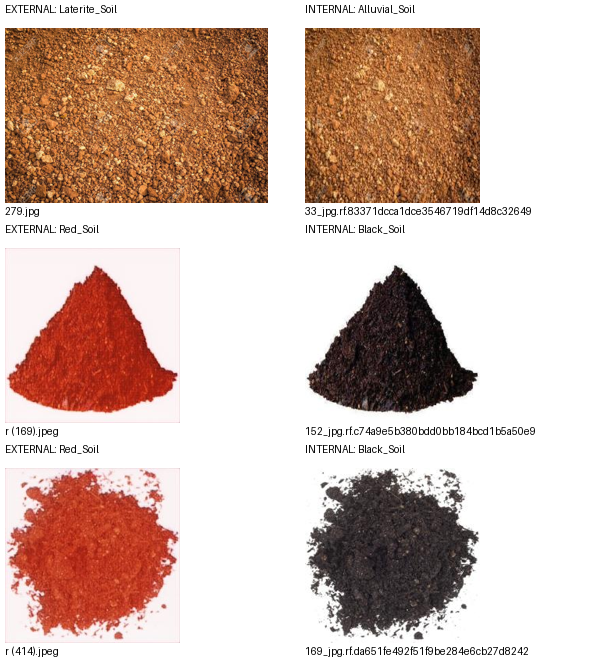

Review image saved: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/three_label_conflicts_review.jpg
CSV saved: /content/drive/MyDrive/KrishiTrust_AI_1/soil model/data/results/three_label_conflicts.csv
No images changed.


In [22]:

from pathlib import Path
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display

BASE = Path("/content/drive/MyDrive/KrishiTrust_AI_1/soil model/data")
CSV = BASE / "results" / "cross_dataset_near_duplicate_candidates.csv"
OUT = BASE / "results" / "three_label_conflicts_review.jpg"

df = pd.read_csv(CSV)
zero = df[df["phash_distance"] == 0].drop_duplicates(
    subset=["external_path", "internal_path"]
)

conflicts = zero[zero["external_class"] != zero["internal_class"]]

if conflicts.empty:
    print("No conflicting-label pairs found.")
else:
    print("Conflicting-label pairs:", len(conflicts))

    w, h = 300, 220
    sheet = Image.new("RGB", (w * 2, h * len(conflicts)), "white")
    draw = ImageDraw.Draw(sheet)

    for i, row in enumerate(conflicts.itertuples(index=False)):
        for side, (path, label) in enumerate([
            (row.external_path, f"EXTERNAL: {row.external_class}"),
            (row.internal_path, f"INTERNAL: {row.internal_class}")
        ]):
            x, y = side * w, i * h
            p = Path(path)

            draw.text((x + 5, y + 3), label, fill="black")
            if p.is_file():
                with Image.open(p) as im:
                    im = im.convert("RGB")
                    im.thumbnail((w - 10, h - 45))
                    sheet.paste(im, (x + 5, y + 28))
                draw.text((x + 5, y + h - 15), p.name[:42], fill="black")
            else:
                draw.text((x + 5, y + 40), "Image not found", fill="red")

    sheet.save(OUT)
    display(sheet)

    conflicts[[
        "external_path", "external_class",
        "internal_path", "internal_class", "phash_distance"
    ]].to_csv(BASE / "results" / "three_label_conflicts.csv", index=False)

    print("Review image saved:", OUT)
    print("CSV saved:", BASE / "results" / "three_label_conflicts.csv")
    print("No images changed.")
